# MAE +16 — sparse paired rollouts

We compared live online MLP and multitask Lasso controllers with dense and sparse paired feedback. Each arm used the same three seeds and walked the first **2,048 arrivals after the 8,000-arrival calibration** from [MAE +16 — Fixed versus rolling RankMe](MAE_O3_t_plus_16_Fixed_RankMe.ipynb).

- **Sparse cut live training time by 4.22× for MLP and 4.02× for Lasso.** Each sparse arm used 128 paired targets per seed, down from 2,033, while continuing to forecast and choose an action on every arrival.
- **Sparse Lasso had better sparse RankMe forecasts than sparse MLP.** RankMe RMSE skill moved from −6.61% to +0.91% against a zero-effect forecast. Pairwise action-order agreement rose from 56.64% to 65.45%. Dense MLP had the best RankMe RMSE skill at +6.72%.
- **More accurate RankMe forecasts did not reliably imply higher downstream probes.** Sparse Lasso finished 0.13 percentage points above sparse MLP on average, with gains on two seeds and a drop on the third. Against its own dense counterpart it lost 0.23 points on average, driven by a 1.15-point drop on seed 2028, where RankMe forecast skill improved slightly.

## How the comparison worked

At each arrival the predictor scored Skip, 0.25× and 1×. The existing O3 rule chose a live action from the predicted changes in current-image reconstruction loss and Fixed-128 RankMe. On an audit origin the learner state was saved before that action. After the next 15 images had arrived, three scratch branches tried the three initial actions and then shared the same 15-image continuation of 0.25× updates. One paired target therefore used 47 scratch optimizer steps. Branch outcomes were measured against the Skip branch. The live learner kept following its controller during the wait.

Dense feedback audited every origin whose full 16-arrival window fit in the pilot. Sparse feedback audited a preselected random origin in each eligible 16-arrival stratum. Both were scored at the same 128 origins per seed, on their own live learner states. The original Fixed RankMe notebook evaluated forecasts along archived actions. Here, the forecasts drove live training.

Each arm independently reloaded the registered learner and feature monitor. Lasso used the same 1,123 calibration origins, scaling and four regression targets as the MLP. Its separate group-penalized heads for 0.25× and 1× jointly predicted current-image loss, rolling loss, Fixed-128 RankMe and feature variance. The penalty was 0.002 and the starting online step was 0.2 before normalization by the feature norm. Skip is the zero-effect reference.

In [1]:
# Compressed JSON of the 12 completed run receipts, designs and summaries.
from base64 import b85decode
import json
import zlib

encoded_receipts = (
    'c-ri}S(9bQm8JJrVELR3^LeNrpeL!jO?oVAg9Q=+GF2czWrAIj%J|>4zJ1(J#68zN@`9{t^+O{;5Qw;gA0M{wVePg4?Zf}}zy6mG'
    '|MYJketh}*`H#QwZ(m<te*F63pZ+<xP(JD(m4CGV`tif3=bu0S@a6fp&%f$*%{lk+!}FIfpa0wQ&w6=qseSzLr(eH({(t$kFM9p2'
    'zx?+3m%olTxTlame)#&A=PzGhzW@5$m(M@G954IV=b!)O`>%g`4!L~zrw>28{1DSijjgAjYIv#7x&N4JD?a>?UtV0wKgAzD_44x5'
    'PcQL@occ>l{?kwGQ!4R?{^^GwK79P}<@uL?`Ths}Lm&6QeEz>*e*Dgdrl0@%!~gm6>9^1SO<%7^(YJs2&tE?O@$)awKY#aM{`CCy'
    '<vafrzWdMdyEo7IoxSqwcR&65<+~q#{q0ZRJ%9Q0SAEpiPkPW_{-}@mKmPRmMc;5d*LTl<{qgf}-~DPI`}N~@FVCOsE#K*rKL7Uh'
    'yI=qHm+yYo0KWVA<@w7mFJHd<`rGqwFZ#UCUw{31%+rVe{pIIhpMU)Bw?Dmn_vPh}pTGY0!WYbUJpc0JcR#&6|Mu4}FW>$7*Iz#W'
    'rjaqa`Bfio*6EzrfBV34GQZD1hM)4w4=<mdd-Ns7^h0egy}9QQeRz4P-uwFF52>`G1!y&d=NIon%s+kl<XZnppU<A)lR{15x!3gR'
    'r&wESKbESmD4$%4KfQeV@yF*MKKYmOlY4&t^!&;H^ixkMCVgP{Kj!$ub2&b#>63nZuI^KJKe*@q!;c!@r%xffqK|sXKRkcxwY%J6'
    'e+ji|NcGue-}L)WJ(TeB{2a@Nzx_>1^4CBA`T5KL!=u_F*`EI8>&v@a`bC@f*r4B!Mf>niv89h6{`!|6wKDpz;(FKXet!PT*Owo^'
    '|N5d$%}3>$o?7<WbxAXjeANJcd;a6g>nr~4!{=ZA^4H(A$Dc|sq2=UU<1Y>2!&t$u-)lL)|MaI{KY!vdxca1*#G0bkL(i`lvRl4C'
    '2BR}po_cRJrrMic(W<`nFVCN~J-+`*PpG-lmQS%gMNL@I_xa#UiyuF57{34W^XFfFd->)07rx6q)e<<fy@l3NjagIp^2?8Z`Bg9a'
    '{x4sC{o&>NzkK?Q=YPt2O>&WyD>-UVnqGaxKf5RA8BKOQg;@3bR6p{=-hI->X)*eog3J6c=;^cm5t8;-^Zmb$bNcmPKL7ml@m2p^'
    'o@z*X@)(_FEH&QPv}LLfB?Ucsj&Z*4`Hx>-UjF>TV2}5Pr_l78;>Ta<qkdF<bw0N7SNX4hn-=IF+!gj;cbme;@)SHztf|+idw6eG'
    '^jd1xneko|r@?J@MbrKXy(CSFX14Ww-4x-eC+}L+w3nER9{he&gr*mTssrD<)3VgO*%Tq_1)kB%0<`wdrqEjGBlUeg`TTZI1npt%'
    'x*THDH@cdRJrT5e&1-l2)N>y{%w0<xOVwV{*S6KB_(ORrUe8`M3qdc|HKQ5vAr@C;8e-HAEW2Hi_2%S?Zl0nEkGYn&o8fPBre5vi'
    'zkL{w`4^@md+j@4wD)DZT(<j5bNW~PGClRI0~B>2l5Z)8zfHsV_9OnFTTjo|l0L?1wz?~CJ|kj6w9z#qQL`mO^0#RdFCP+RH!D-F'
    'g>JR9ax)T_WHPjsn!Y6W`Zpfz%U{{G|9tFnu4l{+_rpI8vv_}b&+YR4xy|)_k;_h($)`W*(ti1ie%N!){^N(=KL1%a;9_UHrxZ%<'
    '+WtDRwR;ygJ3DHEweZbnY(s18+?%ako-{MHWSKkmW$BBZEff4y^j-21oYQ`&8*>-3#-fjq!Qv}J{oCpQH%+F@D<-U!&ZK<S75n-5'
    'XP)oVU%!0)^~-d9K0W`U>*jmg_A*ml*IV{7ka}xq=dan7f3`=FS(5?N3D$-Qnd$!g)34|6la5~2J*!iYa?_dl@b%|k|MktUldP%s'
    'f0TjKz~bS8yx6>d{q*w7%Q5fTsc-(~Q~2F?|MH*y)A9TI_Aia$U$riOdii3%)V|6o2G@^&VJ-gnr{B!WaWYmiz$JE#Qr9jM^OqO7'
    'jB?|i&9`IB{moz6A77q-`swqh@9b0TC6xmcnpRVLKBvFEF)nYX*E`#d*ZI}Pmzndj6I#Erm|)#eDFh9$$awY3{N^XQH(r-i4mk$d'
    'ox2IH4KGF~!OJhgqOB%4`qbY1eK)^J=I-_Hd^^E1fKJ!4@5jIV&I#6~i35E<twq*UBko>yQ0Itg9h>%Ivb&BMRyero>fW$B-M&Ew'
    'Npr0$@x${cE<(E}KZcL~qtpNR|KpFdKf!+LF8{p#3ESV?zcQTP@%E>$pYHEo|N8&O_q_e{`u%^;pKy+7|Hq$C7cS2l#+dy%uKREB'
    '@6OBpZ*S+?zj@8ux$&F%zMUDroGrh2*Y)50Sd(z`X{*n=otyhL^$+fg_y72B{^ov0{F@nhZ_eKTCVw}(;bsr-{<wF4zWQyrJjv^h'
    'e>=msV+wb><@GGBcbdQaFKnLY{+v8=%5L|lzl_Y^>`}M1D*kTXuOo4n_wV<J|J}RHf8(8d3;5o6-<zq`bNxLhBHUQx^-kW;U$|Mh'
    '_jk_KHn|&%<CZ)A?RQ@-+qX}WTiUbTpKy8K+q1M=6aUUD-'
    'rH?{^UC`(6W+{U*gWg{w)Ho&wmLQId&4i!<^3w(-womXl(4j^;byJxZ-TcLW;fFCjq~Q0E9KugdDqkR{ycr#UWL2gxyy>IcT(8S>'
    '(y@i&1c=8qPJ(vEq?pfukvs1Dz~+!;b#4AS1N406o0q(A34L<TV;P+ulD)3{U!Gg`hoWz>c7V){o~%v{?uI0*tcfptzGilv*H*2#'
    '9JTt?cDeqyYAmPf9}rb@NewPb=|)`AAVsO-MgoAeUesBy0aH=#~p6YcUW3Df4=tK-+600!_AH5Ha=vyiICRTYBl1uH|Ll4fZuxXZ'
    '=W;V+@}6b6m|7b{hLpDeeddK4_nXJ-R+W{Ra*a-U)*}T_~5;m!r$2zzl@k}pW5AxA>8=ryRn2fGal~zeg94jv_C(7u|v=Q`mZw=@'
    'cpM>|N6^sWCVO@;bZafqt7!jPrl?$E;z(gN{T*&POZf11A#0`%BA<xa!s+>4}FaxSC=xmQZm6eN#O9*Le8ypy^geR`S^$Olznz7x'
    'ze34*;NL3&Hv`7R9ej+bA2Lz!pHt!f2Csg{mYjxzkd1t>tFwDBlV%S*kjTtdmtaJG5J`1t<7o(Bx)JF53ajTKGMEAka_;}>!1Jf{'
    'N?$FpI^QwJvqw*{QH}Pv`rdW6d#|oMj<>o$`MvEJTkRMt%3X^>8IbGzx?s#w__TapjcYVp=hRaNh!zUXUX+go6EkEAktud{pIJ+z'
    'r4J8n{zI=9$X^x=!z9%Vr)#LZ^_4)J2UswmtX(imtTJG`~LRvX4vI2>_3p?uT_&(^j@v6?;1Ei4XM@MBXy<Yajrw>MO0Drb)6x&r'
    'bi66e_RYr3zbSDVV8=%`8s~*QgOLxp%OW-*fltNFNu6@Jncv4d+e7-NacR!oz)$JMv`3Bzm}t(Rg+I8R9Ee(R^t!k!8KVeX!JR!<'
    'A;S*uH%84Pqp3+-X<-@5?Ub@mz=Bhcq<!H1MiwVeQ)mmGI+Ae*THLkn$BI;glSjSWAMJDqH$?0H5!d4EoZ-Y9mU%8(0WkqzGDnjQ'
    '#6pS6H_?6tKsX}^!r4%Ra=E+v$yKV>xk>!nG|bCm*H2x*gk=g%3d_5hu3C5MiF%uG<NT`A$`&FtRFz%r7zR6^_pEd-s+-ul!g&>h'
    ';^2uOUnh2vFHVJBpX#~E602F*!qbcTqDv3h?ghmarFdQGvUam=Gff$B(khAX$dul+I4j`emz{|)D-OjO=YcP|7cyboH@!6>H}AYm'
    '+U_))_Ud<V;c+LWjX`Z>h7#?dmVmVZ2pp~4?R$Y)tk$hh%Bovi=1ND**y&FV*A(Dt5)4}_+vj-PR|jGc0$%)J^AJ2XPsSFT%+hi@'
    '%(rv2O&~4Ow_@2N8F6w`?j(^+9W_4f<7*%xrw9BaZc>vOns?@_4X;Q>e;BNHTKeY@}_G@<0yq^&tdrh`mNXG%WQb<q7=pl%Jz2|E'
    '$zRkop~{zKDxyNII~|GJ7|rgl*vy$m0pafKC5%XEuSDa4ly^DzF4mxyFgaOfw0h4DB7H>CkT2>t&vW0;@))A0O`<c*7O7F6&L&Cs'
    'jA#PfUJ%-spd>8DT8zDf_l3Ib#ZaYw<xVs(a_GzT6BAES<xc1swJ!PCqiFZAMK5jbi#Acw!_s3#|P?9qQn!a9M{X?^<{N?fq8K3<'
    'fz>$_vE;}%29}JnvCu42kzi?vUPa7*O=m%K^;Q*4!XIkc0x&;?GrIFP2PxZ0(Wd$jawdvPu@}S*3?|aUstEM%S<NLnF6IhR?%re<'
    'bPC0QJCWUa`+f6t-r3S5_IU&-2RwcZM$HmHJIgHSWn#mo=T|BZ|g44-2;w;!(Fv7{$l_A%KQMD(Ycowk~zS3|Lgzc0_Xq)AS`w5I'
    'mnyz+`b?Mnx=Z#ZyiX^qxNsdxUUDV6OLOUpHlD0eXL1L_!P4Ky1jHhZU-Nh*2hITP_F8>)&bCR`Z2XdyI+f}eJVqtL%rDk8eDEEG'
    ';Fo@U7t6ChORYm-~eQd7q(x<8bg<xjkos0Ug$7^Ves4rl@jP>_;Gpn;^OMNiY8kID<8H$QlOS^qJ4;`es6k?eHXkAu1oli+QY|#%'
    'g5Kh%M@uUYPp|&d+ww!0H_gjlA$?{uFS7KQddFJFyshcM!)jfLeq7tje-Ma2iKelYNa~;dIZ*GHF9lHz)IR)rJvWe4kY_scaP3{)'
    '#R=w9@JJyGPTjl-1als2=h=aW=YpAuQRwfvkjj`-z4{#%j;Nr$5q&}K3JQWpRTX0&fO0xCu*CHi&Hm|(+<?B)3Q<gUK)JOdeL$z{'
    'E|n~`#7>dCS<I1a`g}0T-WjU`|*4EIXZP7*o(v34x=OA6QGi;3eLkSR?(8kzm;P_30y}k9yZ?sFpW&ETBL-(^!DW!gT0VR#&r&36'
    'KcB!q9*w}x-Kq*Z>#IdfjFu1mSyw`p5<_5xVmEo!j=~sXSf=jjVt#?Unk=<CSQhB7m-}Or0b|G-F@9ML<8C<nl;(1W6JbuwvM)Z?'
    '0CPo!`DT!^44VT9Ebqjx>~hyb7<%4+SHwmNt6?`-aAQ-Qs-F8wfCU!4wIt*K_`L;qRHJ^`a6tHn?pv9xDfAr_;Kc+2RszUd)fUlu'
    'ATsdOLvLbqv7!n&qHp29!gGgIIjQYBh=VsY<smx^SpI*cnMi#2joaC=bzoL!2-l;AT@`(92()HJY|q0-d${_-m=<1U_fjjy5<y{A'
    'A`W-#qP;jCgrgly~ov#*q*{>A8Y3cw`65C_hwku@fM&xjSy#Fr+1vVu5Xo-PLQpD#a(B=q~(p3xj*oq@U-RJ97d67Ri6=UXB<)AV'
    'h8Eq>Px}pw!n>Oo3B;#R;vX8$*<#GFtnlLr0SgN<~!ahgC*BDdamo%t`AV-B1@v}?*N}>ZXgYnAL_bc@<IQQgIWh$mS7>P;j8Yw('
    '8mpEFk50)hMvlL_sFBlvOrNzkBrZOZN%M?`zl+K%>lR!zU9^ID^O9mjIBTR&JpjiC!;~vc9CM&yE>P#TrOU0Kb0lJ2lEz0wY8@SN'
    '=!>D$3}+B)%no6#&9#TLP&pglnvK(cWg<BfE)#c$N9`NsV8HvF9>lt`1~YykbH>6!SV`U{@|vg83|kyi>N)Rv8?kXtTcc;#mauhX'
    'gUg7NEtiD$#N^N;}45V%bByGDU@rbT|DMq9!`<Plm$`Dpco)69W}jA+lynC4R?I}u$fg<2*&@Gaf;_Y&~0nTK&`hQYiavQ<B;=Tt'
    '|^9;7Morlq@#oVDkNEsx!0WQ(w4<AUpR%Zim@WT7Wb_}4Xt)O?htuhT@Ie?wtTI&%&y5&c6s@c3tqQn%+u|b`{T_Hbe-sYIkH4zE'
    '0Y=IjW?jn8j<3WV-y@l5U;w4Ti>Lp04!>g0S3nJXfrucfv|Cu^=y7)@;xr4Zgj0IKI$-<pyT9RgI~oPx!e4uF3+tdgJueH6o%8YR'
    'jD{mGju6ykImizo?nZlF!#u_njz3*99z=1(fZoez9Si>FsKoZwz&$NCWYLdY_|NI%QLi9q9FuX%US_RD_)(>KG%;9pFH_-9js%;t'
    'Z@*UlTnq~nWMw<$)IK2eOK1TGh>md1tc#wVdN+rfj@=}hfwDC`UHI$ZSfhNs8#=9%gn5cOgD}(wqK@cbq)w?JqN#Ma+k*r)ODbBB'
    'hKQW#N|0CjT|U<MA3f9BReC<5oo(yK7}9J*|($5VU=XoQIvO}$g>iY`{6>7LY5aD>u}!c+HH=kkbD<~HL`pD7{2`+Z&k<N_f^EAQ'
    '<BLLDrg~-G4`HZL{f8XgT@7N8GQ^Z^IrfaE69`+1CVtDEpp;WpD1jRHCP0?!+DJKH7M3k*6lGZua;gGL*A6!;AOz2i!lS2rZkY{a'
    '~~#6;ZDaU1uouemJr`=ktHM`w;F>b38&K*EY+28Tey%nCP)iLphK=I;PoHIMb3gwR4_DcP3trjMyoW3XDqWhte2-F0>>c-j`YRrm'
    'nm7DT{<iDSsF~h?HrW`eKA`pnSqR98Scs}lE+ORmn}9eh#t5T3(D)zJKcSj)4Y2*5Bg60e%;Y_W_0CX%4j~K#Bxbd<+j-PWF`r7E'
    'Ls4`Z=a(P<3#Ib&Ga&@XFd`a65wgT!(1u$Bz2<ji)$tNb#h#z)uz|B2^2BLezR5~W+CaKzxevaEw@c#l%Z+)Y<G`vJChzG1w-y@Q'
    'QA7HQ(0Eb0mCl|Sp4u@w4LR!lcmroLtbB9x@t&->&VkFP-bOI2REA$(-oSpIg%0<!4`F(Od?wzr#w%8RA)(W73?6j&t;rWJSSJ0o'
    'NgOMUHwe9Lbru(O`U?c%I$E)=$Tr#U?3mkroLC?df@Yrqq+<`t}K1UW6ji-wd?CRI3%S&&-Y4!%&n8M8ku5LY7(A{XSiH6)!0TVw'
    '5^n7UaH7_t&Z@5eCTkMx%g%9wA{J@b;z#UCa+GbzD}>zgga~MXfwAiZ;&K_CHYsgPX0q?Qj>*)rKtSy#HwO%&4icF-pS3ajw)f4J'
    'bXQ&W=`J5QNax4Dj1Dol-@3$PFa@YbiHWO6Itmp$`K<})~yxEmmJx)<>XreUFMwXNt_vF&pD+yiRIFBY;v;XYh_+_ID^xi%`&65w'
    'I{Kq9dZ8zOFxI6N9`Q#k+Yz3JeZ@Z${cEc?n<J%E!jL;r`&5C+ehY6VKYe+jSMit+T2%dH-Z!ye1h`B*Y?G#Yr5#HmF!wlFTE@mK'
    '_(|>jE^Rsp0bge?-c7~F^?E*ec5VH%8Av4W@>sP)r6-&;xFL^$(pTmgbGax3B*E})XofrzKagwW-U|Ya$%9WUf6u?qhQ%+%Vv(d1'
    'BbQEXIh>CPijE{QkSDc!)YB+j7FrNdTTiAX=!>iVCyrKdrH&U#5iaHs8U*X{Bm8@kk=<bM^Ay6HiMxq#wnCNqDifjONyI%oE&<6y'
    'PRa&ltw{Rewwa+d3N$($lI;XuVa4@%4Pr$6jhFx6{lO55RIRBfS2K?bv;p5RyTX5&zP|u*$Vn8HHErCaGW>!okl9T6PRN<Muecfr'
    'mxZla9n~V^-VdQ#<D>ER*p^W$5ZiPx)gdKmehTId4OfK$Vg?Jbbps(ZB#b>T1Pn&9bgJK;QI8ERLnXejbltd<uE|HODfepOxUKRh'
    '=-#!2gV{_?F>>BD(J*0RMFe7jxwl?RZXSJTI>F><jknZ$(#~vdM$sTrn1g2Q@4vunmz#+V~(D>h-Of?Dw}zoCeb1}Y`tgFe4c4x%'
    '@}QkRH^zkzgBx+j$iQ*VP_b*<N->c)I*vS^HKcT{L9jj<knH^LGIxU5zO7F9P1R)x}L5lX5Z@BG0q`OBn{PXy3A#hb-HfHuid&Dz'
    't>b8$y5U|Oo&FMJui>q#3smfR(8dR(`q}7E}jzbHraFvB+GiP2P~AdcR_GDKZY+88nkuvKxC^fqYo=Ai7q?rRMc$|b?MBCK5d2J='
    'nz~v4jyNR`~*>UJ#he_nKCWoy1Qfv*1je^jZG7*v1SH8)<e!#0@#ALe>t{om7=2bXZ3JTI@nJ)A5SXclTlsRBsaO5d+ZnvdaX6k;'
    'd+5f)2JxJb9=2b<2smyiP4tL^{j~Du**`&-40A=yFS4xLr8v7MniV5#WO>gm{e=~1&kEdb`#zQaE*zooVN1tIOMlbX*M)QiA%c=U'
    'PO;iYSzn}oQW0gUh1Gtcew2MW%TP56}L+#<jf<#X+VaoRVDL6(QpxG9bu|2Hch^+Ae;0)-5Hidu0Dz5<TiFkGYp2R8ycgIx)vFlO'
    'kxakbQyeG+k9PqM=<4IBPB)rvXzm(-M&sO_?$?7YI6sW1Yx4MJjMOSN0Ofp8weZlutJ2{<7x7#?~;>HsHzM9ilFLld1wRY3-D2;^'
    '>*fY!EWg)uVn7GMLESW2@hBIZY{GG>={SI+o#mGsi+uSgo2aamd`SF=vLy%SOV?*>-hZ&LjnSYEx=JB=o&$^W?kPPOOW^8CLVPo3'
    '&<CbnzCZeXu%f)lLxiNA4NDkEFtKj{~2XilI66TmmW#kT}B_5LAu^A&z942ln%$|>(XItoZz;=z#N&dY&oVxc9qL!;vzGtaqi8CL'
    '%NI>Guc~36C`G2+|$U@%kQrwp-8b^{ms72O*!y?)RCG$&hBs-K;US8=JsEg6d?|AIKC0|wVx%$OuW(o=E!Q*yulzDYX$5u`1PYCi'
    'l;4;)49#UHND^0A)_H>$tIi+a6~>j%pHVjGM{<pvQgV2x+cXRhxwKn_T*|oX#$g3TYg}pc$IpBFe~AWbQ2yt`HOtTGxT*;t~H?Q^'
    'Yn&S^DUd^!!9#B&;*3L$37szFe|fqCW;*nPJ>uC@gfm{0my)V4o^k#F7an2SE~JcGk%@zWla~{DWHrztp7}1-~cELi(DBSr;{U0?'
    'bLDCD*EeT8n28`(+?E?raTeIZFQiljhPQ~=URq|lC{VAygq|pVPZUm5dBZV;cL`lM?-sjK${n+fFm|Y;C?!6G<Yi`V51_z_EE&nD'
    'Q@e4mtY!<eZ$ZV??L|^q5<n7NuhKZe^`}AZP+q;6PGcOU{xOhNG%R1;X3P}ec%iEWn9mhCk7q_WCyFRU9!dn@Z7q_^xTPZ-L!p*)'
    'p#ZrH<fyMfV2eCDqN9;CFO$o=(FyOIpZF%$R(_kg^>#r)F37D!xCn#3YY>2sDKAA^RxwgpY|D+MiJ7HrzNi**nWU%WW6tgUz#8f*'
    's_qGJTeQzIglF%up)ue+gMPYmzE=$!pv)Cs)dRbiD~UeImK(QpP-$4AMZ0j%@U^H>hV5cwW7{{eSozC)O6SAA|-a>AtsPl#;;Q1D'
    '`4?951@hTxDwfR@JnN3$lLaSUO?i;&F(3{Ze@S;-7G~p<L_*FGRhuugD&ImOB2dD)m5UsQw>2fqnT_~PL0m?|MCvATvKt(SOii%5'
    'vIxDAzB;_#;<YY_@_LA>{~q>7%~}*jI$1~`hp7U{?3FN<dG=*)lD|fzXL~<TTiOIw!XQ(GD}a4$b5x~3??_JD}w^9U+*1#E^`7Xk'
    'A%i(e4*+N{L^X<{ch|_)01f8A!r{l)&a~2mN;#P>0hU-0K#(EGR3$&Q6-kGk^z@t#|i9lgP~>o>{h)ox3l#HTcvXZrafH}R`MxU<'
    ')IEjf>rdd*oMfxV;(4l%f11FQCgPW_Vfw)(KzD3(MM2x)&Y{&Cs*OFc1-8s%Zn%@Roh595&O#>i5ECkzX!h`xH6gt6hYMKIvgIU8'
    'U0z3UPfJXEQLsr!UD+b9UdtFB`{8)$Uu265wumtQg*qJYtjvNlvy0R)CKsZfSp{oPHk(?ffyfTSu>!*xQlV8A*GA&I1c2qyj^;r*'
    'V5=-anKbNa{U2BXj>;8z?D?mFJ#!@tQ)r_=EC*>2)ny`OJB1pOv_s$XNv=UzzL7NQQDg<O5R<&nmk$_<T=MtVN^8BCeQ~dHj!yvd'
    'p?Pa8dRQ)JO_Q&?G(6216UU5!fvB4IXEltO|uQVp9Va9oO!tfd1E-2EwtSeP<@9SiV_<znTgBr1T}_5<PKOv_@i~XRCbUelhmfel'
    'DvgxzLK)O<P3EaEitvaeFH$W6yqCg6<la>WTE2{MowX<fCP^~J`{8x5I@IVVxcEl=ruA13kqeQ-sm~U$HAlQps0?7QFm9*GsJZVk'
    'v9KmUYW=M@ZGu(b(<!$KVj!OgM2%@clO^%gn4KFkM0r;r>z}Nxn=Skz+}mKw^^m>&|*fiwm|bQ)ka{KOI%M3=77vzzmf6m%sH)D*'
    '^bmYd?Yuez=3-T?Bv+SGMwNfGyM@-ny|S60yS)quv)q>_fKa->G&DuN(+B^gc_IoN5>_k)61XObZ5OBd{}QSY?9^~KraT7@6P$`5'
    'NZjhCexorbK$b;q6>!e-^lcX>X}H<O6@aJ%mHM2d4wg%0q@hB3wE}#5RrkplT-hW5h@y`-V65G7HZmMUFW*OwHX?~=C%6<L|N0#6'
    '(fT=A~%`{WGks#%MG}gpy-x0BMgk3cV`gYG#ml;a3(2)cf1XNjmTGfSpE#R#tfY`_0)_rz_|^oR`!P+2^Bkv&Uv<w(9{byTyK{Vz'
    'no!B<udxBR9f%|-sXS;XvIdK&;A|`v|4KGko^Y^IXqVa6XIIAwUwsqO&1gpkirF+DP50kt51o*W^}U=$y^>FE-StYu_;<}9FKzOI'
    'Ehs2xKECCSvOVCra=zJdn<L#90Vz3O>ng!AZ=j%wEL9~C?=CnoFzovD4h=E2-yANO2lRMT=8!=XUdIm>$n4YRR~qVCG3olz76;_0'
    'i1z8`sqisMk%*YR1AL8MNI;a=Fd)G6=tnFa0hELb;H#Q)Q7a-YWNfw<T%EW?K}{IP!T8ylxf;yv$=1{{|9h!bmWdq4jFkoqy*T%1'
    '7us7piTo5m^91}J+wz3bpT;VK0}B6YJg;&R#5=WJpiiSLd%VI7l@bUW82n3s8HE}5CN2l5c2_SU&Os9h+g-B>+vErJ?(vO_vei0='
    'x6{(!kwG^W&CT*L$?l%*F4<t?jrWV&+?03-vPvdGyzfu?Xwvz8S+-{Z2_~g-axweWci|;SiGG&i$@uJDt52%Ft@``el`6%qBL&j^'
    'Zbq-pdW*odoKgg;TNWT-+E<7?Jz?2Nh#F&(KoXXW411UY^8!x>SP0lV=>5q_RHYIIt;KG))*>{zw;ghCPIGM%;U!VE5zd1c1jC$H'
    ';t*6;n#_v3KO6%UN?ca>MTfwgjr6*bRguqH6u|q9)j!ar@pQMG%oQ%5iLwRCMR4!1ya=a#YadOyv5vlcbt8sFxgfD`U>j1tsg*BO'
    'z(r9pv%aX(HKzlSdIEAH1C(HuPo%U=B|;`?piGlpB;4>@WD3`OO4;i^c1RXZC1drIF06D8DGd4Hk;o-Wf*_oPX`XKQCFVqNX7(R#'
    '=nZe2v^;KO+GMVqcakmZnD<8t@oh47Om6NH+uQvv?>X3NTN`y_pS!deGknBMP7LulXQfNGd{FpYQVDB!LOi7Fb`+ABrGC2#-6iw6'
    'jg`~q<mbSH1g1~Rv|E%6_i3dL$s<Skcj2XQ`{|h-h9LKoe3W4Scoa>TF&m`y5(i<&SRpT1)O>29|&Hs+U@`gZ^23ho@R>7^eT_4r'
    '86>^Mm89~XA{4h$<dM1#w1(hXEb`0`ir>%{$hIWapi}hqj<~*1uNeT&#h3r=!W7nMwaygP=L$euYpy%({-lJL?@RBAa5KWx+gF?-'
    'ntTUnXrDmK!tN;Uend}%yB`#lE@**_tujaYtG?^xUf2tH60klRp9F>mN{#DB~@-e%e3(Wo3nIQUy}A%)K0XWxz>(cUpDk4-M5GnT'
    ';Lj-#AVijh>_A0U@I&74hWL<{LGr;X5&Dakm*PSRM{u_%i*^u9>Lp=>!6V~fI$B}<;6aEWAsSitg=Y}Tt;74HB+!EhSZAA9FN0Z('
    'uhmZo~Sl&tUVYh`dzVe>7-4e4KYHBo%MZT19jk6x|Sk@_H9O6yirR6W*4=U%i#MeRHPH3P?kG7K@N*Uv6KkPa;km<P?8x1)=~*;D'
    'P2$hlk1s;2?fZwNLd|@W`ZjPG<obt1B{2BfQH&g|5&^h8}BjkN1D-K<0tt2XuF3;$k6V2n<|f>XKAt|PvJ)|N{F(Ys5N-<Fl%fcx'
    'wzyEQEEM(Gh|hOOn?cS|K*m|V=gOP1o`sgn|aCpylaZ~O>f5m-gF}13@DycEN(@P>E(EUCmepVZ0iP0PK2zJIa9@*ToawflR{%5V'
    'g;Asr=^1o1hpPp_&|}*^?<HI$M`@yZ(6^D0h7!R?QWcQokVDhWK>|<=zcx>@hI(DwO!ZR1e!D}69Jbu(BkC@@}kH>sSo>>4v^AOW'
    'Z?vLP`k2eyNecJED14s4mCHkK2NL&|AuCeMxG7Xhn%no`5Op}IKk|JlDJ(J4vwzN;L9?{Swel=CpTIENtDZufMUUMyBj~^9qcVqk'
    '~*mJieEcmNv?xCwG)|B+$4EWM}n*((_=e9_525W7w(334N*v_ub#kJuT2H<^P1%$O-s1}Un}@EvJ>DV&^$vY;_HkDNTk_l`T!liN'
    's?IqD@pPetV!i?)bO?f@im#ktKnG(i28n51&2#;qLY&`XysiO>~LzE;S1csZFk~(@jB^)<>d6ft`&7M^eux&lSkbL%N0FFI9l3;W'
    'E*ZDpstDXvJsy|aFzXRq4RW?^#gdd^VDF`vw8x%uMP4GXZ@&jewS=Vt8OCn0BJ?8oc$Aytbh+bMvGkHr71yITwAf0XoKSwL+wLSY'
    'Ty?E4fy;%uH4Z;VB{dyeCKDP9B>?z2%biP6xJ+%dOmoyaF}3~n}{7fFvvzs+NFnAk>i@U;ig-+9VrrT;ExIlz`80n_Mc5hs7Q-Po'
    '>vf6O4zHo_VR|gft)aGLwMAN|35ofDU-5<v@u@Jua;|d^LA2N$r06)MI89r#t$>3I=i+U)V6>>H;!DJ)(3nN;6XTeX!u$eO38s*('
    '@W)~%#H>+${O_-y3em(Pi;&70QwML3vvT^NYY=|+2QnTY!A?JE-hfRvL<n6_>Bm`nLZT3XWTphI7ygIGV(9eXwU$w>B>ZRJzbA)U'
    'v<EOu5~77bi{;5@JPa<m9w#86DZbd^)cO^#ERwY!Gr=vo~)d(v}vCPzSp>>XiWoCJ54!tkJ!BtfL)m8dh=_X9*B4_-h;Qt4<|5H%'
    'd@`6Karhb0&!RTnIp9HE5Hw;WNLt$EQ3Ef003x}k>)oUvTDt})*XIXfwn|?%F}`si+r|WOlH2_WV*tcW!~WQ6b_To251syk{SL9k'
    '}IGFjIMN@CHIz10FMZl#ROT}*@?wMv2ek9YAdw04YDrsHiEACS$w&*?X<YGqJw|~m}H|hFT=lChZQBst_8F{mzFnJ$!>fD^yQf^H'
    ';;jKAA_N}C|<qjR#tg_`3a=8=nb%**u%4<yN}~cAeYy9W@kuKkE=)KVIW>K_+ZISkgR!qhtWbvJqza#-kKvdY<VS5&j=YDcRd12y'
    'n_ejSgf>k0FtJUt^h`6Gz|XN_3&X?^hcq@8sw&dp)JspzaUY#-a!s{nP>fIq;s=S0fmWiCSp|}ExkO$25JSYQg)%#p&2#kw>lhFz'
    '{dBT_yMoWx}fmeHR}_~0n{0aC;B$sI#=#!hzv#&<_%Fg-kSpb`-HL$ex2J#=svDFlw^4`-d{S{EkDjwEQ$AlMOj}5I;(-s7OJe1c'
    '-E2pY}z8w;Q2KLl$kl;Dlj9)a`xuwbF3$b5bffJ_9cInVpux-$}FrO96nXIp;n+C8MoyDrYAigB6110_;_YeA-Y?6Hv#+-YtA<{Q'
    'hX4G9des;#5xf*48@ryhRe`XTDQhRi+o~AMgi0sKB1Ac9kprgqLYS9In-?v<pwKJqHt-Xb!(V^<JZ;BoE{?21`&_j7a^&|XkP|jm'
    'W^F<whS<LQbise0}XN=N|;6mmA0lw)|Fx$xZpTA2b+Ne>9S;JuX7KEETA3TwEISSk}hQm`?@h8=DF^hy4p8*BCvZmQ;Y3>&<Gg;l'
    '{SGDqL%vxjn!s01}Y?Ng3%~TC|9hhI4@gb$*RK)(ku~usI6MEoGKZF8ng#oM!swbq^B@LDr|ktXLlYoEAqs<&a{b9AdgtlzjW<n8'
    '6}h_w8bOWO}5-Rm4cKN7YcTFas(guJo>m$bKH!dWXOsI0VqPGL#`c#l#hStPnC|qW~5IFy9mlRnICgniI}-8XNwDrodLv6iN<=p-'
    'aE!%5+NuhM=;$LxPHm<S}LSnA7Dvd1wjnangKjd{u1OcA)C=Ic!wlA*+mV~g{14K5?TbLCn6%Ta``4rj?V$K4$ikcc;`IO*g|76n'
    'BQ>s1nWG1q159HpXg88MXrH@uwj1Z@ER)}g(YLU(cL#9&tk;GdRL=BRyP2LW)3n@D;Le!&)Rdkx8;vQz@#e+*?>R)`Y$iv|F@Sfp'
    'MU!N@}tR%fBo=JKRy5a^@ZoVS6Ll8!;i?UdaAA$mDO^v>F-5WVN|3Oo4glc(?(=9_@_oAN#bY_ueFQFYI-V|4;k);rRRX$iLCY~#'
    'YZ?01}DciTWhQ)`6w{26ysG1D~Z)upCD~$FnklYz`FcDHCF!z(O4zur9qoSI@+K28mpxF6bmp(ILLQ1OjD(Y`(|`{-A!>Yjn)Wvj'
    'UgpgQ+%tU+O9K9isjAUw=-OfNr`q#`<LH2#bqh5TDS))*&MmJ|Cqk2KLB7<m}n*byYy9eN<`tJ;S%1c$b?hjF5GDJyw#ArS2SH~r'
    '-pY_0o^w==T=I3;Q`ev|E~Vhw{=tfgBn|pXiNFOTe-_`6)W94+OT_-yR|yu`&zQ$9krv!bYFLxLjH{o?yX)}*y;)1Dm<;U<NP;OJ'
    'MVYty&jWa{`P)u!kq%+y?T>d>QsgsoiG1JX)oNUW9|RAyVK|1oY1Srakx=_di&dOQBi*VjJK<?(!9M_ZoJhpd#jY`-+3Z;nW?wW^'
    '}h0H_=cipxU+J%mhoPjGko(z>~&B7-V^`tuk81j_VDBO(EYn;AiDqI|M-6w3;x*L-Rt3A@9ec2pZ^^*d{y3iPZ!m{qm$|%n3I(f^'
    'Y7Ua;Tt;S{}HF-KW4v&-{Euo-toV8v-@v;p8tl@Y}i^`zfiUeOP%B2x9<MG)9Sj1yqACEyTU*4B;V2n5C8Bu_iEGra#!wd%e|L*R'
    'Y46~t<#nAyZ<}q^;>%`+<1xM?>dcc8?&s=<I0QJc{~1%_vJ5MP*`}5;lZ62-t|4No~XM~1NArF>8lU+>ecxh4cc(=<KL>XhK0uJt'
    ')}a(qI$T|D82pf+qgDdcGIiZ?Qguz@MgsReBaxj-F}C^8A-VD^20m3(%+2j-iC&YQthoT>~A7&_eKXd+^BH7tJ?fZUloSh=*!1oG'
    'yyApRmug08hJ#hbV#Yf>rLM%G()u097;a4+Q6|3L%S8@ZxmL2da6bgh)NXlW8vc;@)MW{)NCjpM(0-&tMLi?Hecpn>0>TW-LS&vk'
    'M_E&(J<oFH)s>J;+3g7#%hV%0QD6=GrD8=1}b`*28R2cx~nduyXxCh{-3(5d)?LFBc1vms=6A20mlr<eDp0JP2*7u8Dl;01?w6x%'
    'xXr1?UBxzIOwC@_aJ@geZ%?|LF|GeDzGA+R7t6$iv@HYmWr#C&Qf?4QfQP%TR1o+2WN;!4o%0EezoP~N2ABgMlb`aZ8W--WExy(b'
    '5W9B5}QLBj#dOvL{7;dI%+fyMkAo8*RF+)>MD|<xzj9QO(K3&V<P=R(P&LvT*J770dC+#1ok<e+ZnPanIuX9<+{Of7>)^YwNiM?@'
    'c;={(`qf;D4&)`G*?kVOW<)K%r-#okgkLJp?;%Z^JsejOOw1FC(iC0qk4gJF}Akh45TKB+ElhOdYHX>5Kkd5ts^IU`iSbPvHn4o('
    'hT`L8<xTPf^BUEFIaOP(%Z@*15pL|V$hx<V!;lG^m1)D17W|>-h<v-`)ryFD&m2CODVQq=_c=WR|lpIl4obsYo~M|cz}*9r-la;#'
    '70MrmK&fU2>6v(3=S#{t^lP7#qa1Qfj^?W8R}%60nQB;PN%=apY|=))gfmA$rpkq{tZWXbHLF+XB;5c4IG`z(xgPRa6EZ>3grMOX'
    '##R}VU&{>1yw+Y*?0~RbUA>q(bH1mjBtc@`$tq)4fkpN0|7(aXEy+lJTME!!Mb5?L3-L4z72TT^FU&;rCP5C&wecH6A<i;9WrSux'
    '~U8)64T*{RxM6f^SM@D#niOSp*s)+CkL_)5y~XST-4XP$rY?CA`d$7X#iSLw1r{W1d-gj9&E~2uqFg#PxDkTqnu5HjLrl_;rK1#)'
    'mfHKnx<D#ps|)z{*aioPM8gCsrD=Fs*RQoKigG}cQkY!0$#l}YXWe3nsPNgD4@oZ>Nmr{hG;HAW$gjwRk;0-n+m<X0=hvn=ycViX'
    'LBuSggP~>XC1m;SgOX+hdcq&df<VwlI!_5I%q_<3zRRD@-Q3EfQ%m6=id@u9jy#(VQB8^*(~0Gm^2uR_f*NU6VMZaYY4E5O(F5rj'
    'Hoh0Yg9I*MctsrFf-Mdr=kbsFVVm>5G_X69}!-q<Db^2jKK$jG9hZ1lv9s&!&g!1S%LF_V|aEwT9*PdNDJUnI2ML8_%jg0fY@Tdz'
    'ql)Liy{)D@d4pg>rbQ$F`Bf?;kacZ?w99x2)QqbDsZys7{uFiy`K~pC?K(eJ1C<&9D06gDA-^&ll5W9xDIj&5H!)50Y}~P0qs?j+'
    'J>4Sjt<A8fzni}j?VoZS(+(_p{ZOmMxWz%@|(*iqnFOnT~{|saF8-4q(l%snouAeK*(QB&gk0kyAfXn{RGV-'
    'Fo3Clh#M?((q|XI21pOE1Lp^xgxLGASA2-^1v*35E`empL;%=d+)sxN6MFHKy6Hx(7mkOm_UZ-jKl@2>C0<+D)?7u01R$z8ur*DR'
    'Wupm1n}9y(u;Ch}PsG_uq4V7*#}g98v<V~3dFfW(sITI<fSf3Ujbhk*z$nJyX$nV6lFVR&I)rNa=;YlLIAPr(a&X4ixo)<mueic*'
    'lHvQDGUG6uCE$HX;MQ*`uMXcGtzzwS6KgEP{XjSvv<}U!VXdDAT&y4@i0+x2ss;{L5u@mb^IVU<ZeYWwYCuMGF}{-1(4^0UbyMVd'
    'OnH@%jb?&36el{BMtzfWdxt07L8!|e2a+wiQxgU5hpw1gCr1w5hUN;eK7tN*XO&mpf{NFMUcsHJ%SL*YC8m|&<m8$msj(lQc<!~+'
    'S?qFG*yr_+$&iIwHsHCygq96SCVr|(eGwVCf%%3#jV283KLYKmG{;hVH2?s&emT7jnrI7oqbXmfdU&B5fr135G_fHFt~erB<o7HG'
    'Vq$O`eF8B5AaM1Skn0ZZNN3TLq5l#TPu~(>9Rfgf91=pD{tkvY(TYE0w>RyB-I|OGR8U+X6HJd}F>Gzo=zG=?W9OchR|?CQ%cJkf'
    'h^dU`n%m?d{nbdXKqA0AVylBPz<O}>C4ShWo$xa+Nd`=dWy(<zvN(MGX8djI=A90>v_Z|(PH_mDC%U28QH%)T5&2a+J_S<K!3H?!'
    '|DYN{3i4=$Uvq@OT4UoRX)yt;=vbqlnXP+!Eu^NE9!TRvugGj3)YZj*qb7p`dFh_oNw6A78})kcCrN&cBxm!1HsraMUXK|pJa$X*'
    '4cNaYc0_Z!mYocomezQUQJO?Rr<_=JR19gxh61#;$0S&}c7Taap49<?_YnLb=?%WSZbXfs5Q78=vpa@CACvJF%6=$dUvGX~5s10y'
    '@YhKh1V!ZC*aAqRUb9sj`PC4O1_^Fae~8i?eGy3GX!3_B>zdt4#(=nh2(L|sUQ{Jaex2SM$amJmhr&p<slia<Co_7cjh`Mg1S<Mf'
    '^L(wn>a5!#PJW!(vV#K+tpxHQYrny`;E^tZW)wv2@!%b{f1t7z@z}m0XNNt}0QMT{yz{!<Gah|3EqPB5>8{c{)(u2`NWA$|oY&KP'
    'T$qQobSYTXW}K?V#dMS^XsK>TmZ1~oFPmPVK|w%39v7|UvuP4~QDC_p2y3qoDX+@t5cP0LlB+tUGTvdwJka&QQgkrW<uKWuOv(vK'
    'u8v2!897W|+}6>!5e7jRi7F3Uh`cZ#^0!o1hksaz5gj|w_<4sjfJ|E>_SuyuJiP&?D~ljtI7C;i0j1G%DZh;nb4e6J$A;091S3`$'
    'qN`}bL1zO&PV|q6u5vw)4$rUsMl;D)54MDLj2-~}7TW!}X@=Z-r2RJ<&w3(dysS-'
    '_Y@})Ak=z(fWwcvXh({bEa`hp(Rc>ZP|3W&l3ud>hRo+C+)?I=}FRHWT0z2Lg-Bi;=;GQ-b{#qYb7=*|tC8I>HCyjfdwU~<^lHy1'
    '7R%v$9ce|siaztx%q0~15?#sdB9Lijv`2)RfAMqyU333QJxBI5OF%1b8VnKISat4hxy%zl;!Bs*9%45m0<MY0T<tae1*xHgs{;+l'
    'w0dQv^zOtcHzoRHhbVb8`-qf?8fTlOe=(7(#8)IICI+iqROphq7T0l%T^U(XLBQFZG2VGdk>c1GcX+}n)AJxr#i0qP{O!#NP`2X5'
    'c?~uq9{b4Ay;rluY!w8O%fl1Ve%Og^&$yo2<aYx~7wD`c}M}DynPWFvo0PUYMl4%ArH3duuj<#Zmnd|zXR%k8pVIZ*ZGYgjw^)fh'
    '>($%NmNUi!~zZ#2jKNBnLxMDi4>x9n8cSHNzNIX_O>0p7cB=itUPE;e>CXt4|j8U#RRG^QWn%XOxCyu&WeoSo@p6ZSlbqE9Yc}YX'
    ')m`cps!-{pKX+5HWKo0ykbTHF2qkSg8ZtE0sw*F;&8Y+%`wzIcGz^)?Ae)Y>XQme(dO>xh?J2l4~gf!mTWL)3sY6p}2g156+UZ75'
    'D3GEqf$Yvs}ej^s!qOnZVx?ZQPgop;d(`Iaxce{T{D&vXoxuX;OM?K7RI$AUohXx<!I*H#*)0*~3InU+nN{4Bs0M?LSytJ2yhr^l'
    ')MYg{7)CDhA#<HoTKkX5nRkL|o1x+^zwIQg`B2;QE9lr8n_hbl9k%@()t{mx9sB)=FSAxZ~l&h0*p+0AV6A+%xY%q*EoQUk|Lkg='
    '78BxfQO~^TwKG^q&D?9nk);7T)VH~b<Hnqz<6X(UK)F~d2i^yxE1BW;qn{v4k8X7(xEUSbtR#ozkDXdm90jPcuSe%?LC@>S&>tGu'
    'H>biao5sZc(Ozxx%rI*3fNbkE=0p0C2myGN&8p;IVK!9dZ8h)1J*(nJ;BC={;8L}CGMIb?(l2KT6lWE^+hEOp?bP=&1NM5I2q}}{'
    'h*OsHRNo1Oia%$Fmnc@`7iblLyx=cx=zv>Z{RS%BCm@ld&qryZ5z{llC(j*w;*L1<5no6m&1b`dL2gZa78&}6~>1~}2q`Ija2fBY'
    'nV8dFVPc=xi_4Vx$l~p{gLJGqoKR+1|;NOLu!eKpXTpG?p;2R7^;0l<m<Cd61F30F@)|zhtA!U#?1%QkW{1gy?mBMIY2rC~{S@lM'
    'l-rjij3XPMYKT6vZ*5a2C`9)&6)+YMmpkIN<t(ltOdjCgwzAJDe7|aIz!nl8v(d@A+$|E|fSOYlO@X!Wh{IQZ?dC0VRBR5>*FSwU'
    'UI^i10^%%G-n-O^2plRIDusFM$S)Qi&>`dus=g0@tp6uL1wLGG?+F(tEnQ3^+hi(}hg~jxicd9w2#2#tlHQ>O>+-fx$%I+wPuWwz'
    'Tda`-AI%NCj*qJSz2`lbCqO*D%0NTBxjZis8umR=`1rdCwo?2a{;xVdkB*=7B$cjQsvc@bF_(IG{1z9#pPY|8bHLa)4^u#`*u}af'
    '3xdh5UMr1XK#=XVNTEhLQwLM#@V}ctCXEKRGP9nTvS~eV31%_fk9rB6hw^H-dO&2qyI^oLUw$oW9HUSnm+46=f$(2M;yw#%Ds2yr'
    'YNLn+Kh^|bTkwUnNjE?2f*Rd_nhLsE1TEZuX8}O5Zca_XY`j*t{!TE@ax#3^WC<{I#h!jl+ay$P7O0ZP`>+F+v2~a9*eXz)azF1#'
    'd#E|&3-O9t0JCJH)B(e;q*Z6?Yst2Bj!08Z{_XpIJy2)ft-IlLBw^e7bR84074V_ePpeya64NJM~2^j$@FY=IjoARr&0Re?N;?MM'
    'u(kdlGOJQ{P=I|Qk5CU4B!tZFxVTvH*OK5|%gdecc8ZrA+bm16VWde=oh77;4_#d>P0cj__Nl%4PWBI1g>M(MMsd`fGd1$l%gc?!'
    'SRwRcr3Ke>kr%k*%Rf8JG&#L~|^_{+kF2f3OUFuWR61i<8AxSS7j^rVcRkBJ*4IP<;0ryI<?~pk#CvLNO5Hl+W*{?D7%*>K*K(Ma'
    'RF^9fUse|;|Or^<D&+s}^e$Zz%h+E@Drf4Iw3e`1b)LH786Xc2D$nTcA6-mx$W15Hye(Rh^&mVZ-OzAM~s^<}t4}T<=)}&8`27<N'
    'cjR+M#BC{F{bCZon_XMm(LLZ_Cz9HtG)_Ci72olL{vRdb)Fobc80y*3rWw!_r*kbp<*mO4)3YxKXn4@y_c@`3@BgF_jl<avK=!M}'
    'C$S1HoSl?@WA|Q7-S&(OxkqiecThJ_^thm`iplLf&#s%tx;j>YA0_6tzUcK@sEfrS1Nus>rv>yh9FMwjF)|E!Zpv^WRqHgEhwG;C'
    'N+Oe8OJ8WvpL=OTy2!g}%dj@Mjzhx}4IZ%k5d`n;T2v{6S7;^28q}mWW<pe-vX4s2mqDNb<P_|IW$x4s+!B{Fs8TIwL9J^6Q0dS#'
    'OpX+f|T1|y3lnS)si2R7SDgXsCTO^<lh4ukPPpmsa17)SmG9*}VsdZx|%16h!g|x3*6$1VByiDc86l;`cWEJG0%@CW&-!#j-Db=@'
    '!v{eC{Bh<ike;&SM=vD3nqg-6)2(>M=Y$Vc2E=<})*f&je5^77GoegssW)hzqOlg_^YGyxmD~;mH#&3zM9ul?0ZJ8p*QGFXh8<1('
    'rQCo2|Y8JX+$Z&!hpHV(suCh6S=-Gsx)=*{gk3L$JdZsvxxKhia2!gEXm3MlntqPK~!sL}k-Q*z5LtL3=rGkRw8fOY3oq`)Ft~fn'
    'TA1!VJxh!MWR;eDD;)s}&JVPCrI%rOrJ2<qpl>uIUOIdX==azoR2pJ%Ao?0s3!FaGNd$rs--RgCaZep~@m1VsZ+#{$;#lESgkbAU'
    'hy{`1?Pi#HZ&nX$@mo<7kBCcwLzkv>?<CGp@A|X^kZ=ml<*MY-8@lMT)oMaj^OJ*V-S5{ujIzz@;p;|Rv_&ge1=&oVE7R$f1{)oD'
    '&v96_86Ehr6U`xouj{5Cp{P-=NnhFTTG(&Cj(sU1y>;$T^+CD~@&D@iVD+6Llcuo~k_K$lbKO(ORI44!uS|{W5q}_+VZuCfO;HJh'
    '187#MyZOac9WdzxQ%pnv)>UT*PiEb%!h{-VC1L%wIN1T-{!|LO=)K!O;D33t(zr-WgdF1^`6#*VoB&h3n>GVXzdsDaA7@$KMwSPP'
    ')K!`ZM%kyif0do7DEl3e*+TFl@<h}+*bQK*~%c}xU;M>tRbEmcv#o$&!Q@^M1la07smw?M=NI#C|GkkDRS71o|Mqn5)H~B!)bRkW'
    'BTcR~6SYgADS84FIxT^P{#c@FR$cc52;k9vYOB>&)gClGa$O|6(z`Dg!1W8Ny=awN?FeW$|?gCb)46s%;m~^D|Pu^^NL|het;f#V'
    '?c~c+a@<R49)PXn+yFQzkjTN=R+Sw))*<$F5LTv~e$Z6o#16++LU>rzyMN70SVly1{<&TJ~l2I$x88teEX7=1eDrj=$Tilw=g>{t'
    '$`fGa|1qZ?qEK-HWeUmSNSd(3up^i*bUa1<`1}F=HuUA#ZutIEFWxi0fIbcU4M{dZJoy5;ERS{m^V0eW(q|H33RuEktB3hT0rbk{'
    'WqSOsKHF*~^FOOai#Q(-SSA2U!Qq|;}$P6EK=rW=Jc!L%6l|9xP2`*T!$+e+~IP9Nx3}TlkZe@PC?63^MDE4G!<T3cEg~(-)6n<+'
    'hVM<O9iK@a;Oi_2lRlc99YY^u{=DN&Q4O<-zf<jva#kSc$S*%Afle7qa-R047S-JFhU6^?mT9s&VHuPhEL{k-NPGB8C1dXruXt0c'
    'A>bVz9XK(E^BQz1Xzi8+jHx~z~a2;7AxLblTOlZIm=CCPGMLNu=1?!r9gwFCKf~o<WUK}ayHuDV$4q^k2_HB6xwGE<c!U8LnOjjE'
    'I{YuE&>2g|nK2$J~J+zLnaQYn1?yO?vg?5$Hi)r28r%huS2YS=2zi(7etZpu^Cig93lU<B@Ho41Fmzs4kRc4GTsJ%^z(M0LFo_u|'
    'k8$kF4$1f2{+<8B1NmVLJuYKrewvayIj@s~nty%$*FwcOh3lXoMcp^H_O-h+giiPR41ikfEz+_4o9_vUJHfp>yM!GB7dZVUVy@^}'
    'QeR7Olwipy`ph2$1wb4iKT-Jq>Kr^h};V&shC))v99hKNkpNC0)QsJ#|XwFMK0UiP3jYYkrIyYjfo?4j>DRk&(p9*d1F1vSn4Dj`'
    'gKoziZi_;W=p)Nr9!wx2H`3uzFGMovu&+Iy^^as;7@y;VUsw9b%wdjq~;&BzAjTldP-esP|dZGgZ!OpkY-&F873B0J)?Lu9Ur07('
    'W9{_QBip5ogNUirv*WM#is@}9ZXv8jW5NwJ#L3d1*z>S<C-l>tZk|C}$(Fbn9)Q14j%8?428j(j-AtNZF*Ob$gkvBv*DG*ELN5oX'
    'Y1X<6*o6cyO{jtB>8p{y$0c)xInMTkw?RSN}m?!r%k*#HNsKC)jkAW_v`lbLjDwUw+s}bd2cmG;W71>_nP980N!}JsG0i^YiC2t&'
    'N)KB%4z@1O7Z_1kpRLZpIN?v2Cz`SuzoAGJq*(OBQ2`yDxJz-'
    'scKup!+o5@?sFtnIN#bJ3&>xjS)klwmag6Ph3GwYD_f#kyhE`ZBQL!xvo#cT3WMk^zuJGm5SFhA-ZWFb;`L`;?P9zepOQ8dCulth'
    '7Yn-{ceuhhYVWE^w@6@=ll1L*W7%L%F@lueTjSpZPRBzp7A6X8PDYJdl9@we1ek2y4Y1hP~k);e2!3744rus5H<lvMSgFdxkFxK2'
    '|t05`w|zbWw2#?%cTV^Ha-ui(9v3{jT669-uX#vu_QLaWxkJu?na7H9N<6;G@ZR>RKFph&)0+Yd8zt_v3eg0gvuq8$-Sw~hp&oib'
    'sVw76KRg*%|7hvZbF>0!{YGw_@YpT#Fzia*fPZvRvZGAZ@|A{;iAwKqVi)z_Ck1NzpoI>abixuYhIt46ZCz$5@x<Xf7mM{&B5?=p'
    'V-sSJY0jGso|@H+)w)5ZzK$oT0jnWo3tI?|-$chWxkNYjePJd!G#d1joyO2&hyNROzha?+thLFFk;flT7}M0X+4L@LW(1JI^2j_G'
    'Iznl%bi%wT0m*vpAs=Q`!4a@LH<1u3-jTJehpCC-L1eneNb!RumT9@firj7+1~=UQEQn`xsl5+Of0bn>aw5G}_A%g=!iSmjAj!l7'
    '}y<2SU?RFzTQChCZ0tK$Qzs_62NC}zD5E~f+1W#NW7o0Qv^jkzQjkf)%on)ArDg782a1VX8>w)yCXVbwG5&;IOcL=?m%Gp)xz)`y'
    'f;DIh~5W+X0C+ySZq5<JMclXO~J9jepOYAIZHp${)mE)>n3y8Jzt-x`oa2Uwy55GA!)qo6CoE4(1!%ye`<qOHnnNl4ySr>muW&P@'
    '5nZIjOo<Wb+%4U9XAT$b!;6wc^H**t;gY=Hrg#cHRdWy9MAm7^<60rMl;s^lhsK~3(9(VmzA4$-#Vc62sCZy*GsQfL~HGu#D50W1'
    'uTueHEQFtk4fP%VQyp?s(#CsYr~&)-S&F2z;xZt2e>Wbo(w!y<CZ5^Zl?fFKH@sgY?d>X~*-R<uUcbS+Hhj1-^{TF{?6IarJxr&^'
    'D^t^@y&u&OB_p`}aD(kzyF+nMN_HCmWAp}L$>tvpdWz1VHu2J|X{S3+R4=XI#gx&rirh(VE~pTO8+__%72EB}bHDij>y;B*_Pszb'
    '3Q785Dd0)$oD&2X3ue=DaI_u;&_X!0~{yd_*WR5tob)No2O0qzM#B}FHz9XQfC*GH69p}Tw2@X?3U^G2n5D^FyIOrDP}ilLFjrXY'
    'VrYXG^nx@oHi5eD7T(fv594KN6Kt~8zfYmsiPtco-lbxO)12Pw%P1|A-&w2C2%J1lcCOqww`Hq=K3D$iS%m}X_9|JLaSS_}E&PF8'
    'E|9vWL|y8uh;?u5DSg;kG2PdQpdb?ux!KPks%*b>*5yZ=a**!+cJLE`A3pz{NqX_6BQtZ5_5rM&@srWkm6w$13|Qm~?PC#Od=RjH'
    '|0D)Q;zD?30Eo~bdc7xH{zS6{3oVY`W=_8F~Ls1x8O%n>~BI@k@yMIaLo{3Q++8tRTTw#dgKLmn<2a~oMzgc#q_Vx+U15Vc*P5^d'
    '=_%w8?h>n2^QQ!*P0z)KX%-(w-u`WccT;AnuB$J^?uXh_R_I#5DA$47)!gDJZ?vNMCpYy@4%wUe(M6m1)QF`beKm;mp=pGOD9x(Y'
    '6qoO#~hs;Ho%7S!1R{?uDdMyp1}uv`-k8)a1!?x9~PnxNRY0Gv^JYT+7}%toEd(t;U36=!*hDjqt^B*Ku*t7|ed>j@{Ptc4nAv}i'
    'b1NUE%{=n+*_l6R#|<<7H9w_ucsNAYdl8rK$#l7+l%B;7f)#e_Nyi(sm^8)acl3D6#xDCIuKnR$ZM4}ySZSf7V9Rl#w4BXumV(X*'
    'Bj+sF-{cg^X#D?J?)Iwjx<TpL}mFdc#J3IyhDS*Xy)3NTD*g>#?n@aR12+p=|L7ndKAQ>8>hXyT6!z|kw7;TWu^qHW&LC|b_bSo{'
    '2RnUJ}IixW3?+pil;&^%f{H2|D8Vc;@86>7vlhkANMQ8i)+$}0`$F$}z4!l!UB=x)GC@Je9wbao-pnu4kzm6}aGI#f$?fN0QJD*>'
    'jOPgWsLnZdm<ql)Gql2Z*0Tlrdxo@|16f7;Z^nE_gDpM+teLWgA95S0Yg=&BV>;bL5(GfaiEn%RR_`RqoO7nUKPB?$kPjOs}ERTG'
    'ee7N`zTW<-p<7fXVK9hl#guZ?$z{>wq)i2qt>Ac2<*Sm}llh9(`X9ANf-3K-*nP_^iUau4XJ0>(Cr7moV$(Fa1`9A3Po$(K}A*60'
    'Y_vjIUqz&U{`HRxbiX%7;gyDX2#mZEzN5bcPQF<x>(@v)pu*Fzer&<2`ipm8J3L=z>^05<I%+T}_m4{|H~ojL?S9pz{WCpe?as-j'
    'h1^wCU}&e)6+Wu6+k+E4`0(e{Xjs-7~Cq37dB1rDc`ID(?RA5;yiX$N9%tOhz;LxR~(A7E)Y9>%Y=-0j*KvIlfTJ2)|B2Q2uN3Ki'
    '{DIeV?1isl>4ssZm}_G{5UP)*Ez$J}@HCK{5*8<oL8;>qqqI!Go72Iu9_0i_?zT7>w?j}P-`nQ}Giqg;DLKlOm9liog>EyrC4E6Z'
    'yyNZ7E~=xT<y95RE{!z+#`n<lN?O#<MhdqC!snr)Y7%Z58s{oeQw@yq>V`l)c_(3n^T#(fs_!JvD;anFwY1~6We6C}+uba&BRg;P'
    'z26$;*^fzO87hxmq8^1&NpH66JO&SdCQct|@{Z;x~~=|Xdd<odxTSd5FKhJA-OY!u|+fG!$K^O+&b$-+%-h155+WgxcX43OIb5s;'
    '@#NMs0TSC-;hi{5FcdNU~*uOl5O&RJ@vF9PN1Bg9=d-oQWQ=|I7($^r}+4Z9m2aS|-s1PPt+K!-@EkBUqL#!0(FH6+{bR8Or_J@v'
    '<zUmg@s4eXn%dTQs~yf2?Bt0dREqj^c`cq5;h+!M5-fN{Yydn7Gy<Ws$W%J5~fWdLBeg?y@FpeJBz*+|8xqi^(6Gc?<zo2cgIywX'
    'qAVSBQ+F7kjd_l4h~pK81{aEhW0knZ$7HA+k`RncNHnRoJ@1^x6!ohWk2-N}14u3xZR?oi=g>w6yZ6zAXdD)4!$|5<MZJ}-Y=^*z'
    'ZcT9E~+-*6|PYAC~n#%Ci(frDlKS^RyvsSVf_Bpt>)9T)Qo1D0`e7$4bXTJsYwB8|}p>ds%LH9r9gNhS{uo6BxiZ~pRklgg65{(Y'
    '5AEk-{X%rEW#UbCvB)u02YotCh@a;nEM!>9)qbSa$bo^S>Y9G23N<i1r-b#K%c!y84)aM3MXYOgGGSzc9d{6#bIty<1i1JU2<0=+'
    '8jtp9l(%~d1L->9{&^l$v)XSWKQ{-OtT{S)4NmtXud+{}%?(dP+wx{Ll!^KL(e@aDCCss4GZCG=ML&R-Nn{hjWpTfWY{^UA#@lmF'
    'eiTssw9cQ>|MRV}~R2P*|H|IUi;=jYq6z1IZwcl+tRXT6^ff3uqY-'
    'Bo#f#NqB!SF0Ho>ZblqXZf)?bnonF_s+=O-QEv(+I=gP<EtLAe^(LN-PyCfGUdJM?Ou)f{yE)6&2ptD=<iOpzgU^oYKPyoSO25_x'
    'NrRIt=jBWMcdz~mfg<U)t34j&ER{DV7J(z?txKX_s;!_tyb<^r_fziYIiEbJNJ{nxt*`S-<=_M**90^z3aXS8ztt|DE;Dz!i^U6{'
    'p;N~R^|5Qx}Sq^^9{Gk+;2UPaJlotjjCN(K83$1Qr|1jzO{cVC2s$BoWb=@b({J17cb&HpXBWr!#j4@|J{}&JaEFo;yb_f&2G6*+'
    '&6FEdwY3%*WK=zt1h^^(Ffn#hpTdXxKr2;ceeT74!Y&Zy0v|`C)VF-QTlJpo?Fbvy{B^Z;nue8>RI}`o7dlI*1M$#<hS>uTfBDVx'
    'wspR_qDBft5mx4T*762ud1Hc-`whHh8v~Na1%wjn|*PsW_hbb@9yp`chQo6M5XmVMrZwgb^Jn!`x+0p#k>9yO?JQCOV``&e#idfH'
    'tp|y&3|9NYX4LB-oGuBQ;RPjDKdTxR-wIDPDSf3LlbEPIit1<3M4?ZiJSy{4wff}O91!>2_9={d#ju3^Ha0phbMIc5yM9xo@kdg3'
    'ewu>Enmo{mhyxyKs^8YSlv^doY!lyR1%DU4|>d*7R+eEsMZ2vigQMN$ImFYBYe>Vv~m6K5KGMovDE6{5leMTsFgFYWUxjRtHT_)1'
    '89!<b6_~undpW_ULeZ@+9}NjC(SJ>S}^3W@vYlK9(?abH+4nClJvrcqD##6m2x*Wh{ag{gUmLq@k%t70#=Dy_B<=DEt0+iE!u3I)'
    '|9~wxgi=LJ1C7jD!A<s_GzXMa2<bKR()x#8iSv_kuWh8n!9{GVDoF@$YS~{P<VONKt>%3UYc&HavCYhrk`DNMtRr(ZiBEDK9xvmf'
    'rf{W(slT`EIUL@O5?RT!9-BC@#DnmElcec_H)wW(XghY*O=NoMa1T;>bxAejwv|aKrdRF;wRKQQ%nZ(hpzIfnYu&@m`Wg>G+|U5X'
    'B~z{%>)e}@S!D4yD?K9u4@q2qoYv=+`5`*iQP!H!J=MFo`YhkA7yJgnaH?OhH6)Oa@WK1+#)y!s{5G!I>7z>*hd&ew}O{O1x_zE<'
    'Z~c`22`*WYWN)xyxW0%AQYq-5#cv|{=j=duvs7$=>D#ez4;~KDB$WC(?MZTPPiph#HhJKHL->2^+F#&g*?!3akH)18#x95Tv%<_j'
    'g9Djz_Az&kCV=WWN7<<c*V830#@x6Q?qeqCRo?nY^X0(4E*S<*kP=+Z6lzh4zG9|Z4KNA5O%prYw5ks>`y2Oa6ft4(?dN)^Y}v6B'
    'hm-%uWYG)NkKu;2t;?!qxc?%6rq8J0uAb0t7CwCtYS6lx<TLv#JPhiM#Y&uwKkfGR=N(7sh3HfmkbU8&>f)CMYheSv}`KnutERat'
    '=Dq`D7g3!rQot_OS3PDkUb>W((~v~F6H2-LLFeE9@8K)2Yn9pSoN=5p%m$8Mgeki73wU@o>J_+)!RqY_XHgRfjY%C?uK8U<Vgfb{'
    'jGuCCsb(%byqeh2TiR&ch&$;-S9LcQPR?4o!n6<BQy%p3D{)5Dvd7HrXAg0^r9r|pq!|4XpA9-J9tOe<cqYUn63jdVTX)~SrDx$U'
    'E<X6(*|U#rPkhzD3ryc5j$|4i}6ZmMcY;CI4qU7x&{i%9g3&4PY?Pn!>*m=6r0`zgazOM(;0|k3se0!dM7O=t&y9~5QD&Hz=5IaL'
    'K^UaDsxIVlH5+{1g}!5tF|cJFYw97o6XN90G%s!!FTXV9BpWplJPMdb`1E7TmgtL;oVyzmJ035a9<W+D{<g3iYXP+ETKbjX@-T9c'
    'p){~49``mts6|^;{iFe{_2x|dPyM=vCyCrlWcq(>OEX!fUeO^TS$!#u@Tt3*)vU>Kb>q0P?gD;(nXuDN}XwiYd%!d{N!(#An#I4$'
    'q;^~uu<4Wum^t<M-wRjtLCGxhP2aZu4`O2S|brH)@)1L2Hh*#GGIz!{efNSGXApW$fgU-O?*;5(Zaw6n;Z$Z)u@e_J%=c6Kij~;F'
    'mWYidZG1_wbelboA&qOOs8tLCD4uua~H(fx{a?wscj9^gCm@l%0o70%1+P`bvD|qBNh6Ho5Cx)7#Pv)Rig#iT()R^5^IN3S0sX@h'
    '%e~?&GSYhOfw2#8iTGIXen~9wd_Di6&x6YSe;#(bVw%%{I=vn@MgiEQ7eF*IM&X{OLdCyn7~-CDel3BA$lELoXj)awXqrXJf`HT4'
    'gxml{_N6jj?4q`lAhbzdy9#PX&G}d6}@#cEY!;My(WvQCLKeB3m}6>2dUVWmPbwofNU-|XtM{hHC0>p0R1L<>6g(j>2DBtm&Xji>'
    '!7+BydYR!Ae_~Ljx}ryR#dcjO-sGbzQjUnbwM%`nd1%p3IzISqJjnqBf@~_szLP)G8i_=t6J)+sR+RnldAKtyluvH3<f3Z2&SF8j'
    'BZIWIfrf#=Q4R0acPjm%Am~Go4<oersIwMbxJitylXvV=nq~+HWZC6iMQmnL;72%&hh9d$Bm?QFWQM%_k_@>6!IW|8o)<I4>bA)6'
    'P&~GUOR2rYy3{muP-M{JFOk09}=!sx~h#XdqVIGP2<$PTF*c@iWzi6Ib;paMs^OiebeebsW3nmq20hoYBO)db{#GWq@^YeIAMo5n'
    'gAbH5(n?{0DVmt42hF06G&4d5F6u&xb7~!Ck+*kW@OO01={ohFfS<Tfu|&CmDcu?+zT{2#%|gs0};Kx2$5RT0@uS;GIinhM@v!x`'
    '#)L}4z_g&>}fJ}YXfv3bF()qnP#d3n%-!tIV@W(t7wI8TkBaz-##A1TM;PJ!6bop@SWV^S}Ij{gd)P&Z?saa)kM1<ZL6>(%^Not4'
    'rxP(t+&Y<i5Ou-X4RVznOmkBs<8+V=*j8yN1#btDxx-86weiuuS%&agghMxcp&kn8=Q2->{Qt98x{ryiqK34=TvHxlZObroR_+5X'
    'QUAp4H?vhxnW+p&k2&Ci8jr?i&pAVTZXnpxv<Sy1A9L69k9k*JiE7@wowS}VBCOMV$#^aLMVS;76=owbef5gXl6rs3LkUy2SB{#n'
    'yJ3_tLaH~K_)=7iiXy~l{A8Nj&gG*xOMz=v3ub9W&1UPjC{n3w1~ork%?Fq6ci>`2g^o<`ivXKZW<t-&cM~QZ(sf8)E9|Ow54_6p'
    'dCYW^$?fh)+UMWL*ID%PzAtPL_&||rK9s5v(r&UfT2Dtbvo&KB}2kw(FA!M{f6a)M?#0DUBmOd(xf0a3Hyix5N)C$N0wRf2_Ab2O'
    'GjZi<xr$(!v^cvJNhh)E`_Lv<aXS!oWZ9=W(qRc(K=(SXNW%<UH4_DXTNkXxoFy(^xtqd=-8IcpeHGXohmTh+0;c69Y2%u3)C><M'
    'jIDh!%b!+bF*b5wo0>e%@WhrJqz{2RsJuhxTdGg=%FiA8yXJt{xP~+s49=(Ya{Co>w;bfO<o>uCYf;<@gZ%N4Grt$j)$g<Y6QiCc'
    '&6c_RRv&LgfFjL#YS^n-?My%$?@4HpR^2eZ(u;k?=<kDrUfr36!^Ma&&-xdoMjBQQNOOKSMb3LX(dck8=CAiKT<GjrgC;|LM9^K@'
    'PEJ}IlFVpTu~?#iDJvjS33-2C&V!^Y-4daxrpcpgj5Cp!>wfit$)3CTZ%q><v?wQ+m@(L-sp7++QL_c&@UvT`FAII24n!}aGA5R>'
    '0gJf2x=>?oiNCX;F;6c(}fOS^s=#tzO!O%JJ5U`GY{3LnJsEa-Cgw;-72YXS!0-H`e62(+FZEJo)kjZ@_RQU7$DRtc+8U)*#%3vk'
    '}1e#<7ATjipW3_R?{1F1RTNGrD(R1=X7!Mi(e)-*&%RW(Cqz6`vK+q!AKIfMF|Qcl#LXak{r&bDhp)I?0wi%>L$oScQB&50LAgNT'
    ')`UZ9L?DNO1c7l&C<u$Vv(XdIfstZ0NWqTfrC_FU6jC0Gj<#p=ln?-;$WwvH(EZ!hVThSu-=VVsm`>FthjaBMjF)IRSl}FJEvJd?'
    'SNCLb9Q(_7L!fYW=mK_rvi#ZaEZfYJt>=UIx~$7CKs}temVi+<<B&rhOzT3*}(NpxNyJy^IDg@964;6EE5H3Cr4@{Np;kO);f$(t'
    'C1NzsN_>Rg+HmQ#%_s4UpEm71LerWPNTST>IXVFd@6(t5S(81UpH)#>^eV{?PszGg|v5Ac8^_#q7e3@A__S?O&k~plZ&bFri~;HY'
    'E7o%XzW9ImPDb+vMe!dkKrmmy3w_#5D6Lk8}<o0T{1@+8Sx$Q6C$&@SsxK{WRu?3SYgOkdt(<`Gp{Hpwhr)uXk43YQ@BoK<)90?_'
    '{k7a-v?UI8pCVp%dt-;txkBWk+UfaLCajI>O#)v+Dts?6FELG#;u7iVQ~$ncE}mXGr#6hlnkhHbif~171g+6d@7JMHRCLGgSrH%4'
    'b+Ea1l_)^(ReoTexQ#?e%2PO1rGaDt>CkaQ4qD|norPxPo6?;SC~fAk(az~oF(BF_X|DL7oNggNj<`r$KhNXejI%{N5ClHw;kIaS'
    ';9`429Iv7qes=#m~kMiK!tMVwX}*_3tF+c7B0gtE0-T(iA*|j5akWJcN&FVNe6T41_LACw;0Ww0cg_9Z<9r0AToccuGKFg!B=$Hh'
    'zuYIo0(aBC!h_acCM3O!@44r@a=Lo?aM=u1@;{1>bNyY_%Hb~+91jUHjoa<X*_+3vc@|_y?m)B0JDS^iC$rNhX(H=s<ChuS_Ai0x'
    '3({{vdC9-k^>YHPp%<M{UJnd4a%FTcMwY;WOP(=ha*p2!g#(@Hiq1##{(?_xlLoG8xnw?S|TmLFumzKTyP9+DZ+(ibhL60GR~3Hu'
    'aLaZSbyXT*U1sj^C23nZ!WJ?TOJt>L=Yhzsk>q{Wlt&-##vOSJc*o-3VlK}?czt2Q$05y5;TY9@#l?|Xjg@T605wX<!6yXGP<xZ1'
    '+zUA8{WfqN+7isjBkLGuv>8I)uCg7=K^5`rQQn+psn3C@<7_URlD_-'
    'Fe5+`NWZImhHbRVE;r<c>4Xn10QmBX)mA&j&b(;^he<73Dh+Vfkt#%E9tJ6RXybM8IjqdRCC&nBFvc--'
    'q&X;K_kBA2;3?}!kLg+?ub2ljU`O)YTSap%yJ(znIJig-xzRSCED>xtibjZg6-`}IsT2QI{G=llJ}iko2#JOvjI+^<gaJwxNhYri'
    'Y8(JoBw6JAa2~ziq`}((T0m0QyD6Xn6H_8?z%OxE$=9|lqrmooGi%DI6Y^EyzS1$WZtv~*IZ}wdLdgVba5nR!zDALS)m$?g6G|cU'
    '0G&PLjMLWBW(*jDjPku^ZC^Y2)M<^K>BvM)nmxDxiW?_(qrd`Yq2bycq|`ImCrkkn0IBf$t_|oVA=gN{AKzj+hA^~3IY+MiDtx)Z'
    'O*vEYYHvyoCo^t^`lgTa+$KGOauJaj^1N<RoI>qNnTnfJtL`=_9#Y{IZ`6G0a58;G)HGzPwVSS9a$hF&2YL1Bl%0d~RwS(lzw0JN'
    'g~GHW^9t;vo$0L(!U72z1Z_7DK+P~f(Lyq+&1zgQ-wI`v5MlAT(@tHM<1|aoDA3!`pc~X%gMn{|8gAT8GAYz_DL%(A-A$^IT!WdN'
    'xQ5>Wl-2F#I4~#|kG)IsB9Rv30=_OmStHmYES!`j{6P{nn3%F*(i#}Fr4|Ko7TF8@wq~56rzofC0RtldNw^e~Ap_p6Sj;YKgFnMj'
    'R)#k!p=W+o-d)O300&3(268|aVIu2{6zEkeVTnBD!lr0zrPJfi<yh!8ZYb=bGPg4Sl!EkCijK*njyLMGkzZp|xqKCV?QWT*GU))8'
    'AMKVt+2sTEl~WgOouP_o9ckg=S)8mV0rg6KwFYPOPn#+_>MgJzo2dCKoqeSQ1;J!bSLMYO!<Obp3qrYm6irT6e{xeLP0q75c&ZuN'
    'RPGuCNe5!O=Yt9#|8;Z%Eb4HXxEYK9wBP-d(AHH%a=HQCx(av3u;NljFvSg4&QV5`&t!(Pl{FRo;p|YzB&$k#Xn@>_6(}H@tGd+e'
    'R5)Itu&W8o$)UeN5-X6^DVFLCcT%ZKMnav7WC4CKYRZ$ESA&Lg3<9B@>|Y`wVxpT6BlbS)iZH^F6oPDeqauKeHb^6&YY;k4+(tC%'
    'NXvJ*E8vutjJ3I>04mF6B$8<Y_pP3?$C_F|uZ5R8E)Q)a<ddmmgIVj~7dL~4w7mqo*(l=;lrSpqD9-79@yaRZHmQ7!oinX0?9;$+'
    'qN@_Sn_Qgh;WJ5wR@W-^aKh25!A?xyBW^h52<3`ZlC<nYpjY;aJ{>d!$$4Js6x}jD1YwFTlyCAXu}*3l&>+>Zt>hUzu&8zD_(AP<'
    '*gMeLgxv<iY_)ErYK`fVP6#B{hlvI2NTiVsyM2|r^lQzhVnn{DJk=1ti4g45`Qoh>w00DXO%2=9*kFT39l(_{M;RPm+NASMIHy43'
    '3byGeM|kslLAv2~<U7686{Vj!*34BIEe6;dvhB$KXl+-WLB|DQO;nw9fa@bU(5){50dmt3TFSg~HoI~7QZBHGr<T-8HWY;nz}>Ky'
    'E^>ht5YVdDlG6TE<tT3fNK14+Ic#Ka;J6Q5QT{2~#SC60fo<=gt~aV54F{PuHMPhYqf!h;vKe0Fbd~J!cQMu<@)K2ZJktReIdR_T'
    'm6GXgb#~lr@OFiwlm3SRpQsC@a>&nf{s>0axmc2=8I&jZf>SysnXB%zmGj+|#QR<>b#UQ_x7oilYoib!EM8hm+#lzg8X>VUi$2;+'
    'U}=N_mXeMyZo`BMcPYetLzs7_;|wL|0ba=Ox(<J3c|f>9dmoQt=eX}d%F`;8QaU66*EP@tWRNJKQmoEr5!Wio(C9-hxl{iD2CX2)'
    '$f;%pt(w*x0!ToRuQH=+EC8hxSW^e+#m@#CJUvd=K^VC-orV~pijIx)qvb-Mp&(t36E49{{R4;tqm3{X&V&i_S?IBFBV6xW)J0Z8'
    '!O1jZWje{>l<72OJTI=JqlmuV{YGWRDj|~-%gH56LI@sZv+(PjEYULy9%(16?xe6q5s$JI$oo{TYL{_=mbE4%*H5zj<7d><$sF{('
    'f3I()yFh!c89H&Y3WMEubY;3tPR(d6A!yev71AjG6D$@e<PuQZtNej>+G6K3%*rfH2*#0B2g@|nwzgTd4!#NYd83Ms>C9M|c0r)?'
    'X;Xt^djP76Mk71TPNiMSQhZ!G^{Vi?l>R{Flx^6Dl<piFg7pPSbGJv3P`Lu)0N^YP#VyDk8?_alt1hCeKMVp!XLg_BZ=5j-kTKHh'
    'uwUx-yGp#ajdli^A?)l(=i9+Wjsc$)CBwWyUtnS?@>(AKnK;w~O!?EeV6o^mZS-TB1J8?Mib9$`sYwk&n5~M2Nc;5(R>D20SQa-0'
    'lWaLiLNhMAmcPBD_(yVvTD^7mpgDdx4hbzJvV3%Etag5|vSBnb*x0mV4)_H*ZO9QLwZN-Lq|ZxfX=@&XrP0WvXL^E};SQi_D7Cdz'
    'UgSy!Dv04tWlEhY<bwJbgUFd&hgrJSpgLBNB^P2!1s&OcTGHgOUWdOVey3Cgf(Wn@C99(ZM~0_c(`m@teb4r#sji^S)S+iR3L*ws'
    'vnFcU;k9TCYB+#)64`Y0%|^b^U~gdk$mxahh(;<pqSoGYv{a57awRnl`lDOV&`u$h3AT(V(aq?!)h(8ALo@^s7VF_tpo6H81|fGs'
    '+zaxEx-ptb7`CfE>MEm8$)MKr(y9jpGh2I_Kk`(Y_7n`gEptYBYRb$;#LtMCke&)_g<TU9$D@Zl)>-YpJb|~s-H{u~2{ecG8ycyj'
    '{w1eIJ2AC4w6uW)DK$zYSlxySAkr9wAaFyW<zz%AvyTi50@-;}#D%Y%NDYaNG$Bu501dlJRWV%iQfUR-q#9!7;0y#~$f_qg;qg0;'
    'n)*&K%y0`3No0EGC&r%pADP!q?%VIMFQptWU<Ufc9#Qxz2+>%|=qhsQ!x}b7&C(QdkFa*|&$ES4o;^BsH(6ye`XyKkT8l#|mE2<l'
    'l|d=Bta+K~<fu@n0<WoV^g?=qYMgM;@pr?I>!!+tMxD+XpLik$jr=0+(t<}S6l^@HZ}gdB7-ZDenS<(Rw~m8FL$noKGHULfK*fTj'
    'Kg<Fk>RrHoIXPF2)TQhJL8tX1#PX^OUo*we1A%r_)$Z;rN1?yVzIQCmq$5CpE>PG72e7pIz}=u&uaRP7>%%*zPpF~8LK^-mFIwFS'
    '9B%Sx+9(CI^1zD|T>;r4vA(SQYgeVCWnQ;uJDRy@>?R|qE!T`*ebp3E3{ZeJN}^akT-|IDE^&8@SCJT8(UqIl(Uq609uA?BSradL'
    '0xtHloXAF+w4+AcCk6`9P-~^JyxQ8k2aZ=jDFW*s5F3&u^nySdP~x4Y>ymu|$OkBIlN)GL;wD(a6tL&Jhn2>AiXOG_vM{>4$ml|!'
    'j8e*S#~cVg+7OI2y&PQt1v7&r4%ynPtfE`0Q;|zeAO(#WWrFOmzIhZy*B*}H{~M)l5Ob#-ZAT54&a6f)d((wQ<^!lfgWq6sc36qt'
    'qv-<g@Kp~rteES;k8)q@*d2<N?WucYH>@FBBWNQ%b8lxj5=TaoQpt?xf!iU~MwTZpJBYn`#+3X$*`t}j*EZFCk1ivPx!1Fbyuf19'
    'CpyfHI^%#QpCS$<g!`1X-{4~%Z5-WDUg5lGDg}L9Zd|mDUr%GK>2Hx#9(S|+EAq?MNX)!lhM(7}iX<PVDAE~Pz3IN)!RzF_%dW|P'
    ')-}*6QcukwE>0Q~ah&5O6E6FvLk0*l8OmfzZZ*SOaHRcJTMNnZ#pa=Ls-Tip;)IJBO1SiIbRg0lQAo#{dhcvww!ByZDHpqG0&nC#'
    'pxB8NAPDH{$R`(iiinjtir19F64q`ax`5s$NMS(NtSz2Xxr|PxCXQp|v;Y(X4UFVE{6`ksk|o;o72sGPK1#|Tp@~TxQ7g_ry!V}I'
    '(p469m0BS0Z<@^R)kQ|*7h~Cwd-QozjFA6K6I-EY3}<+f9ceZY7oxM6)Y&GfL#mxVK@|B$|0P5Yv^D9i9wL;>@WZ;0#U2170h#{k'
    'teS{79SZ#ryIl4l+WiPDST}YYTd$I(Cn<<B<g$xT!91x#<Mp81_~YoTLEsQsyhMuOGV~S8lm|-)NQ$zIUAI;Ssu?WMdv-sXa#bh%'
    'LI!j|{Xi)ORG=%XvNW5zBGI?k%|!Is{oyTDWaNp|<be3=oG*=zH;9>R<@5?>r-b$jrAezD?vM&}UD7wnc+c3*#>0L>B(}NDo}t@1'
    'nA&0|j-0j>n{RT28bQ6ze9g;KOT8*V?$b{lV>%-%*664p_Du~4&JZLuyCsAsRHlIdBT7bBb0_Bq6u5cQQG(BBssU$IF(Nq@JA;=8'
    'Xq(7{E60V4qFl#=^(H*A#0U=54ZI}O{6XpEL0W_;AJw^x*lElgy^>@Yb^z%ByXV&;vw~EUhZ#V=*Hu>0Eun(dlIZZ11j<%^q?sG_'
    'V|U^KHn1<SK3ozV_iXMDlw`<5(=NEd3N}Q8p&cLtaaPdvL?s&o3bHr-Du`NFm^-*L4l1}&_csOs4_nuJYP1?5N;0r>k=bsqt$r;S'
    'Oa@<S!#h&w2=Xvo<(Ul3^lt%BrcFe~?lSbWgp1%Y!tquQ(e5*=!0jImehU73U4f=%OzV(w2Ay!Vj{YLxS~Tz0Wi0w|%tK^vhJoj|'
    'WP~&57{o9BD(1RON<oUH9d0r!9jMfiR->Lu1Al+7rwN6|U}EAh&!pK{0{;^}3lvsI6=2bmqHqpxztL0UCqkJVDBUnxRGsW=Hny&5'
    'U%=LfS6eeFWEz|}x_kQ&8r^8ATM+{zPDFchzclg^h)O2ta5j40x?V|+P)7ivIvzg~@@p!=97UusFRG|3wXi~zkS(Gv78#xwFRH!6'
    '0&U3RhD=+5B&bh-J|!4hZNanb`m!JjW6BG8tv+?m3N^6^?u(%2qDZ)Gsv*M#LR}-#BhMXl07<q{F8mbaAa&d$8PG|~36jJ-iM%O9'
    'kb&c{LvK2^O)#25QXBxp;&sqrb8I!QGy@(oTWMrysR1^t^OapsL@S0&?$8+;Rg(=}KTOuc9*zEKT?CRbqSRar@io2^J}z!EP=4eZ'
    '!gct|A_|NdaAaw7TMhFMqXkqKkvtD9LEcQfRX7cqPXhj!K{^YmpBUoHZCnQIlJQf4-=jNWJQQ_S1DArBxn|Sa5}rw~rw610USsA{'
    '6CE<TzXtu0-!v6)KN>XJK=J26$ut?nVsNf?pv9aU-U^DJG^$?~Y?5+79St$&s|e~U6<f*6fnc#d#377`E?Jm)stxJ|0#8DD*-Jp?'
    'vllW%g!8Dvz*n<Atq`&Xn6!Xf`Fu*(8m*mim&p&gO1QQ~`AR+q0!Z3*;Q;a;{xec<DNj&F+mvqcR|0~uuLADS|5#qx5_>hRV?^rR'
    'h%M7dP^Xj82rf;0To+-uZv3S-Aw-HY9Gui6A2JzlU<;kZl$#dTU~OxZF^!&en!IGZe%#gw)NhJFY4D@TDM^z8z_ExC*p7#l?oQIu'
    'txEq!DCG&~{OBYb+-oTC`JEi+=$zqJX_ip2M%J0?KqE0*jX?)6Znh5;ee#P6B?CY2Z>*6HH8|NTNev~(m9`?4Ti9;sFNp^*+1NCI'
    'Y>|800F&t(;dZ9~g96wQCm3O7H9$)bJ}e9W@UDierS=i(*FF=9(1K~TQEo2%I`q}lH~ey=4j!u4hw0Fnds9(g_RRz9f_pb${3ch6'
    '`Ie@RTe+UsJ_68PJUWlUuW#o)kPW(~IU&}*41US-;%M9%&hXiQ2x7Q#gkpZDf0D*oS|Ag&mcC8f0eVWVUnO)QNxUOyYL@+xU4tlK'
    '_I)eTMb?sMxtshIT#Bd^+YUI+k_gAdcEIXoS|Y!ie6opP!YKU0#4>$#%_fyYd8)wf+6Lj9P2nD0O!vx5qz8hjh0O9bM7&o-9S9E;'
    'RjGi!(a_b0lb1PRzw61b#`I0!Hf?h!K^HiCV+hiLUf);b-4FgUXjx{rFBypjZkZ3f(3zV4{7Sl*f(!J5uUx+5Gb`LrP(;_dB$k2^'
    '(0H~%GIL=c@g0Ot<nu}A$0fCtgQ=(_V_2{8gz6-1Um#}HP(F`{p<?IL38g!TE`Tp;PtZ@1aWR)bkqj|WHR48a=rg@bs!4Y}h0wl9'
    '$5JB3puhzQUG8j_hmJZB5Yrb>AJai~_H`b-2+HW?jG9Q+heOFVuNf%~O2&85#(DN@lOd`wDFXlKn|%X;A^u^8eb1d_oW$bQ7;V`l'
    ';qQ|{{rZ>ZFAwUVdfg3I8B}A}dQSyayOb6_gOO**DAy{e(LV)~a*ot{sLfndQ2UcY!ayYlToWzbcOt0$i3}3aE$o>AvGt_}Dx7>d'
    '0PMs8s&OTPn*9@$QV4dF42MbZe~O^~|15&qtpyLip7!sym{&T%K;?B3gFs#`^IBnVRZI@xxx?6ZomXlq0B%VWgY*1*rj@Gh>)+va'
    'TC>rnC;I33m-u_<)okW!Voi&K(7|}d|3M*Cjw?iRY>WSoy?0x-EIG34ekHA*6UX9y;Roo6G}0u!$z*L=Rapc`G|+}B7$wpA-{r$2'
    'Vx7HXd7QJWTP;0^0Eq^&GEeSHtOyVHIp?6}{nv0%pIM&nM&@!ic2Y3NRDL6$KJ(2UDM62fshwE$%-swd`}6t#KhllD13hV{9sNGC'
    'VA$Ad&qSkOyvvXOedn^?$yj%WY%u?R|3qN5DNyf}CYv$(F^%m13G$*vx^th9hR!6gcmCa-?q`3q;Yi~RN9I^~ct##SKWF@oI|VLm'
    'BsH79d;c55!}k;p9MtdvZPC5RQE~>`&|)x#PZ*Q#i7n<ncm>aUz%%dAqB~mL<2yque8|*&<xiY``fH4`f62eYzwyuif9K!+U&KB8'
    'w|~DM^V$6GdJq0#?>wz0ixOw8Nq-~v`rpO93y1$@QJ4LJ+U!4Izgi^2{hhfR^>wFwKktX(_HM(6r;mHu$HEg!G(3@W-R-=;^Hpsw'
    'r%lY>+1lQuK>kZ;+U|Fpme2d}owWH(RJ6#~_g{0y_r8BWADt!E&we~R?<`j9tg&B%_4~u&^S+-J?gKiYGwAL%3)ycZ)qQPy<L|WA'
    'xZmo4k1D$JIyt>N>+f*J@A`;F?6wp8OmjZ7X?JGzGZpks7<M<p@AGH<$jyHIygwv7e!@}>pHkSZcj~qs?fFI$Hg>4H?USE<H=l7V'
    '@27(|Ii=oQ(e6m+cE)bzJ|KX<!VABXQlH7Cr%%RhPg}TEf$nx91e4ObSIyyxe!Q<XclbW;>pncK*KpfM!v|DmYmW;CbJpLgT5BJ;'
    '@1M@(8QZ^K{?p)~*51DMD(|Y=7}OAuPQWQ8ZE@I=1I=S5e2h8aFpQ?Q2XIHYFA~$dVNk=H4)aEA2q~BOtB-HYYJg5M0M4x$7}Q+e'
    'W~;f#e|!8_Jz`J^Bv(&#^CWJl`q69S84aJjfRT2oY1^?EjTOWg{QD`WzP{zJL0+T#9~9J=DX1@^O#f{msEpeo8CIQTEXsn90q?E%'
    '?JPGz6qI;#Stsmm4%8VT@;dl@TepY4ad>nTr=sSBMLTn(zA9)~zM=9829+Qx)Fp#vxeV(8@C<CDC67O7HmcX~Owyj+3@spS&Xr*m'
    '@VG2&iKH5@h&J$wQ(6K)c~cn!FgAr)UZSCb$LY+{{CnC5CXG(;um31K7eOPbi2wpflwC4M!b&vetNUUrJcG)sltH5cudg%v6;};p'
    'Sf0pNXs9~GDypUn7m$!#C`6M)HpuEX^)h6W<7|v7HH>-XxALM8O=)EFfy_oTR|A0*SlgGWr9yW?e<6=W{|tpXL;q2XK!JFWT9Nfq'
    'N6ya&IK?8*1$re24_Ne9vJx4_Jdr?MyRDGq5lQ@xt~19KbsmELLQnCQd2NGGVSr&=WR|aaeuJ~hR5g;Ja@O=SIgo{gDp;Lc6S{x}'
    'l1SWM)uVFIH?vdlh>p;`Hob&N9%IDe_!@kAiG}L*gO}wKhpcLC!jQ$uHC?LbLu@)yl~kF*mX&OU+>vy=g6IdR@*$pz47Y@zpmRuH'
    'S>zaH$VM#qGG4)<GO%CKWy_PJV8kBXM;b!}(PXlb^V9N5Lqj;8RdUoc$H6|i;Eb^6!!IMk_G^8s>Z)Vk!R?c7w&Md0l`#}H#Imvo'
    'FGsi3Cw|yTPk<qH7C^MrM7@>wqE!uPoPgcjA?X7VFmZvTjF%M$DX)XUYUa$rvtM4Kp=Od|<coyoyLcb5LKg(-{1I0RjU40jz!Z!)'
    '!--o|P7tzt4{`4xSYoxq+GvD{ES(fd+Gt=1X!U!RqRm4k(JIt;E5$P0WJQW}btKvm#y)7+1q&T{&4M`l3=kC~JD9Qq84o-Pj|`R`'
    'l53}}12ADwJ4zzl^#vd*Awz&Y5Yf41DguOq@0{2Zf}iZPi~&PqlL5ODr{pH8-#3<`XM*VnRM>9TXf|LM!$*qa1u1n=3CAlmROA*l'
    '5r)c>J(GMRMUU)lQL$8Z&55N6mM@EpAjYM)Nu6CxzJ0V@w$czWIyT;pRId&K`9O!T)m4p2$*=KHGf|niwnv`UWS}FOX_wa7TsEm`'
    'wS;Pj2(<OUG-akBzwFIEa@9iE)GdlaCC=Ona!q(<c;-v`jD<R+j-+9bAUWjw>0$+NYKIjleUM3FA_n9GYNf7xEexEUv^odZ@nA(O'
    'Xjv1ULvB5@Xut@D0M4rg7$N&hIMfL5>WWWXcNXlBi2``W-`JcRXj()XC9)Bgl{dl8z<FPAeTBoegBSzQuuAS%*$}XXRK+Zo-H~>n'
    'p#rnXS(70~bv%C*@#pf@q7(N=KO>;|qKFi<kxTu9xnGt7G}Ly8n?Q@IcMZZZF4l)Chs)4I5asy-4mCt#)-RQnn<!(F$sP_~OX#VY'
    'C=}-S>EychwY>p}L#4ouD8D2}XEg)zl!yUV0VV7pAVQ}pMfvY6-p$lv!%#g5H;wF*K})Ywxhfw5e!h{M)DD@JSWl%o1ZD{ncxff6'
    'Rx)`<B!Qd+dxbBy5*zPUu}Xlwd{SH<bosaX3Jn!uq`Xif8Xw|+2?-?$M(!Z>fLTE*g#9Ng--'
    'Rp3l)eR&x#YBRXdgT|J>qLc=$gYNI!nZSlGY^mH<r&!G*lL=EL=6^UN~2Raya!+E9s_WJ-bD*x1=-?FgK|Y7-Y0x0Mr%JfX#_PK}'
    ';4Y2ZUdjMfyNo?QjaxF3K;_P>I)oMn?Ja?#O`y;_>ur80{hP!*R_l_<2Jw;d&j|dNK5PeLd~4hPZ|%^<D;*o8{~Mqqan+i#=zLQa'
    '=z;ha)kh8Q4%RLSt4q^#`~l4MWh#WmKwRa_ke^3&KdEwPP?fx9pWvoJ0ZQj-0d(pzuI1i1|zV31H(;@!=$J<TLJxU(@Ufr3D4^5g'
    '18giIbF^ADC4$Cx>-N20tvSVDlB#ZAjj*!u2%O3p-GxXupNa88FnDrN_lqKH*V-)eG?})%LhRh7&!Y5zYb`GLrE$%QYVN1o%j=Bx'
    'cRSPsaU(_l#P5<+>#-JFXK1UdrZdIk8YXbiPE2TGMTE*n{v6dL?qeajZ7qi7*!QVqkgN(nu%#aRfo@+0$}41ef4o_bP2Am~@_6QY'
    'zxZu9fGywU=P1FhkVhFvBKh-5vQjG^W^0ms`mzAX3Oua^yT-j-!ZRyeR=Hm>CGzofE$YZDgDoVeF*J&QWP!l6Ua}43$$llh{!6dp'
    'aRU7`7JD^<#-9S2PiUgb$lMxtu0slgA!sGR0sw^Sk+E)VYRheTKfvt^o=eGcgv&*Knwfeo-'
    'BnE916CgQReIqLMHgRO503mH~k~IY~3I25%s`Z?c%GnTe-X41%UHO=5kSAq2o7Wq<5=FykvQRB(>m4Ok!A92s;Q@>1lcUyhy-dE{'
    'tK$%YR5GmY?T4`T`AXTZzTdognZyoNrpz4hrAr+H0Jt1DqD?JGT7S??ToqZ%n10_^+5)6neIhMjT`g5439jZGh|gs&mLGeR-127o'
    'u|;Jc4bdw;%Z>PK5CigGZ?O|-ySr|16)3)O2{jGs)Z#bWas7l<5tHWuvcYfU#NN;GlAEHj*Z=_DRdCL|++dBu?7!Ai6O+cFCSte{'
    'gU>kz&}-_KW@gi0kqfrI^gB$}<;jw8!s1-03f2B>O;DM8Nd@rr_ptPMIlOdRZQfO--GM5gcC*4<bxHB@iBJs`rbU{Kj$2-GC?0}R'
    'y)_rksJ3B0oMZf12_l$Q(JWjV6=wg_e>h>_-TI5^k24|T<gK{}tGS;kg1{uG_9mmsKgr7HE<3{zB08?GA8-vdfiSD2;(cqO*VMRy'
    'K$<cg|s9&$!=3$d;z<jdoJfox6ta6Hafn6p|Z<<jL}!l07)sq+J^<EMu)a>5V+eM)d0oe>^v!VNIxaB-XItg_`t`sjqT6#Ht(mqn'
    'x(Ew>RaH8_^Qh2+F0Il1l_;{ylP5$V%vFVpWgiyUy_n)X=jyp_4=I!T5p>cOz07s!Xn>dXTb=k2w_ikISy6kGBlmI0ZEg$B*YUVj'
    'OMO2Pm%%>}brPD(BgWc7W74WOo`8RBtZ&%uJzBtd#zS#cGI@N51mH`tkS1HC}foiJp4f=mM2YbaDojRykTj0=jCiAAn1<;(_?OL?'
    'M5A=s#1b~+|>(AMCk)PA@i;sWGm&-1!68?suZ8WuZc$Gk*BRlFW$hn%1f0dwkJZ?iS%+kr$&NE2-#xy1mlT+|+>&29kVNHVeCfmg'
    'giBL9Yfgk@)Bij0qlVEfo!L7|c)%sv8{t6ePeppS0D_BJv`?XG?U#sbT<Qf{xqgu#fKS_w5jbd@PaVTv^NojFv&%Gh*>>`@%tkdV'
    '$KPY@^^wKCVR{nccWol$;xM;YJ`p*QjnO7TN7pMGv`g?C8xAb+@!W?T+0pZHgLh>d`_u;Lp?tOIdKo<iLlBsL3mSW?S_g&Ip;WNp'
    'WO23q3$QzyM#4BJJ~EwBqn9iqiodpU*tMI~&EgoSqDM<_P<R%qC^S4gOAc1c~F?@UO<A=Fih0mvt$qV^T&jaS}cT@YG)j$CWxV5L'
    'cA*FCw>5-;ps^0}>19tkP3W{AZm{_PbODk%+&Juz<Am2Al%f~Qt~E#vRC*L@=CCOP$^`FQbIkyQAR8rkw8Mi<9?Cx1B*T(zw41Q!'
    '(gMRM2Ly}Sn&YSjS@UHEsJC><42{w8I}-grD5COH|XmOQ2Bd>C-2aY<(&6#e1om7{_PZ^nnsEgN{y&%G;-G4DDIn}wQW|MCRAtZ>'
    'V5c!DHp!x4F^9Jt9ro{n4(-2gHYJx|-g0r`^3yPGgnMg|ZqHD`O4J$QKs(c39p_7xZ^^fnFH<n&$*am}R78lbN+Tc=Hb@L~{7F!)'
    '?YKYU-J@1c{s!^&rA(nsg285e$8FPs>CD{PpyPeN@NYSbf+NJj3n>&haPR~lr`K|8a%BbluQR;{d+#VG>%%@v!FzEWd6oVtwa8KN'
    'e19#;e}0ZH0jp&EM$g&IaG9a|r<&2#%rbXNi&5-~u@h7A!Nk@e1-XVx8p9yui<5uG^W&G==V5fC%oqLR1Adg9{XtMUX%6@Cqc3T1'
    '-1;lhc|Cz7F(M!$qpFEbE!L%1mm4-DcvLx&DE+kh{2UkXSqeI%%U53T47iK5Y_QHIMaG*me-aOqC<-7vC)FA4NvgYKOc@qj!grsO'
    'Cbn;Wr;2w{lPjsw>e>?VWM7oqBT%(fM0r>FCP!GjHZB&rQVCE}_nY>B$t)j5YiIZ@Jw;tN=m@R@0Z5R0_rA5u6%K?OF&p>OZ?M0P'
    'gr7vw|D%7orASratWREhNp4V6q%rZ#Q@2Uizgs%JV#v&VUm9?^Z&_)Mv`)|bx!A`%PcxpUe*e7TTtv1^oAZ2|Fg1|)?7VY<Me>t`'
    '&~u{+B*CZBzInEa~}K#I>9Yj(J0p^x$e%oGKyEH)h2m{7C>Px50sT+snpAS)~y9lw&n;7tTg&?hwY6&7maM{p~Q^V1*O8HLyU6?1'
    '+92#~9Gg~%i4<I+KTBE@Ki$_+Rl5IypIMPLmCy0nF6b4rCOQEI1#{-V4_L4~zSFDkB3Li(~<M@hY%Q}NK|Xt$i}UT~M*is7;5%`;'
    'xK)6HnR7BoG~(c?;zR+(U@C)t?%^_K{!%2|a{=2jZ;_-;E8%dnzAY}HFac+&%qhn(%}tOC`5R!R2Dez>61dvPi$i(JC;MT@891M7'
    '_NtNaoGRkw)u<jVEvs*<*n5STP`CD|*8(KqRXa?zrDIu}6&vKbU8@69+`U^YyAT+*nj3tY-D8U}EPN(cOufx6P4$=cE&J{HB?2Qc'
    '!J9T!y$X0~UYMmZ|%g8}yZYzv<%86K4IR-x9AWn{wA`Hy)@cMWP$Dj;*O7XYY^8s$<gtW6UY3K42xfKK-lI<`<4k%qNPJON#!YN|'
    '?OG=1O;k@|+nO*7~Hf~;ibHO#K1{OIik1S&mk`pI?Dm&42#O}za9?2(sYC*yI`2ifVlo38L<P6<RLeFVXqX*W{K@SKsO#Qb_xIhw'
    'GSm8yCVF*X6Hk(>oyv+s&uTbwP746@k0_x9+AU=l(sQQB+x@KPQ`vPiPR+f$Fpgc8b{q9T>`>5+U4%>~nbLY@d>&OUqwK^<394`E'
    'yW5NY892&SA3YzHf4(e6iSXfwNGrVrusMT*nfgCUkIE4vqtR|EnXGw0|oxQ#3U&{}AVZ;^h^!b~{k26C;PIaFcAKzqHGDwVsQpxx'
    'A-++jg~#uW`06+m9}x`v9)?&SyI8WDXW<E|ymMcFSW9f88C-7hbJP+0|BP*R#X%qz*1#%kowd*mYl+2N=gloTJ|MF)X+6ZtlIZ2Y'
    '08i6V@PSjlzekCG6>Oo#|=<R721P*;YrZee{8fYZunhdK#?hos9>kSkqyPfH5fNn0Ih@&M&!AV-Vp$1#VuYK-Cf#sHg>_v`d0a4{'
    'zQyep9UB_yhxlHk3dmuhVBO72rMqdZW9=55P0E0-8TJmK|BohJ#!r9mjp5M1om6oSl*(%KVdG%X@bkUgzhIMy-0z(dVIl$EwKrzi'
    'X(($~W66(PPnsJ3>2mN<+UJPo~FHjSt-#me$((cU{rJq1rsZ7<dG+|Sshc_LILy$8%4sHn_+RbDGk50T6B^J7?62+DEC9A*!x1~&'
    '$(>9B^m^hC%KCx!Wd6Q%b-2L)&_`HPb;q;%Ivy;R(;n6ikdbN}>Q5c6Cj7l$Roq{$;K@^I=h!A=^MPVKPZ4YCqRegaL@=80`6PKz'
    'eF@i!`oX%47xm2{Hl^yvN!hdPNB<ZZ!ce@ZA!ps_i6M<sWNAa|<fsVX|~>s`5~OSe;g9X@|5YCl+7Ow<>NIcX+6BPs?3;T0Y#BRQ'
    'sP+7!%XZN+kssQ$lBA=m-1MO{r4wx_Wj*HhnB&CxV$wA!h<euNowx8nPnWIDYfdFH4p*3Pd0QIS`HaD)k}Zl?K@G%{CyxU3Mmr*='
    'po@u87-+Mr%6!FAHU1cU^TsR!*2cqGM9AvLakrNTn<AX&a?+bz9BMQw_ImE-<#1v#8gf%fB&#2g5JnZ*Z)hkLmjPa@Yrde!v!FdV'
    'sh5Dr3Y?p&BrxA%5gRkX8*$$}=#3sh99b2LoRDNt)<>jp{_GLtj4Oh4{HB#?3eLF?78`%Z=_!(9+HyWQ=fS25~F&X;ll_Sn24rIj'
    '43fxO}u=%`M$cH9`<xL{4?Y4D20rdJyC0g@-*HyfhnH_JMj%_1F`bFxG&$?Ulhsn0Y)0=sTq3?Bv75f6_?&9ztXs9aHltQS;o(0p'
    'd!mf<~Yp%2cmOiCwGpa%SSMHE;14YCMuk;s)S9Im|xuRLLm5I~py&ZD`4>&R0T@+)xE2*cYADOp|HagmqRRl4h{1!bP8<W8?_)Xg'
    'i}7`bqh?}EKqo@Dy~K!hZ#gBGc*-6gVz21G@~T=*3zD&-gDxEsy3$pcm~xKqYoI0=@K^3WMW|DmavONB!JqbkmYzNK|{$qbaZUGr'
    'qMVUp8%3|BQQ0PG|$kx}UemT~LyYvZAb+OpOl(UdFC69{D)j3-pFYbf3o&`djr-nh*sl=F%%BE227=A-n940A}3lnW(e@ca@Pm98'
    'GH>ZW_mc=<H+ksH(@8jL5HG>rkda57I^_yY<kRz{^;TMr9|+bTj;2C3W<<_Fn14(KuQW!}J?HWyW8HJ+*ib>?{a>bwq@6eAzhF!T'
    'rsb`R{-Q-}o62YYJN_jbS^c=h$x($wKt762#Hi)XKv{nYhWu&7daRYbpSOn=6&VOH>rgh!|I@Y&<!;LC%Dd@;k&1fUIsZDO3ciz3'
    'L2E(k8JIVzI<ifaddoou8pK~V{?#}3H3nJ#yzR3*d=X9dol=Aq=NS3n~@LFe@I-bAxTqp`8scyCt?s3VEXZ`c4^Ub9rNcTT6dNdL'
    '<VSX9kW20c9?oTCC)V;`CF^@9_a0BiYxsc+<Yy{>9Ve~U&3(^j!72FeM}Gy<j>kJL5hRg`uDNyHoZjEg$Cee{Hp9H$GPl(Cr=cyO'
    'to`zAW|mF;mTu`a?S`vAf%Hcx+uvnR2fNO&n&>m|J`)GzX^$zxwI`@g_Nl?M!GAtU5>mk<qWRnmcrJje0VFT&D7NU}V~YxBuy5-3'
    'OI<YMY+2Q#P&iw0klQ*Ubcw0od=tzockUm>F=M%sZ$d;g&0sXR^8Kzfh2n{J?Y0oEX*s@y$B-v@tu$JUeZ-`e)#uKglJNJN*ff-{'
    '2PU^qrgY|r*S;8DRYBgBahx@)wFSPAMmVA^x)Hs)|VfVIrgOjaP6`iHQ1S;FhY{a8*EdZ~4^3+atDbqQCVxn5oYq@pg8k6U&c#>Y'
    '#4q@e@ySJY{YwxtY2E%%^igq*{~PEnpJ{|K>vwo!%p^BoQ_&lXdr(T#uyS@couzVRhMD#h4?Ab-_c2mnz**YjN$I2<<}dJ<3{%k0'
    'yukR=rLW*$7z6B`1@06XZi87MH3%a6PP2B)7<Ql}#Y9a(^4p4$3Z*o2ucs7}K`>&`w4GYCd9sGrIV(&$CGlcgyp```}Mp<<)q48e'
    'HLhv+(@n4{B74$Ui^)cn-boRdW@nj!M}eBu<MoI(Dj(l@#`SCbLZ9(awyxWq@3RT$|9X5^ifNx~cndToC~lO`AcB~Ge*^qjbph2U'
    'qy44MNr9(lArNR^O9gCaqW!<rR(G_P$;N|6a<MZMeRRxpclKP|&y+SaMn)E!@%W`g*aP^swNsCq-uH*jh2k~$BGLg*)q33w?LfXP'
    'DWd8VRpS%|P#Jvz)3^TD3Ww1w>ZrtFD@{exrPqr%D~u!8skE)}=q0x_?kkB;wfC>;)g7?3D1J#ss$eCxAwAx~LH<$|*=9)Me1se('
    'TH*vf_|g91htb7%t(8p<o6RP|WUv7F7SNq;T)=C4BHp#6oljyYH-(&1})YZyh70^po{d6O?}v^vqO(q&P}<LYq*o&Y)jX?`K5d5M'
    'zB7%`Bl5{7_q9Nxfms3@mn)K;Ei?~p>H(^pypAE}nPxid@Y>R+*&Jo?1Z)od{?V^|~_EUHdHR>@v*9w@1y>Mj{pY|v6D;;g=c0Zf'
    ')jk}cP9$#pEVIIRcp3kuGmgh(ygZSq79k1244J~p2=ZZU;XK679H3MiGoMsAj_Px6+Zybj<jsJp6ZN+09w+Ev<+Y12)n2ee?u7U;'
    'QqvT8NiqsbAFeX}aOVlq6O%5BlGE9CnXQmTAV5p}npoWIo{BuS>AKMx1_<1*t_y^IlBBe#Q<U_~?$n>R9UcaUB4X(1X1Rs?Q3ELt'
    'vRWN>0d;b<?=Qqk%bBG))?z%h@mA?ZT&AA&!F{y6a?H3}r~Fppi_N4$se%ZD(V%vZ;PgSLc;er0QwflBpA6!uQTft5;Yjmv{CU59'
    'i_n?T{`uBq2y@4*mN6oyRV+|~DVSWgsnQ~W{quA8T3AK`pj14{Luz&(Wkbi;L;pj2P=Y816zT>U{5PXLC(;``V`imubNj6=AtKrA'
    '&yP>^xal(l(s){|g`at60ez8c$HIjVN}D}jiglTy9nAd}P|kt@r<C_z`}qyJEwA-6nwxAHr&@cB}&hX;CR9cZxDZCwv#t$agl+=a'
    'Q)6;2eXRlzJX@O=fBibcy!O54@oM*@xdVR~8YgO>;h`jj0q<!VgJaqTDA58iRKTRn6lXmjdNH|3QgCWUX;1~1y;_zEmlf%NaqhWQ'
    '4#>eDe}Wu0^U7_xIw!zfHUbgmy&1}1#<P(DZsvl|Yi29&0h@I@tpIN3-+qHx&#=|@^>M^O{eJ$Lok%!Va(ZQuf>EuVVm@T+{D)}U'
    '-tea2GArA3_^q$Ki%9Q6B6)0{FHWJ?+ps5cdzsUb_RkW%Hm4V;t1cecbyG~mf;%w%Q&88R>I+z#Xc@fesOgD;_(RQ`-C3OF%e4p$'
    'eVt}vqWNzpu6(zZlU6*oaT0p%rL>H{r!uAq$LMh;1}`5!e7QevT{QdC_4IJ0ur7_MN+qKkicezE)VjAotbF5gY?<NTJ#5iQya+*G'
    'J!72$cFxa{fQ?9}s85T$-@Sb^RmV5gz$!XmqdkM!Q<bW;0MJI#okPS?<Z$%@HW$N~FE96mC6MK7^a@t!bqnuXe|1WEKPirwPDI3`'
    '(A`0J?Ir4@0Yw|&x%s_rf)UO8k{%}%Oo#Hi6`7#LtcAv1o3oyuJ`V>Vo3wks_GKM6rUO?@qP6;uGD<L)9UHmqnN`6<kn@Sh{AJ9G'
    '_WC(Eo4$@;pxqv|A-h4QTLXMl-MRo67exp{vn6Aua275yJy?tR7;-}K7J_))fyQUVv1>1^TV2oSq^e}Wy$3suxp(`iwk^{ZSn`6e'
    '5eIsV}b_*58Qj9C_GedHx5kyFp%d<X?&x5jra`==a%n19y`qpFwFi{#jRGN0jl#rYz&FQ33dIAVZ7EAMnjwg)>M5UTPy6udNjb(a'
    '@dS$;ub*BW$rP&%NG>l%m0Za4vr{1K@PoGQ-k8dN_Z#8vFJWkqrYbX7nt>7vNBzkEheof=@e=1jc14($50mAva@Y*9QzS~>F>7U3'
    'Do?-8S{oy?5eCXkYo=d`2BDLlh9@G|I^0ur$7X`D7amEcRg#{tn@A+&s;cvi1giv7t;`J-@QmOpjg6~)QKFL~{_n^_rNlZZ4DrxC'
    'bNR+f+a2~^gy2kmFC$xl@wFUgat&j)8X#NxQRWc|9KcsNMn)w#iUgvid-Wl5vpp?2b8UQWYxQaw6Xe3Hm6S#I|_bjC;-N_z>RTGX'
    'V)i>a<%X{Hnoa-0?PUq^+EJhHM~svNELRXaf4!&EP4Qb+Z7h;-sm?99io?zUxE?kX-)WpClq`Z+_Da2FzMuC(RZ_aQhzo3H7Flav'
    '((ZQJ34d+d73^PstE*!g7vdb4RxbTLblxMuE>bL(Nmnu==v*l1qCs3M2uP);k=Y;IyGwlq*6n4Ob(_^1T3s35hZ_8uHWRnC;%9Wt'
    'b4eaRoC)h$~^zOKLIzBK5L6c06}S4gUO&ouM4P9*7&K43;>?21dyuAKdFM9|zPnk-&7Kmr+5<LFiAWqkfzDyv@MslDg8fG9tLW=b'
    'Ul)TftVs)@|kc$r$#B&<^LOF7Ur+UZdDWPA)^NYrQnuEU?5ktkkGgFR@Rv9{7DVpdu5dg|2DTN(6ay2bJwzr<7>Z5;0h;y#s?Fv)'
    'dZ7Lc1&sl9}xaFI$a;DCfHyX?n0D;}m1`6dqvF%9r#YS1n(8-wqx7YJ&i_PdCxZ4p&}{{EL2fvQ2H<u{^g$L#SjQdP=kI({U%aRV'
    'qPrfPYkD_f9Z$wxtNeP^n2gNQhRb%fIlsH#+UZ*n{In$eM>Mtho6RaNXXZJ)^IRkKA^m51gna<fFktG0$$p{gCd6Y`ayscQ!NlSU'
    'X<K{sx^clM{(QII@hR66m-{v;WSc6A@w5jOi1P22mw`i}m*qd_0ppM`;DBkWuM%Z>e6M--{f;SfY`>`(RE8R*ZdpCvgT>c#(EOx3'
    'OlfLcA$b~rFqxrNrz-8Vkh;U}P3g(2?#xgy<4%rOV%!Twws-@X68a{FMPe?#0p*h1C^L4W+0-^;2!ey-fD8v`n?1L2HRWxFTDAW+'
    '4fp{j+^EcX*q&e|hX^<(VZ4hFJdp6&);+@Vm;z{CC9{X3Yy=08LgzW>u;{O>#3)qe;x4L2a{4(xOr$n*s43)_F*F<#;J`>c2W{%7'
    'AmiEx9Ty~AhS4QBNGZrl^7)IA_X-$8=m31s{HzugmN%Wc@L@bs(q?=?KVvmG~O{o3Qt^S5^w9^T{r{XGJ>o^h>i`^=s{zxO{A9`I'
    '0pTN%%|;P5go_ZjBpZ|}mH2;v=BY^_}P31s#eoaVRp{=Dk_wtj;789)DB{<dnKp~>&C;C+=n;;hb}+YW|(#7FxF<W{(0DffNMZ&='
    'CmvwUBL{&yo(tta|57-;z9|K3rRZbSXLPcX<9pznE)a1U!C+@3-Av}?HScRsK5=e;=?SiAknecpxLhF#qMq<>mjZrcm@XWo8>cI5'
    'DBh1;Lx^Y5^b!_NR|zx~8uJeU6IbA5h_o=>FvGwO^d;tm)N$Mw1I^WON~e%rmDSI9@0!+lTiPx$cgyMgBWj^%H-_x*I-F@4Yb;q$'
    'lPHoW`u(`WCW)}9d#`@!>{@rUYYKWW1Tr+wZ@cOc^aYVOF|`_pRGGy4;IKO=T@u~jj6V^0gl3VlYO2NOc-'
    'Zm;LOirsAwaT{FSnfOh&on_BY-t#x_56DvY1R!<~=T|VX?ry6y?z`IkO!l{G;r=SEPt0vQ;QgQbt%ADOPyXq-cjgYX|9$u0<sVM='
    'a6?SrpQs&H8MdGNxZ6H|f?<0W!lB+dt@Hc3zgJ}5d|K@9)fs#E^Almcvd2#<Y~PLBz9ny*8R53h{qcnGTYd4kTLt5@d|ZEi`(GAR'
    '`~CmgJGfQT-fwyPD)L*M@O+1IhbL~YTi#!v-(H=ydxslF+N#Oj)7j^4r_bpfdjqQ4TK$^5`&zR%p{gEkS=7lBU8@n`=1CQ)UI!b9'
    '8io{&P*Nm{HOara_TnG0s!cn$usN7H67Kqk_J-$}z9`s(p+MNFswKb86s6qXz!3TitD25jRTTs@Sgi!w*3qvn6|p#c69$lj51Vxi'
    'N5mW4BE=K@POfTpa8*P9fU9cy1|1zAW{|Z%Fp3x=ArPAb6MG_q*Z|oG&Q7$E%Sn!Pi0m^GD{{00D_;Gx&t%C^%@|l*2svKak*nX0'
    '`#dr*QaGS#ze6ksXd&n*WGQhRQ$jzKGV=AAv48*yJhN=%+<AF`bDpv8n9;TupQ<TF!EAw5iJ+?<!WC<d4tpl>+Cpv*S%bKE&F@}G'
    's+u=Mu5JYFcFG*+WO+o?tnyCMLPVjgMTW+xyKZ7cGU+WPO2LpqHlXY6-A3Y=s7~tGDc{YL_T5Q3^BQnD|0L0pN}NLydq7Ke=5VQz'
    '6pdzdjxu2^Vk>N!)w3z+o2zEpNz&P8SXoQUx{Ed&m45li1>m$zi*&ZCE@BB(&~{XYrJktA!$_4lTlO?^HBnTomji|XT?{g}P0rEq'
    'xml9F(8xaT%j!5|6NsFc+0+MMOLJ|+FtYLFmEliL69f9BaT?*Er11(%QKDXoS3((TV&XCgyDa-x;16PmK=k;7_;C5CXmAt1J<vb4'
    'kBS*hWb^DKox~M~!!WfqozAtBoZf3j0Om7{5HrS|n1n*uKu?N3+WD}-+(eUxIin5ek9rgWbIw!wsYiqs<9MSq%P)`xu5l=%_`{Qp'
    '8VhoaROrE-l*u%+whB{d9bO=3*j|0?mY6Ba-jBF>Md7OvEa8U7Xp{RX<xTdNriiDeW}Kz%A}Ox}%OjlLXIsy~gaP@v{NXaAwy>Sz'
    '=5s(xc08lc7FU&@B+u`2#34tSd~gsaKcI}U0VX)2WGl(Dwn7d$tqF}H${q}Wt))bBqOqhnyu-@3BX%4eOm1p{+}Wz86{F-Q^~{p;'
    'WkQ9^2hMT8F*wdUytzIpkset(lBnv3{oGcPsl};d10b({Ntu|(krhIaSl`90Oz$lp57G(wB=jJkJ|03pt31;h>277!4Jkdiqz*Dk'
    'jZ;et&B#r|7b{*36Ya@ohFBfbMlVxBf;O#c;9-Jwy;EV6oyf}}#P;Fbdzv$59QDO^jVvvPunPV*lE&~u_?70|aEpV$iDd5D7D!OA'
    'n0;`sAiKVxPpGpB?g06lcdDwHHU{uWp%;rKHa<jG-pMT|AUGjo$R?DDnU(;vBF)9rE9)ayJ0TN1BXdQsg7ro6_NeOMw0m9uTfS!q'
    'mXU;%eYg?oCA@s&<X6exzu;pBA$l6e0|6A57KorT`A8#?<h|HwQJAa90m@0~)vI#Ttb(R*3s3h>$29kz06QilY1e3wE6ALGV>LTG'
    'yEAhi6)}PgIosR}#3o0bfN0t4&;<HJj69(U%0Fd~SVc!84W6wZ@)u>(_6E9HIBPl-sp2Z6U;G3$m?q+_o0Skdu|Z7*!$2bI$V&0#'
    'djk)X>IIqWVdq2#$H9Qnx%L_H6fw$YO*){o*j|0JZ2&DGc&U9V(bL+5<@CS8u1=&nG()Q7?C8p8W)<c(;y9{$3v#u^WU}@!f_YL4'
    'WUZ{7OWwHbV=70zB~u5}fend1CAHS%2hd*DDjcO!G2=4lt*w%}5h>Apy%;)>uOL8Sv5WN(Q|dK?z7w{$JTw8KCb4(qo5}}s!>c+A'
    'UzA92z_~OoSZdtwoZ<2dMJ;YtBDmL79j$QLLPyS(2lYz~f?kYEH+O!*ZAb?5RY}4l;Zl=mGx=2QCZCs0$vkrj7SE47>KU;lA3VYz'
    '3<;;Q!IQ28E=lXsm6oGeat@5FJ~(Fs<uw^fJ&(C4LTRy-'
    'WT_4V75B;;UDdoda%++8m)f}^dRy5w$ZMN2q+GL;G6}`x=2{Tot(drgF{uz-OC{b923pdTBV4UW!8C<y>I9ZD+Uw0_hud12>>N;}'
    'f~oy3zMCNF2_%&Q>vm+n`bheI)ffR;{wuaXHUdmd(5eYcwPk#AoA#KWI62s!*H3H!1m#fBCvpGytGW4jrJ_H1sJv2ttNemC588>&'
    't1GCmNz2N+p!NyptS0(%s@wOKL;{Z2C^JI9m-x5gh$FR<)SMP}IIIPfM}I^*UuL_Q7FsEVYR1h90__xBfsT{!%#B>Eg`$W2iJ`Tm'
    'HhgMk=8uNp$+|-cotO22MhZZ<%uTQEU6W*KSmAOzjkjJHj+rWtF=vqQ4p?nIe9r#>3WP0tk--tVRaJol3+V?7t*mg$BT{nOA}<yB'
    'uN>!C8`@^SmaCoh@}a2n0nBU5L`GuX{lL61GHFxBst9_I=#}L~*J_%(aF+Vl{OAYnt?Hd958u8A0tB`OeO`-U|K!cPV!~q}A3F~j'
    'F~g$`Td^gC?gr-eaN^4TQqb>{+p#44ngN1>){|Xqhxv10K={*8Y3%1S$ez_MS4K!2cN#&;wrz)SJ({;8$#WbaBu?QQirH#)&fV54'
    '_A+D8bQ8KniI0{v$`WuegHOaUm;+gP8-BLw@VSyQ=n%gm4Bfe^X1F9PO>M4IJwMBRP5eR={6WxFM2pCsNj7Bp%k#3dXf7y5cDYiO'
    'gK-BQGVxyIV3Tt?oex;}N>K0(wbTw+wJQFE9x<VnZ^L<~s|Owxj)vJmG`AgD-CQy&!Tv2@`LMDEVlL`@A-vV@RLL6WoRm|AN9B6r'
    'HG+q<N%f=bq}605Yy)8~gdb>UbM0y%hsmuqFD%3E!!?<d3a%dA`B_OSg%r?9)DEKk<Q5OZh4jnRre8^W9)bOWqG#uUXA_;Hxk4b;'
    '5(mYyE&#L#liicvr@Pr?D~ir(<YH=s{@3u9mAB&vG=<ogt;~&yynu?v%9CX}0k3#h=rB`<=Dp8gqgH7)(x}hv5w!|WC9A3Q17Mn3'
    'i%^eilJS*`%hJV809793gDskuHBXTTT8l`o^#e6b)?p-MwzIzht6-DIwBR{wd3L2%&aXULX~mKr9FH_4G?rKPdiKz|?f~)v68t+('
    'UVrHI@B;P11&li6c+GbL@n7ts)$O!WvuL}~J?BFRm$^?4&EeQB+-Lc)X}Fb1TP1RU_zadn8iwI}JSJ`I2Equ`?64}*t{eEoF{9d7'
    'e>3al0=BhqeNckYY*g{WI?(J<HP|PY>{`S#a>dqMz|}+pLnc3zxFcAVcEwCn1)L6@(zwbcH~d4mPGrw3Wv3-u@uYgy0>_ODY6bIB'
    '@{s)UiT4FO8}luiRxPb^704{%O;s<Eb}TRN5zvuTC!`v+HM}TMgLn#&&3l)*n6VGEg-CVFW0&_AGB92ljR)UgmM5?C3~+0B@6$Va'
    'CzX~%H!9}w>gDmyie;|=0~aT^do8l7hFR2|w%Y7aTM!C$2G~yQSdv}46DKpeJ%?m-Tq2ZvtuhZ-`8(91c<*IDlPiJQ=ahvf?@v=N'
    'GJfk}aZPx~I8pX!QiHQPYMwcNxKd$h95PoKJ<Ow5AMlnkTrxw!y4J2n@;Pmy$>rT0V!9HR$O@{BEod$qDXhU>W1OK1*+2Pgt$LWE'
    'vhI9-49w9E6<KQ`e~`BkNu+9Q2*4uOXpcv(%GVx)HXqD#nVB@^3E9sA!-xgIE6gbHmseaX+skj>OiIvPoJ=^9P7)`H2Bt&f-$#ZK'
    'hIDy%j55_dx(Y`%+fi^RQO0g^^1zdjA!m+eVXkVAka_%W2?NUxYjg+9a3pW1JbnIpR_Qu8AdKe4I#$g(BV1!a&@^GbDQJZW$B7Wm'
    'fGB8VgQ?~U*(2Rtwv0$jbJ$<L+2Y5M4jhleyIdKKVPs6pTT2?4Y;T)#O$$+3;+(u?4X8T-9<qF>9zr+6J-KLTid|$R9hb|TS_KSc'
    'WJJ9$|7!6p=yd>{91X&E)_Wvu9EKffF5TPmj7Fk{)E8+W^Df4L9M{ZNqDB~)r>?dEi3~4odMpDDPEGBBEwq33(InR~0+PSFbpO8c'
    '9j#ST|D>wQU|SC~7n1qpV56W0={<|3*hfrp2P<Iv+@Yv)LudSv+l&?@nmLupo222pQ&!E0Lw3fdBb_;1)TK{C2(a#=@ll720YIcw'
    'EDU*KtQQ`+6KLIKL3P{cj?<d<9X5T(`4DD40U;+1`y-@_y**nktF;CIqF<5am)in_YeC|`ph1E=pIM|7Rc+||xqSrMErf2+c+Lk9'
    '4Y)A6pp4GSBv*CHbVjUlj@=KfY6d(I<xo5n4{gO>oZZGyo)2aKg6wLCSl&X$5CpCFU}Gk3j0TF{g3L@_;BY|AsEUcc9ZR1u;|ye)'
    'fkE1_hjuopr&V3`#yWy9SAZDxKvcdQP4fdHnJF~w8s6t>vno$-gp@IFG*wl!b})q!MGtvxMaCAW;;bLob#3Rwnh6^WBvVdw)gYPA'
    'v2<pz1K>Mq*V*1S$(jdSq|C9lxagEiZ0F3?<z?EfhO7l=q-NG@>0+{BwUjHX978l-w>OaNgO{)xsoF+gWQM~sxfuk>bi`(o#Yb=r'
    '@IaopHQ<Eo+!BXEBdzl=-GVu$s0Uo8E8mEFS0ZCTzC(W_-DZ16QT0ycu9&@fiyY}eAuA8mZdMhIaZOpT7;(k46d+y1qjb^?n?HO5'
    'nG6F@ka{LYXx`Yld?GmG0(aYgT0QU&6~n$*z3T*m;oYIXPm-+J=!CgYI77kRPSP_;)ufAg*l2b>vgSXlh)gd;dEt7=qYr2U7_^tq'
    'xT`bR<pIJ$Y}I@&fE%oV`$5`<sD&s&{I5wvX2y5N;fc6`4Kc?9KC`3YP!J!~y=yolOA1^$+s8g#>^1|DaCD}8el^?Hpo$cms<D?x'
    '6bCpd2wODv>idu@aP3Dc1;W#4HP29YJ?fx8bWZZMsll${t<X2#Hc@%cR+}8^kOtFel`{?#?s1I$L6{#--!Wj}oFz>u=S5$I4&?Ne'
    '^UiuZ^h*@$OTuQ;xVj~^Ab_K>yLOUiwuWstgG!0A0;~X2Zwaf|zj}D!LYVE&SQJ)WX;Ow6%<jo(VIs^EUQRbJRYl59CHp@iw4?rE'
    'azR+I96hQs+v%%T)P~0K$`W@|#WRwlWZ$^@KL_@0Rc=)x*+cm&b8bWfFfkuP`jTu_Fcj;Cl3Q2#$~Pk83YnRTJ`xo89lvUoKM{KI'
    '69aU-I;Oh}A;xvgES&>6x@7;Sf=0*BMy%?RRp~0n_~Gg0K1v!(AyUuJbYHITd@FJ&GXCAc!_`tXlW~nObzZ%OI7VKxf`b(`+OsXn'
    'OQ_*d!7H$7H9ZI&;nI<Pv1l&y$(2o>Q4TWH#lGdM*2qdt{*=;g2e8_z@~VvHzTmfuq(&Q_jxhmXrJJ$-5RNHznDmwzFRMXs<lQm1'
    'OJ=@skBV7jiP5i}wNFP3NjARxrH~jl{A#c=qL>BIlZEZEfZ>gJ7Z8Z!B7E32^}winUAZ$-x|+yb#56Cij6Z92nq`xY<WtF>+}4pH'
    'p8&=Iy3Ab(^&5gUnjI55!t(r<G9}F;G?UyIW)S_HZ%bjSlwFkQZV9X8G2+k-S_PNb?J*ZK?Mxnu+|Ei}JPs{I!JqL(Y(qM^%GqNs'
    'qKV$`js6lGqfTX*rUkWq@+M`5aKZQPO8FrSgQo$a8-Ub9(}XRJSmS~ycrlB)BUf&0e0hG4cXQ^}gRTtT{76$;+D0Z-tj#6sJoKy}'
    'I8yD(Mis7rMuP6L-a|q-N~@%3(gdM^2Cgk(VNrH9^VJw`>4wfqct)gvsxW6apd9ZQQ&QGt_e>v5ThPvDCGUnyQSQk*C$=BP6*bHu'
    'o?Y)RWZuxRTO9)stW6s*G{pKA5a_LZc0RB|=bh=3TTC5Iy`|@lbnVF0k@W#Wt#_@WFA^w%LDpc<r|KZ>^f)dUWOwFKrO%Ti6Ohjv'
    'pmf?Z&b>KmjH+;D(viGA#!Hl4R5<s+pnU{%W!k+R{_o<*!W!W`afD?bR!{;b<y93Tg>+mk8{o=lbr>~;_9=&TDv@{{6?y5quLYnP'
    '28T32(Ef0LS3L|F^;~?~<*h;P3FNmKaEM`=A?Qfs`C449AGpo3AQ{*J$lXb%$?6)C4TK?pQ|w)mjY^O3{-BG>u6?@BR1&m98r|{I'
    '{6GTb7|^Me*)mM@Q!7dscvjcbOBuusP<BEp=pDprE`Df<vJAPyz6&E&^n)wN&u79O)uG~O%H$$aFi#v(K&z@yP9%n<l~Ya{9~%jl'
    '<)Tq>02C6snc^T;+fl4mMlxfSM~zjVm;qHV^sJj>G&BBbThe`#_eTf%!a37Hke`z|rcj%j-K$JMxSX62hcQXbmYj}HD!?Hw&^wCN'
    'I>UNZS;LYv___U1euYb#ZB;+SQ<Bk0B}RbM5L$8~Rup4$bx66H7hl3>dA_-FyAck{E7rJfG;!Qqb_lB-F^MW%EjO1Riuwn!L?={A'
    'w<Ei85{c&n<p&Jta&$5GjE%TteF6@m_>69n9B6cCennO~tyWpZvYXyszpZM9VJZ7X*U`k1WrKEor&rrMPf;RTq0;1*wSaoGqgvL~'
    '-Q3e599EvrsItO}k0!6CqhcZ`Nl6ypDU?=3sZ$J#e0-$7t&Jb48<sX5Tpd;M6>7ay7qTP+agx`@pL9VX*LD3sQ&Y!+MnG1)53}y0'
    '*#~2zQhV(H+~Q14bKts;FQ%sQ&SgWEN_Zj1)8XJkrvqxYqRf{?bfqk2z>o;v;7fEnot^nTD(0##FrqD&&!KRIlJgQK(xy@ZZfp}G'
    'khL^;7Q@ssmuOHtt@fr3!pJ<l8e|!w92G0PnhLVD6V=DyK+4(!1Kn#HvU0cSTnsb<HCRLK59R94=m=KAGh`IyzxDYTkMK<0QParC'
    'J|JW%&@vj;qH4jkF5slNaTsTc@I&hgNmawW0DsW00$R#{=5^fb%04uO6=Qb}xjdqpDnnepWE1_-?s9_i#jHedPE?#&SI#PxC$kN1'
    '2#5YHBKTTVj77EHE_WX{X$~EzNp0t`ny$uxAz8LAb!$A#-erqZ(U)%@5M}ARG??|3lT-fBf)X<Gm2XfEmDFsRs;9{1^QT<Gh&%i5'
    '=%dl9%AyEye+xF~Vo325=!}rx6+du#kP!4TMgumf0D~GFNk$3bk_iKlaGYbrpdW_6h<>$FC|&clr*@t~AQ$x<pyA!#LAEJnfh=wC'
    '@CqeZbEL?f8oZ%$noeC@dJT%oYRv!2vUq6(Y4)1e-r8v$5jl*-7qEw0$3X$7O!5F!^&RmQ%?(w4ltz!YRn4v0B#qQ}_t9aJ0nrI)'
    'Iys>!Ez}J~G&(LtZyZ2(iH``6I1-4s{%C+P0NFGpq=)-EXx4!ou@ofaqtuhLpAx`kB*bt2gGo$4uhamn!43~?Nl-8h(;9()dlJ5('
    'lJZ2OcO{gr`H7cZpsB^5Ir9DntjuRRSgcw`Ph6!(CzO4)%BJ3GJGMd#EN!SB8fj1$<x!OrQkKakRm?gRaU|jhL^nB4<q!AIjsjHn'
    'C*TPi<1v_|ES&>sD6m^iL}p@gAq^u}))tyejmKq`h8Gd_v-ubyLsDQQBHV4YYQjNE$xNWe(Cg_|!Q>q+iQFUiLLx=`43J%tL8F|*'
    '@f{?Npj65kRJ0$&<jYk@3TFOsr`70Z6BM0R8tSLWvuk%zA|(n_8g4qhT%e|+e2j+QDzzJ!wV0aEgw})oiv4GtVo^13F{>VN1T<Lt'
    'KLH2Y@8`DZul}OCbMa}%dH$J*M1Bj1kBrA|jsMgg0aBGqZTyVPI`>K1t+ELG<1q|<M$-#ENEQebbKJZ;zp=K3Ca!qlxZB}1GeiV)'
    'QknFn>P8>xqSNsz&}su>tNRgVO6F%UJg!<TdBzMwUN^dNHJ#c$XetmUr<q=6S>qRv)4+FxGjbKT`I<c|93xf*!VCcc3CJB8bY(2I'
    'uN+(dPy;&ER!8@IUc*#Rf(%q1v3{g<Fh6YCxKN>TzA$l3VckGipvoWQ!dNW0>@;Mp*Y~ExI<`kCDdeiN12(M|mXu0L(w5u165$3s'
    '0!|64h&Ijw(;3dF2!BKyrl7TzYEzW=-Q$6*NoB=#joND^Qh2ZJP>Ke*g@(;pO_;uY=oSc37v*UFsD|<BJ#D}ozes`2guJM!%+1>;'
    '?^y$HIF7uz=`-`?6XuS`O>)V#0571QsS0Y|v7pJ`_K82wSS>ECGkNn}+mM<tWcE%9wos&E+*hf7_1sC=Gh{bs|0{=OgDw^0mu#Jc'
    'LF7e}#umyXI8#rj^ck0R6skyn>O!N0c?1J1Liz}6&-7R{T0)3|7*6xKEW-&SN4%~0RLm?2?aU~@$YV?y8wbr_x=DN;sqZk>YUld%'
    'U9rJv?9HWF;wzPxuaCiD-VQ<oeIJU6e1QeI#beJv^yrHz&}JS|kQ)>^&}H?f30%Nhk3vv6+WY6;O)ME_V}tCd{lWV6Wv(6K;5J(K'
    'WC*qQ90d+)`9gt8_kI|eBB}|<PB2l`)$Zj0%s^n(n^bR5)^u=$d*V`ximk8vN=Ge*3_F=Ce=6FkP>X6WTF4h5fh#LF@i<B!8}Gtk'
    'Q?5G5&e)um#XsqNg&8#C@SV$Q?mLh&<o9Cf>KB_b&^A{1&^U$<qdUq>>Sd|6FpFF#cvA&Mr!5{2=Pi>?Tukh4y}m=0Y5q|4bg-S<'
    '8%UPOAE07j!lm&^evUGvQijkop{MqyFPldSZq8=b9RZ~^z(ImmYBT%hArdu1_71<XT;DnTT~-gHkd$_?sSVeOPIEKb!qZ%cPQ-2*'
    'yF>5?v<q{kVF2|r4F=(WmXQ!SLq1#-t2S2Ic&P0cLLPUHrw72@CG8WJV%l@ShSUdt#l+iQo94Mz=3_?6j3veSweq#_*LfFL_;%>p'
    'x~}@zLeSKbS~5hX@??}6<KDF`CJ&mDmG&TLs&}R%YFl}d<-Rnd#133gT8&Zpfw|7@N0qCAJB!o<>Co=+ILC?tK@;%n#i0YUi=&;b'
    'Yj0UqXXl7{9n_Rnnl0Efeyw*ErCqRPlIFC(%oDJd5AzlbPMMM80jdTIn+==4T=t;6JO_<Qf$T*TA^Y|(=ZQ75Rz-PQjs(9ZNm6S^'
    '+Nxts*;B8~5=NWK7hYE5HetIXY=Bo^!$J1Iu%Z$mMq6&p`XcwG%xjAI2E`4gT#qk6X*R=`yapGAK!s`7jK|9&x;8R%q+*g9|FZK}'
    'Zi1arp1h87Kzm84A;mTh!z<CjcLo=z<fyj&-m<Nx(FKhX)1=uj?6YWNLwrw@vHelN2)pJcdilNbA@(<IA!~wBMS=YN4+ku?Cl*qL'
    '6$G$_NwU{eJU&u&naJ6<?LgHGMevdEzB;6}OE0g1gtgPo9=^weWR<QrbsMMX)o3idz(mRk+v5RD9C1jIMIev*vN_-{A<qZZjg%H`'
    'e*_MRG9(8@Uh%wl&E-x1M{agYdU6uo5<dy}k;BKYrG@lVYNE_Rnoq4N7B#I|@^&uGN5w3q>reL9zS;8uHk%h0j{Ly*0p;vcZe*qG'
    'cm{~)xqFZkPq%!JJ*Qn<O_FqorDC(MhawK4GMf=W0$Ba77F<9vjOeE97xrei%^L$hg71>r*_US6x2z!@AJMtV7l<&Eumt8+hEju}'
    '$YY=;JKVvhsmvb*2&<)h)!&)UA=V+XN^fl3XbJbC+P#4YO@Z?i;p;(~xSgNB0!H>k`oyADce!kHo%;_rH>s}ernz<`HFl90gG;nS'
    'OoSfgQr7}o3Ok?GI*d_DN5V(~oyzMiXb-c+X*E6EWD<3d26Qk;UE+B@2hIp0DrkNl&I0-JAv4wi#hrVpRAfbkr(BW!PG_~mGX%4?'
    'Rr9O{27VSie{tB34upEWb;$Y8rE#U1YRX|ID=5>EJ`5l;DIkd~2GqsZcgMZCvDmp|?u@}!?Lf@T?I+{?8#bP$ZNsM9ub%nAdX#Z#'
    '1<j)*K6Z`fb^5kIv35Dfr%ZM-4;r7v)%t{+7r2&mg8p{GsnvqO!bG1G>F#R!Ls(6!i%qMOaF?G1v|{onxOcXB9L1o166!+rfY}d#'
    ')H{l1&J;uWedZKdRxLnC2flj)w3>H$loaUvNtnhNz6K8oNTqxwAE*d)2hm2CyzJx`=vH13R!9U6au+=qV6t|O;J^pXh+8?LbaXPa'
    '+kg;tC!Ja+f!-C#c}yhwxF!EbT97b6ec)b`FR3u>WK19r@tQa#6bLjxNl81%2%rzjqSJn1SdWkFGHNJEywv^0n++`5Huzg+;WnEZ'
    '>_-Zei)T7CLlvobN2k$U8A&8$2Eu^}$ny1&50wcPu2MS7mA$P%P)fkA^=ZL=w^c&@fT*VdhY#g3)Ke!9k+!%-ZJc}O<SBHRw}`l}'
    '3qc@;gTg9e;u#||WBN<unx&?2!nWLRtlP|LY}g9+XTaptGl!LZp7zYBduDgGqr~{+9T2XhD01R~mj_Jez7BbD)X$=(LpMUNQnG>w'
    'L&_^rT56;SJGK&lu)l$RIK~i?Vn=H$92Qv{<;?1<ANEk<e|0>^Q@$>v7@$D^RnU_CkS`es9F97`LovL*fQTEG>n1@Yd+2}?B+Z6I'
    'Q{S1^HSzii80Jb<*sf@E`yeJwv1q1iRPyBbaJfixS4-+kKDe(tIc#+NIg8h&jQ9w29Aw?d2Xy1Lnle^!o9||esYOTl?bwgoXqDQ1'
    '^r*&5WRdbtrvr?5Rrz2wd_9~JPrPP`$D!xr4!=g`k*q9iKpa7v8q1=!jt`89D{7KqS(v93I<M5~2SQ4()6<TAEF+R_YYzaO4NFtM'
    'THA;!yHM9i45!O=iJ9o{6$SUwrVkL8|0TTEU;pXb-(Cc^Dj{>@wK6mQ5Z8+EBQ}*}RV|`yT5D);WEDmPi%sYF8?Cjy$r{9QF)9E~'
    'iW{x9zmbL~mu;OIdhT^5tTpO3G&XW5;1;Yk)i;GzwqasQ?SIf(|39X+BEQGT!c0oeWaDF%Gm`7+Lbu;P)~1#TjO4TjZXat+DCIFK'
    'L4r7ZtWTd>zJ08emhb;+&z~wmFAx8!zmwHEQd^9Vl^8L+&0T{O{J$F38WM%==(ztYSgkfS&_D4pA1N{ZiGj59vD|@v`1m*bjl1bT'
    '<P+LI=VKn~t3TD<sDe8u?~xN1o(O0=6UuLlx1HY_ZWN@C*pn7<%Wd4WaHL}fgR>V*;^jvyKzC!v`Wwq_XHxB)v*(o(9$0M84Ay5d'
    'o_ipvKL1*H`q|;>n+hA*%s;I;>$~1btrnBh-<W-FV=j4vlKIgJ^&hV5@U+HvUZ%bF{o$GO1`jvfzQdgY>bIRD+&G^*anBjFw`cB~'
    'H{Yc*_{lqG_|7Q3Gm#$&o%i42p9o-&{5WqC_ku|sd|rQN(qDM``Okmr&OP(TPtBVoy>KIJ-(T~cn)&?61moLxH;VBi%lMH_ynmK{'
    ';}^Tz_a2^}!8>WsKdrA|tlVcd-OkVq25r+lQ6HVbaCRn%?fF;y)29^-N~3>TWzYNmiAcDUZo}=nu=suVCps8B&GYm1`0M`DzsKKp'
    'ik*r5_|4t<f_Ii|IM8DK_KEqYR~R-@rM1g=<N0vMv(#QEVS8mei`qY(oM%G!oeJ*FXYBO9yun5c2Ak78JelsmO7=JEczAk(P8EX1'
    'jSd^z^0Zc+$pOB9>(1P*Yzk^H8O|TkKHZUedw&-Fk*pnz_heCN?Gta`MT5z@zt?Kke-B5}tX<QcSDF2!KCg1OJ=6EU#U1_@cX&d>'
    'jZ}I%vBIYW`V$BK&Za%BByXJD;r0{m-}L^spK0~?m26k-!DN2ldAh-%t-7b@-x+(@X_b6LICY==^Kg7x?fvrpDTm|VYu#x46JOh#'
    '-@|=<+0TOgs)Bi<?0@(D40AWa{CkDtZ)|eEF>|ez7EA*4XP>uGy&0@l@4WvC5~gb6x&dp&qo5E=JREgG0<fMVpjLvBAEIPzr!gu7'
    'Nwp>$tMv~)ycHxWp56p5sPOd<-oK%+80JPzTr+U3xxW#>60d)iuO+;N`1ot(%x$g6wYsWjahof)74dXcWDp&ArM715Y%Nt4+2}Cg'
    'cT!s;9bb7>|39R*@*2@MlH{AyrF=x{opbY=aAn5P^Y>+v^n=R7CPHc`;J}9A**IwIU;U%6fm^$d8uN6cUh%xpwotR>155%|3b9o3'
    'Hx@8_GaxbRR3egm8f_8-qK@te)(V<$QdZC*WQ<O3O265(PuNy8hnPwI(Ai9PT=x2uflsWbR9yUY1Uv$TkneB?6{W;O0SOS_*g<SI'
    'rrXHE`Fj@ZG6YQ;Br`Qv^8H@ow(=ntS?YwcG2crUUW`b5GTqO~)<lp*O}K4pWm+LYYOhWNyW$kF$9wYnX~I|4*4KAR00>uAtHnLx'
    ')P}Y?q!bErX^I_LpHQY(OZKK3R_%CJQk-Q8W0QAFbjzY3@-e8``{3!6?{(<PBTw9t>$W&lm^wNupCMa^Q3R=IUh%9WrNSx4h3LFt'
    'lRPEkYKDk>U<y1cS2`;;V_sV+rnO4l5VZQMve6i#&M%Y5R%HZWe7n7Vo7W1qg-q_==OBCLe*`qk1RpC8@<e0MG!8;Ok-IGl3%*Ci'
    'IgoFZY+t8*<$z!y*R|x+I2XY*qdw+G-!>nU*h-`XNkd@`x7F8%!P_gjDIcTxqNZLmFGI@X7s;ieQk8YBb|Kp&BPSs<wnTni9j+Wq'
    'GK7k0SP#DTSBR~wQu5`9aMoPD5lz5M3#TAvxsyngnLWnAjK*Z;aX(Nn0(MDT92C{6Ue$gr59IO@tKbV=bHvPEU*fgO3&oLxP2(M-'
    '61(EU3EwiKUFM0Qu|NS3fGoRs@%UuBlJ^jmYm$zRNa%zd89eLx3SEOX9Z?CV+tN3It<_b{;hGwViD7C1XWf;KVq5xgl4zK&8WCqE'
    '0T5{9sSfL7cD5^6CyK-#E9q`nEYWFEMFc3MJ8b*_Y)xv1(~yP=s&B??$&rZpY@P&mpg3DCtPwI9E@~Ot)<Vs~&edBwB-'
    '_av@1zl9YP~dpgm`K`Lsz-yYrt0B9tj9*c)^yiL_-CY8a#P&hiDOkmmmRXDyN)U?JWg`iB(W$t#*sTGX=m@R+YIfA#pR5r4{w&km'
    '*-nA+`ph#1VxQO$3{}00b#S2@AP-;8l{GtKsPmI{1~6O_(wwme$-s;jKw5a9Y&qCU4-%()J`3%lA(uuxGjl+u{?F=F+Y7-WB_eJ<'
    '*+*m9zHJj32Uvmba?m80e&xl6qt&!Vzdnb<2r>lW!flSOpXMtWF@fe}&c>WtCj0(05@g0T-7a_(c148s3;daz{nC&VYXQUHG$T?+'
    '<Dkgp{&Ax-wN)qIDqG$g9dpWjgI8V5{tL?9y(beP<-MoH`&D22#$1&B~rbcxu*I@Daa2LZerIl$_S~Y0DuV;UW%9>M#;ZoeB0p>A'
    '4kw$}6DOz>!nxyYG5JJV5;tQ#T-l)=MWgxarLTkb2Sw20bCBGQNAf<hCz^&xGXxZL}>fDLGIL`~*)M5ZV_ot%R`SgPnm)lQt;JRs'
    ')UO(bXe=HE(S=39u`wcRq3mDRqoQO!H%}Y>MbalBa5$uYr3;P(7_I@0Td8+%Ay0tsJJY^b$E%nvEHW6*2E99>gs|nktXW0ybe}X8'
    'VqMaqG4On$&f#sU%Xz`DJC252BHn0l<fI=OsX^Y$)7z`YI-u5I&Z71lvKnhcvEg&Qd4Ke?2`UBRA|w#84l^ld@dkYN%~cVb=2l=@'
    '^Kz+_}h<jOjB->&pAoIKsGWBQpnCz7m8$@?LsAlsa+;L4L?(*rU*ys87B%BCKg6xPHo@EE-gR9YxBui`qjn8G1RO(ZzoTX`L_%CD'
    'A8bT_vp|pVP1crqK++Q;1YW2-ER_;^3T)RM020>X*l$=0ko_Wo6=eZ|oW2ogRdQSC+F2<t0cfa`A|m)`jb|@`Wx~0mXO5oRZQfXO'
    '42niNc?x!k`K@;CoQ-%}rCD4DMGbYT4~)ji>vE*9M8KycY<qI5voSR>k@>0+U>k2%jLr>l9uQFg_RgR)7tZh0TbH{E=&m9GTRR2P'
    '1iG19nC3>)bMZSMnBDQlfC$3wTzPuEa=luhD{L;>&=YCk(wu;t_c}*vvtqHGD_&amIy;R8&5dWXFGcf(D3=<0B$wXu?)2CT7gVcr'
    'fA%fL7(N`}qERE^`EVssuNw7vNMU$c}-|kNzRj=X|C2HVSv@WGREq^iqww$;wzpVqa#`kfYyA5^f+5H^0JY#q8==^z#r56NB9V)v'
    'f!k-BweldC^N^d(Usid_(APpxJi7TGPYheA3uXx4MFu$0-ylBHW$wm~88gqMe8#84&ALs>-I1H*1m@yj@{BH7q6~I*3hJON#ZR`D'
    'H}n97N}YwW1A1){QiIekp9=O39_E)Z#0MR;l&yVEXw<kJgS7Lg7c|53oD(cB6t2<=O7*)Z&^c3n0TVlkX?xLu@{oizM|@<6nS6{q'
    'AHrdfIuty@Y7x9u7u%#)^$T1+$2W?(?VXmDBbIS?xrYlGHQruJjIMBgUF8U(dmOq)?@%2=69~X;Ci-$?Ie>5{uY(2jPj-%AQZaTd'
    'vAYS=U4bmV%d2gUk{BLN7#a7x<DFY1U~NHaCC#Up*drn;=57Hn=dVtldk~?jl}D*?MDph1N<F8_U9#1F`zNjszjnhfb>qI0hNl^q'
    '1w_S~m28DXLWJ!O{*-aVBJ`YL~p!i#aIO2PH>JtR_Cd*I=y#4HqSqx476@L7@m)+o;F(xYURm<0(Iw2=R0|d@;mmkSg)Iw*S#7ek'
    '5Wtlh?aKhak~_{UThJ8`3AJ*7;QuAjbzn>fyR8^0^l60_bqgoDZ>didR^;8k%QS;1x4Z8mF95W)KI9j!r83<pB0DCrp%pK?7B9oL'
    'n2!+DVG_Dp=+vEIT*ZUv&;94%Snm0x>3$lyq6~BX0W0&`M6<9PH8oGP6@7JUKOPZa|K`6pWMF(fSVQzEfJ~BcCF6^br$2b95Mu$Z'
    'BS^Rm!PH!mUZ|@`-zbkJs^wBh4wpD?#C~w@@&siL1I2FqZjQvl$ZYc4COiE1*^!@KQi@uJ?V021c!+xG)CW#XoimW(j1*QKFBsiR'
    '@&3@-blKY(Kd`Gcq2}q^#2w{!CPuoQLE%GO>Au(;D#kG1>7GeKA%~E9(4_$460GW|M&fk|iLYvz!~NN!b;?B6lv?k4}EIPP&b3<y'
    'E7QCft}TgARiQI(B-6)CxhPg8a#gx-jgA5zjR^w{T2;rXK>1n;{wmi#AssjT78<P#e-=?MILxl%7Oow0BNpqN~A_K=v(u(<`u6r@'
    '`q}-uw)^dVSv^<TG>c)tzQWPI8QBe6u{+a-<*L0BAl>?3gAGFU%okeyHh0m-kmttz>jXt)$}nL@sx=711;^i8ZTyNj*&VWL)o>c`'
    'V^kR1iU4#9<^#*nB4S0Xk2*(u=qvD+Wof1h0`=LxfBBwBO64APch2&hlaHNWsAPjD`|r)5U17ikt8dT+6|+k0+1<Plqp8YaB>tRo'
    'HCf4pTk@wa%@UK^V2aX7Wz2DZRB^2j%|Y_)X-lLzct=^zK&X+RHW50nl>pm^x3~6j<`i`oGTMrnoOk#^S;YoL1Vq?D(2PB0K!pNU'
    '^Nahk<Wq1g*|mPeTP8Q7>}KOIMfxXMKmp1B}ADG7=6zrYfO`eZnd|xt7pJFdQ--{0!7OLmxdYoz+sC3mD*M2V&TOtrwG&CI65ZWm'
    '0<O?&S00a1_1%_7UZ1#&*?`GLaOC9%q>M6%rKSR3YyPEqq349hUP(TbMDhR{WEat*HB>L3UmWB76^KKdH2N(ZObyNV=?erESszbP'
    '=zY3VBFI#;wO&4xO07TlT;D3ZRu9v{Wkj`qW4MNh7dE_v3y_jLMYN8fPxWep_)X+`Y-D)P1wKLy_-@o{hAEJIibt_cLklU2DvJ9$'
    '_O|9j_0ZtzMem!}e(PQaSXIJ!!U<$q>kN6S!(jR)tgW013e~0AsU*ksI^7q{}=_VVP`uydUPZ41m*1d{(w;avY^17(lPN>tV3(Y}'
    'f-Ebf}Ou&6Qz&T|E-6uAbzUte}p=6-DQ`WO-81L8hO#Gm<mO&?&^$Z2=nxKr2mR!p_KO(5Roa8|teI3V}F~q2YN4avrOqdCLl>$B'
    'vAOD1t6I?D+Iw9ogSnmaKdsMPv~4nsly^J_EFlI$869-viU;pi1uAzPm~9I0ykatMN!9|C9f-J`e^KR6y+L;nZDj%Ai%AZde);ux'
    '#+5oksTWciaP@l?O#OPT7CQ9A!$V<hUm6$GH)mW4Eg0xoLh>jch;j2NF?A2ZbxV+&s+zMIbDIsFO|{Y+5Nl#D+%ApVail&-kok9W'
    'xBAJ?i#;QNA>H*}<ThGexu1=K&`mp)tsBv(|@_D#ftZZc97pNV0;si{7^8Zk>l7ld+7Hn&~AxEB^QVF4dVCIkNKQQzw8N0c7qc(n'
    'vwX!cd89y>&^)ipzY&gJ{S-9pb?&O>EM%lruZkS5>3-(YT@nt1kgs6=X}_QJF4F0SRS0yz9aa5i>=RhKwh!r3d~5g%9cNJj%5mA_'
    'I}{p@e`)l4fs4HqjE4(Nj?*y~JmwCCF0`*yl=@Cu|or1C_xsqMD)<Fb-)#xnF^qx$9H~$}n5Q;rwd&o#EL9qM}#12b_+KWhBLMi-'
    '|hnSrhRPk*FOF4P0u5&ZiJQ=<$#RfnbN*A!PQ8ZlPVb&ImEmdOd_|Kr<lKGsv~&LYsJQd5D9Y=3KTH5Un)jAWE>4t4(~wUS_brd;'
    '{hi7(Gq-ggJucoRtgPOlxkW^dT#*L@yuO4Bn3msg}!9e#BYHpyo;B*F~kXy})OcFPbE@KEry)QCLX@XIAGvh`0((g(OUgn2;|uS5'
    'ZoH<5D6o>~sY4#M5I2gv#xBP6;#*iIy|)MgJ+Gbs@z-#RR2&)w%vvMio_wsgLGC3P#vvqHrecYGD%La+7{1H4za^_I0-t!J-hMSQ'
    'np1ejMUAE~{wP>r04MMkOKBTYYL0a*8Xm>Lb84l5<(Yp5c_dfp)<+xeo#i){ecs{*g%1rRhW-Hn)0hfqaat?Uc07Dr{0K>zE}Ih_'
    '=5-t%aN*6dz7IZHGx0)w-N;+|kIvS`q;we=^~7jZvSyfs)5bBr!2Emj;-unhbD<X}2uN@ENIfp0y|wSDXC(2nKofKJBtc)EaTAas'
    '{Xei<OKXOo{>G<A7z^iZ--j;1CmE23Um2X@jUi7fLGYzO}3jR_mln$iqJii1)}(*+DfsT294s($P|=Ahu<yh>Uo}70M$}f?htsH='
    'opy%=G1wt7O{MBbLoyX^*7i$Vc}IsWmbb0eqIHBx%A!=*bLe*PtvJZ4*rxjMM;Lv;Nl*LY6m~>$$5Az?4JE7KG{wI8y}NGAYZA!&'
    '4qUWxRaGY5hYSP2b7$rNfT;ZzgVQc;31h93&1PbYx-DrmIZN#+xSzS`$qe8ZwczV{hf0VnV}61|7x3cSn+$Pz5JV+WQpMx>D|`;`'
    '%~$uQ4_y?Rsl=8J7vnjpH&Y7lzqz*3@Lq5h54uJrwH)H*aLnOqbWrO(U0)4|1Q}KI62`4m+q7va%jn3*|`+Z0oC(gb{SF$$CUijZ'
    '$KWg0cgh+9BzXSa}WBsd@_Juj$RxwFt~-8VQlQ7+wLja#`Y246DgDR9210G9nZi<gbHHiQId>X!PG}Y)jTC1VyGGtgM5+4M`8>zC'
    '%*EwA?^GNIEM@9`diiTIEs4cZ5Ep!mk*c8ABf;%oe7`p16~&&zLkRsbXwFXz0mxM(fLYYVSaJ0HS8bGHsZ9Z%6zfpC;FbnB%9g)~'
    'RmoI@w8~ybCtCh?fBfItzlyLIdUJDfrgJIV&SZZ^xOIp3NEoE5r)xXd71fO)@2sk@E)h8K-rIs;MwJ5{joIm-$7aLI|IY+@q4wDf'
    '(hv$OQ+kEHTDuY7aA8pER*hc12oetAW(<Qc;%B0SNo~WpY|Qu;E&tIf=k)HGp<bPn(U&MUO-m2SHd{LMb$|cmZTz4AI-b0(K{5U2'
    'A0cL>&~mjyeTl>E-wmskL!gic2Un$Irw*%Fk9DhuwZ_SXD?UXX{*J{!#S7ekF7;nL2*tyHX&iARC0=Vie12cdC7ea6Iy7l-79-rQ'
    '?W*RtM~B<_DaPj{WSZ+?Gv$lV^+OXoBP@`~P+5!3(6KWA#_Ekj;0Hv}S<KPyi)Pa)RuA{25L8OW{*Y>%0kNfWjB5BVE_KhR$)y3v'
    'H<qY1GI$Xs5X;kAQ%Hwo`jAJUDjg#y|zrr`K6sy4-hI!3s@pd5p^|q*ge;wQKTtC)%)HqbE*-4;K)w-Uc3!G(vi~b9E3(jt~jIgn'
    '?X`!cY<nvu4GUl01%MsfW7W%@`Gz&mgTcP`f=4W!>WBMqDPuc6W;qy=H@WCL6sTp1AqR@?0>e>@YHu`RoD`(m?)%K4vNdDc(DdXJ'
    '$CB&{>%;Q)9?72Ujyzp&VlY%y81|%|kM8C&7@L9s~B)7mtnRWyHh8VIc*uxpF#NaVNYNLiXxe(6We79`KdOgIr(ZvpOUN(6GnDdq'
    'w2}>Xni*<g-Ajkbz9slT{Liu3QaTWQ|4**!Bn71=x57x_!U|)@`Y)u?8QuJcx2#dI`@OaU&=Ru*C;fkh~}5ShzWZHy>YgMzGMTS`'
    'x$R+woA)MWcmd!v#G@tIn9fu&&NUppm9rLON!$EM9}Na!czfx6v5V)di<=p`@Ilw+BB6pzsbIyj7KfjHGPD_CZtf*_Z6<6T6U}*<'
    'RJKv-D9u9CrfwNd1lUb*HnASak+{Xf=IqOJp@hf)$tKd^+qMl!rtW8<DC1yo4imprB}^EFUUQFsfbUdiaM|-&p>)&MMmwuD?WPm9'
    'wI~dnlIwSZaaH9z4*|=8MP3Q~3|%JQp?x!7UF33iZ$q-DkODG&K+KA@xh%kEmP8-%|Iw8{M~=ComI4_KhH)#9&2?@+2s*ZH-Q?y9'
    '*vx3RJr2ut$ddRPEFZ@c^URmK>$nVlww#FB|a^&2o|!OlqKJUVyS{S}HE=g%ugE3p+cW@DLPOW7-%!6h4Gu=vp+udxreW27;5D<X'
    '-3OT;2@g43Rfp_OhI4e0Nfasry#GhfS|>V6(~%f%sbhZ}oCR!5BpJnV~tIvz>|XuI#sr4>+cm@jy9=4DaOYFy8?eJ9U6Yr6!G=FR'
    'F9u7<RnAhf`a8)*w|Fy{T|zYik)cXIt_VUG>9(mLmJ6T<>teRm#b0g25x1m@#s5^rw*dLVrhUh)~1w?z8I#)r&cH{FmsgY+;VWZ?'
    '?+E%@_NC(=H&Z<na2{L(!m%0!UuKkP%K#UFNh0Y2SS1QPbQ7d?1wS@BPoJ1TN~rP+sD*CfL5C38GBOwY{)2P@m?)4r&`>JydrOOB'
    'Uha`y5d*DF7h+iL5Le?x;SAXJ_DW1sWvU30>uO_jh33zi6^WMov@kKh*xf5G&lqb{xX<Y-rQYsSsg3i1=-?5=3#jn@$T{L}+`VYx'
    'q%s25KW3Z#0ZF80G~;E38EMz9*o5Nexp~<4PPdAa^R`bb%@Oi%oAHp&4%prbgzA2eBdhJZ41s;*p#!fg_bHEmv-'
    'Ed1pi0cvf<ryCz6zR?IZ?HxP);4fBFsJy*?tF4!^3qRYyDuAfE)Y@FNyO@IzgK4uqG-xFrj1V<3gY^UUu_!6I$ejx+164Z3OXiLl'
    '_n#ym@rq7&m(KL}gR;~|e3e4HBLWNAjwvtU>BZy8}9ZgIB((+~QL4u__At@~R6+SCkQl^9~)%Wo&8wqV{`E-W$!tPnAy@rk7fooc'
    ';j{nV>r!vul%LS|$t}%rau3kMOEG{0hCOLgyAhaf2l<+_YpGF%PbkU?1f|J!wXcr7bC^OVohOTs8sj5<iQJLmy^~;AWo7*j$L>$+'
    'BQr3}`!Yu?;{0gAeXTEWzl=N|BoCg+%QTCG&eem8RV(u^%)Ka!4Xxgx4R*4PSt~Yt47$*%G;+l2KQm2z5%bu-b-*N7Q);ajZLK|@'
    'e)dveW*ubW;bzhD;!$N8TT21&gaY0Jy1aUk{DUR^Xeg_cLDk)rgbz5(NomP8TmGal^NR9)dl{-IMm|Wv@YCT&>@;Crl;y5~H2&gc'
    'amN`bmvQm3w2WvWqBm?0<hDMmho~%mhHL#=i*gV2dO1>Lm*4}p#Tx~EeigR2_Uxl;Exwn*X2Qm#)GC;=Is4uFEBk}}iY(|42AMpV'
    'bs^(W@iTG*OH^9t|Kqw}mCH7Yct=!z05u^!Y9sN|IgfIvn%z@)E!4<^^SyZ?;6$muYi4j2m-p!(4u8C^8WkTVm&{DTRg-s!bxZ&s'
    'zd{%(*jS!6RD43y#h@Q)hHFcn&&>8^3oaxUm8VUwqxd3n?@W$+VlR{6n8qIoR5v`HCCQ=|Ylar`@MrfU`9J${E(wg9qwxT66fhSe'
    'b5vS+3WzE@%URm4eatF%RB_9eye{_+yr#)~jLF3FqSxsAJe6nr}MO@tHjpZP^itOG*`c41(<#|Hz-'
    'zRD6U~iNIOWld`)x|~UlRG|N8E$0dhKB=WlgJ#JGIBz-tL<Escgr>2w{nAQ+L%`PJ1U>ZLeDJ0J@nhIWDOHhJg=#`)`8;{66ErlK'
    'OtfQ6oWC}A6i%V!B7|A-d?I7u-Ayz<<bD0ZXej0pjN!Vl=gMHT&6o2t;qwY)z0rh8c}un+0x2<(_%T(kAv+I^C3A*3qm?A*jnm(`'
    'IGS?r4)t#OPp5P@3Lu=efAy#0xZ=H)A@L^?Xnqp8&U^S5!$-?F}27D;uzhQbO04&Z9vq-'
    'Pmnre3f!YtDpOHg`+jRYU|NUCiZBv2g0C1$Ch55xREMLlMeqeLvZG&WGkYc|A(ug2565XE8p%#u1|;rm-LmyyPDx6i-fMoF&`S6g'
    'BU?yv8V9hBN3sf5L3aR*16EfGD|6Ad*mS(O!Zapx{-$zR{<6e906%0~vh%F%7Xh2>C3!S(`%92k&!`mbW2$4iK4E1DsV=L?;o9Ei'
    'NppJO%SYhntuYYzA-fhPec4Xzix;}WrpX1edrAEj7HPTARL6HMwZy)Q9vH2fdGjv%xnwiUg5`f)2y8prM7}xnt=wY?7Me3_4cY42'
    'JfR>ubv~&=@xyzDJgbxHqlUZD(8}QzNGrQ=XTB^qAMMf34Vi1vLtcn^Z%1Po5j|kFTM>{@D|z;tKFYGw+q;nGU}fEQ+?;(OPB9l^'
    'dILPj+j)i3N&+GMr#RqtWyKm24@BO=IYdw4m?%yVFXXk9QGs#+5Axa2mOBWS^qk?At|RQac-^G>;M2t89QI=9&S+iXWpWfm1tTdX'
    'bdKf%UvXcNA@*IsBb_Dz72*5Uf~ueoaV?_EKj{ApvNzDM>~-<#Kch#%FHO)&aOo9DD^eR`1%n?X!LgA>6)$U4VK~We@zT>NL@X+I'
    'h)cN05zcIssGHai${&Dq3<*)bU95X0)8a8LBZTS|NGrENDe0GLY0bboSiO9Wz)bbL2WqXsV6y2jth}7|vQN^_U}H4(^KMYGUD5w^'
    '3vJi%a57OtJT0&6B|@viC`=rYYb!&N&$W?}N3j+THeYg~f(9wli0!L|On_h>jNov}e<hF!*M+8iu6rbFm!B!mgnaY$B|Iy~H9;#}'
    'D7ieYTRNe^n6d`L-oA%LK0~R(JA;FeR|Qgal1*XE9Q9B}$YYLnf^TXaAM$}I5fd>`aPBoYD=uAHIV+}iZpB_xRk6C8F(>2Y2j>1T'
    ')wLjw(}$;oGx_$FGHl-iP@YqMWwwrWiPRioT;fe*7JU7T&pJ0U=FoC&2t(qwjs=tn>vDXkqBV&oqgs@|t+n;mIe29WB+bvr_V82|'
    '2z}dz?xL+IIwHhzBH?Pl<^K|&l`~4}wJQp6-7h`Gh>oXEd#60Qa)Zo`Td;fx(<bckmUr;vNe|~!{xJ?E?(F>WHT`W`y^~1G5N1c!'
    'chjqk1rdNMqfWNF*`Z|m&p=37c!$}Mhwhz*3k*;5wT0tXj<Rzh<T+de&=AT>;p{;5w(f8dNi;Pm(MA1JHtWJN7oEV#ai}?B<8nj#'
    '56_ppj#CLCzk!4d?PD;knXzODdWL8hi}5KVgu5_xs9MNMURO9qR^02Pw(PBaPG_Bmo=ZAKRh4j>xq7PSl+VL_{r*ipKU8*sx}Px9'
    'Yj74--BE}_EJyE7R7s|~W9b=<KZxfltBgZF#vWe+v(ic`7#G}=dWobY;K9R_;SQAa(r9{T4HP9oa;_i_V~RU!fe;RTEXH<f&XpCs'
    'qS1IyIEXNS`mKIDaas8Ysr;UwU@jEwOP#3Ma?1Z^@)}XdtJHjr&A8W~98e!fJuD!(EJ7Th2|zm0?A?1WRgBvDsH<gj`xMMd-2Z?0'
    '`=5XN({JB?{jXpC{kLC#{VNQGpTGb5r~mvHrB8nU4wLkMqqFsubZP#B_4L!XKmX~+zkLJAuvnx!$Mui$;r(CyW2*O`{`!~S{`8l>'
    '&p+Vah&&qv*nfaC`SbVj+y2|PKmXT%`1Oz9<URcG?|%64`;Rewuk;Cjso{J5mix~crAYWOfB!Cz{x9*zpL+TJ%P-&KkMi7qmv!*d'
    'FYPBOo`38={rKY#0}G+=S$^FA^r!#h`_EtG6P929>yQ8C`%k~YdHq%1iu~<A{73z&zy0~kfBNIMU%!9xZ{f>-j9(t!=NJ8*zkd1U'
    'uYddU<6nRK<CkxL`^R5@7_3eOY5wrP{1J-7m+`*7C`aMTSV6yj{qp_WPx?o`$WQvyZ@+%|>wo*p7eKRL{`~#h-~RIbZ(n}>4c_e6'
    'AO7^~U;jKmryu_3?|=U5x1YcK_Q&sE{`UPp|LND?zVjEXKk@A^KYy7}+b{q4*T4MfH+f~ey7gE6@bo=hpX-1Bfv=O#_uJ3mm;C+5'
    '?>~KGTrI2d$J)NjiT;g;<NNnYTkPi_>2=B%K;ZVb??lk$Uw-<@wf>9zeAWa%3Ci`iUeiy%Am3>}BRwtUCzs+c-+%h~=Wjp$<iD3+'
    '+_!H(ef!D(@(VpIH9z{FbNumJ89%AXPx|>=bw73Yqx;r>{8?V#Pd_n}lOOdx|M=}EsW;TE{#~xh@{;N|GHv9a|0J7f`2Ou%EI-JS'
    '{wMj6{`Avt0A0uO{$FKzkJT;9^w0nF$8Rh_QbFfqsZe2EmY`dIW3Bx4?|=L9Um%oz`Rm_*`=`Il7xqtl;tC=8`sLSe|M>m-==mDP'
    '&Y(*~*20%>zkaz^+n4|F@Bb68>es*j<3E1;+yBYuuPa9%w7)<r`QSPGE>F~WYW`uaq{;HQ;K*3$4UDjCes7*upvs%%D3%xS+qeJx'
    '-C!llae&>pOR<M+qLO-TvXW&(dZWch{xJ0&j_M~?a%gXau+!mSlVy5wV<k&*_$FUJs$q0ja_ul#$%T78F-UYZrAqndBQq8g1<nzI'
    'QHpFU4+NNoJ4AjALpOqdhS9gk>B@0Qpw);b^L;R48aHSP#|f1Aher%denVi6MIPh7R8C*h8(LYZlCxS5RH~+bZ0Ep~M0Z3^2zr;q'
    'Wqd99jrLXVn(e2@<sxGL>z0H5uiI*ngZ52|VZATQl>sTx2dklTjAr6HXfhubLrZTS-vlOeM#1}1$ZtjS;z3^PnAlhgvR)!eZuv-5'
    'c$`mbp^;q3yi#um=d}RW0~wzj@GkhLwb1ESGcLr_zhan&ypMc8#02x#u+FQcN#1=Z)=~hqUCFVgS3=y&%-_%Gn2DUh4X5}EdpXEb'
    'LcQ>g$d-qdg85=NxBnfK^7y>oH|+oZ!+f{8SH-9@D-1e~`ybfof0B>(@A6OM8?vAjM_8&{pYlJiz54lw_|frI&vru&@bE*@Tf*MZ'
    'WzF+VM*q)imwx;ie_;EdP{s{fX$ZCF7owd|6c6+U{+ajnx4-{o@P#fad|6cZu_L|$g%9dx+^Fz`d-)Hs@HCl`IMDo$ia0k{cPwvS'
    'XSGrfwlpy0539SsaqbZBLmqoa*>zjovasGbI^}n9Y^B5EhIQf9!Gg3Pc#8=yPvjd;98U^4xq{(kCOorj%q-M|J>22t<xNM6Soon('
    'WP=H><NB^>nwoCxa^)S!j?#vE`M@s6<M{sn((i(oH&V#ulGVq5+1cd`AT&w<7J@;9uZS_Pf0=N2+P$GEbtvWE3x`K>PXrZ466{I0'
    '512NIoMu!+^v1RiILks~;zuJi`0)fjf5Js+Fn*@l96sU16!rRl?Ap(tuzP~X6LtRh5i1&_LDbOy5`QNj{y>MPjo8`WiuUo&boj1z'
    'AiYS_X)`x>*=FPi5eP}%f3J^pcyF-6ABmOW1CFqJqC`J42)#+Ge&)TqjqL3XobEfj-QNh*XL9GA>-qf3-Z|mnfu-'
    'zjukn%m?j9J(&vbNW(8r%C)9yx${hWU2H@dC6QGWeKD14+sKa-kmuK6Qr*_*U>|HN%~24DP6_kLu?``hn)CN_tSIKO}UetU&?-nf'
    '6_!iNW5@cxr+a{2S?edbU52mZA;SGWDSezY3>6H7X5Ki_(N){_uEq}^Ii$op#XPv3&yX!DOO)#uk`KS4G<*nPkUb{i$rZDdpX)86'
    'UhVcT`W(>@b!ta`t#_xsAXzAt}x<u)n!naUiVNXvfXmAmaV`-i`Ge-^_=J%47ue@xT8lir_S>+?_WPoL(As{X!qES7NCNbk=Cc=z'
    ';fgSpDR!37VWJde&;E$;Tu+|#RgKK&j^_WohtwAZ5B)~kDZn%(x@hlg*}Z|rG*W3Ipd`JFoNpVp_peO_*Rhx_?ttrwfS`+PRuf4?'
    '_K;^9O3_v5<#m;mfHR<3`lF`ntT&)>Y;Xuppqz|QaW8(-NbGW(6J?hfqh6B+vXwFl$r4NoWI&UN?OulR@Bz&)&6_p}#2)@J_GC&z'
    't4Y4*4J%O5`dkIq215tE%s72g@lR$btYpA&ABc6WFl-k(6f?MiOjxx@DN`Ik;x>l5DBk~elXw><%8mc9F=Hh(5(`>kHIcA@+F2wU'
    '}Vuk7ra;9g&cjkLXgr>A%Ie3tu%^J#x?r|&#G?XzxsPCojCpV$6gA6d1P+ip<yF7jNv?C;4x>{Y>hV)yFS{#&ftJv`kFo`3CejfP'
    'vrwUg2Pp|X8`Mjv-Vf7=s3BEg?4?)?)#SKj`3k9j<ytv~I}s&3!k{dPNhKC|6{GXH!QhFit)c#qqk2meBS?~b3@V_g{xI()0{Ybo'
    'w)Rx#@x4j;&L$0twt6)4d`mgN7@{~&9;PdhKEj6^a+=dOdc_1p_i1ib)HEo#<u`Kx~mVD1oP4suU3;P7-bx-tspztY!|-j-e7M#2'
    '*_jPe-C5Dhn4)_}}<P7VQ{(_t{brj#;-;5c(N!1MP);WJS9^t+(&LkFM^W;%8ngoH1P=3`YtENym+e1P9OleI-B8=?JhL=vu(J%V'
    '1|pcM!6;valwVVinVZ7@2`ZczWvH1i{jUS7nbnurJ;LT_}`<|mZ4qi`e#7c^=+@WP1RrM=qQKz@xsNsL6Pfjo3_$ak2!rN}4xwP~'
    'Cnrb<7hq(oV0gzHgD<oV|WF5{@UP}qq)PZE{T29joBy!L?DMrm>*?rZAV(a_7|QlsLux0jxc{5xKr%gUz1{xw8^iNq$PCPRm8Yw<'
    'Job3!0Aa$~V-khTB|a+<7lh>pW87HLp2npkcuhEUZz&2CW_)W(1}RdmR<RXezHRE8Xhj__i)g~KP03$37gCIoK<-V;7l2}%KxXiI'
    'QBJiy+R=7hFp>OUIb3RGxF!P^$!1ee2F^*s=Ni-)STOM-**zo~rD9R$dv?$!#o0II}9AR`LG1gwZk)A<h?hk&`FsJ69CV@3E#;07'
    'DS{;_vUI!%ZJ6RXk($8Rbcu_lA1<l{Vehm|z0pt}ZmaZ1my#RbSLzz*3nZ1Eyqv7{_jzM_?!;^eEx!vx$f>=b5MYu2*C<(}|xOsl'
    '~319m)O5iq62I2)4RSmRI~0n)ryJreASnWw-eJw*<Z%Ez!yKB~NuBPyu9OlS$h@y+~<UB$G}6vBrS)Md2md8TiJi6eOMAU&J9Stz'
    '3DOM|i@XCg*xDh02JV4Z_~7?u$VcQW;e^_$t<q{RY0X@xMzonD{289B)K4s^n!bv|+&4|bEsg>N$(itNoWeEI(JG%sQyRQCpRvTi'
    'wunK!nMGMG8v3TccK2!uvx+|7;tZaN<@q{oD7KfVLJho8D2su@uALuxc8ebm^gu~nuO9^!D6YW`cqTXgUMc};jCssjgjU)Bet=4v'
    'C8GH5f9>2YXC{{oc>5x(m^%tQ`_L8DH!T$D4goXlC`DanqRvC+)EGLh~bYnqw*g`!z?hD9EgvaDO2_!<>lDqqb`fHz({^Xi)9Xs-'
    'I;4mu<uJRJwNijEIQEd)??$e?wXWxKY`#&or)Da`f`2YE&tVa9m%3GZ9{2xe=<RPZSF{lE(L&eQP`VYOY7(V^dzRfw7@sqoeo-'
    'Ba9Xz?Hla6#gp*2JDTjy@qbtn?Po-xLet-5}Hrh@24r3u_$rN7!dQea6&wsxBW3*VR@i5FC0`>@0R3J-#AYl4ii@E2n<rMx<;tW)'
    ')&pZAov=jG2yT%l!Ifz$=MCJgP<$qQ`<|oOEff}1n0e%#&|yE`)f-;YQAoHo7hCzcbd{trhNw2yHvVzk4dhWI}R`-wl^GaVMPrf^'
    'I{AykANolZ7;n#3vh$3nKP!mr_^gud1?CbXmqf><B&)T8VH9cg6Dc=L?+VX<mTj0Q5^|51lI-(-YaHA_IO-R>Q+veJhqo_<utKb1'
    'b}pDL~Je{w!AHZ0HB056JpG9;2{(gIT$sbXQgMVxF$ez?ZrlrgIP_Om<S|X8!f3TS;-rLWSO1(ehA6R0l!Xnga5U>$HdN%^7B!(!'
    '{=2A3Zcy63L7rtkd*Cmy}&Nb70Ubu3iWVDQb5epWmF`eP$L%c8SM0TD`bsbk-!ewH-TVZc_%nT!%7b|W%iUfgv`j-r<j$MKN6`n;'
    'o5ujBnP0M941)ZO6l(jM@sg^u%Nll+vgw6Ek~`dWU5V*Qd;{SgqQ$2>w}a{NJ{Kh1YAP~Sdkal@4>RSB^A4G`Xk6F$<LP^c6$7Rp'
    '4)gtWe?dA@b-&mV=P=q#(DL1Mw~`6Ji|vQOEL(Fg(js-R(n}_#qyEsdm;xe9q8ju4fQ0M^(*Z{Q~i)SNqr&rqP{Pkl5Cd@ZbG%nm'
    'bGi5;Htc?=`qO%3aTG*dP>V4A&&|QU|o~+SdCA9cv!kVF~mi1%#=Z&1P+&!vL+X;olauY-&Ku>yJ1A}mAR;u4lDOmP2aYo3Xm06s'
    'dR8s0gk*<8k2_Kb~5u12v;dZ!A$cFsM%^=5Gq1Hq86y0USYp0OzsNMpB!xMk(Eh2Ji#CX5J)bEK+NC~&tEMtTsaYVuuU|B(zn!88'
    'n}ti;v{SNMz~kJgDjJYmhd<<DXCV9=15l4kf5dxoDka~mJD;flq~#hoX;!TpOgWbG|B}qZ|2df(h3`)R%|oKTt0eonYdq8kSrVj-'
    'HMi#T|vHfjOh;-+^F7h%vy5r_LL97pcOeD2Qs+`<0FL4K?w#|$rG4%2=*m(5c(GpUNd1K4pNTXi_}@Wqmh!8E`>yz0LF{owBXAfO'
    'H7_+zlp@t)5x>BA{@(U@8YfuYzbSNtRJ($uMrAI0nbbC^P;M-*A^1wsr1^8e-AcQg@x0GFZ*J+YV0UL$Ucmz>2Sr8KjAo&`Tk}=E'
    'bwh|YAd-~vW5=3W}+s>IVN>goNEU?a@B;%7<P9*YS2S2YsXn$2-aW=y|PsuD2BxZu(wUpGaF$hY&Y-ik&c*^XxZQnFP|_6S{D>eV'
    'RfYvpO?HLnoP=$e}4VVnby>-2@QD>F{VMTD+HYOQ9C9aWuP};=~Cb}xCqQ_hxCeT)x24|VjzM*J~df_z#Q8Oh|psmNCyPuonLR0{'
    'S>Gr`^bt9Tsw1AgQG&JPRABdK1ab$v^W8S^GC`8)@@%Y@v;q?$(nL7dNOWkX4lDmCfERZcF|<tvR}}1Fu7W?R*9(jzu9}&T}gKA>'
    'h6V(3c)-1I0o#$hGD-y;58=6*qM=wyYlF>><_T|NNRO;)vnA4Ue;x<Ig0k|y16K=F?T<$6%I@ZZuh7^2rGNd21ogi(OThnimoquE'
    'faY|*udGnVr@m*gv%(IKhW>V-M>tbCIXP@QZ}~lI)3Z6uB(hH{T#PxxH)pykFj`|Nhv4g4f25EK6-*g?mDVTY`I;mm_ru<x0Ct}_'
    'MHiYgz}ytsk<VJQFz2uwqP>aT~|Te19_WVlWdZ0Yhh8$z#<BN=Nfz<lKj>?ew73kHw&ZBsud<{l-Syn`|fRC%zIx#v-R;U&BKxzp'
    'Q_7+U*n%8Ka^NC#<>;_WK~Yaip+YX>MtA^GgOZ-Cg{8Q!F#qp4)@5O-IM$7E&7Bz(LV9#58({T`B!8*C{s!*S;f8Wi$;-T%$p8d_'
    'Ik)sq9VDdDaUJ5Fwnyb&en(mKRQ6w_anfK*Z#h?J!x(~*nqPNKD8o*x#fJzXd!*rV#Ug9TA-@ki5X2I>~%xs0MNeU0Y`k>=7<$$d'
    '<}w16Cddb?T*3A(CxS41&(>fc2brbGGOS6+l`L_2zXGi#WT2_wj4x(D`MwbhSFcJZ;1P<3{)ZmW)r&yZw421a@*_Us`6p)9JY;oM'
    'D4Ei0?Q=bGwp?iwO<Cez=+<WY7pGF+W{IA6Qvz#41b27W?$6R2&nejv>A*Uv6#9vi`|~A^y|RS#kK>#(JtimGSMlFfZ}f5<AL927'
    'rZ?1F*0SZZw76b3ou?9K^`b>NiAZO%zNTuTIiIhZ^N__x5s$m(tY$xqYw>FV?}EFuEY?HK0Y({C-M%CQ<fkR)!K&HMhH}cRf=Pr$'
    'xW~<rK%k4a&V9PFO3YsSh$64u06Nss_$M|joF)QF+|DBZS}6%lr9_9EB}J;gRVn*1+hMFh+xXPW^uvQ&p(+kwW{_l=(ZkyiX-'
    'Ch7P-<r%gJ@PM<#Q_<HfddM>_0T(nlX*u$nnRcq|O#%JPp8Mb17{q~KXj1~k|%*nK4fa{A#jTg`ZKP-'
    'Kpj{GI^m%Sp46uBpPvzCE|3W58}u2*Q|*aap<E^OSQa{$9ez=#yK-!R$UqAANr>!htA6c+fG92(y?7g@<ww=BHeCkKhcp^XF-af0'
    '_EGJ*a}P=<gOf*!7(SEk5wppo)`R4T^%uC6<%11!V*W33tHZI^ZfYqVSY?J7L|jmeXdu1~|j6{v^F;Z_!7>;EBn)_B~r(iVP>%I8'
    'HBuJlDA1IG!ICUo%H*abP?+$I9l4spU%IzxSAJVb!4Rb=mfL(xRK276$Ad$F?`zhH19jJLTyGD{zk*iuVn=fL`^=39(MGgNyY~$2'
    'uSEifpBI`Q_plzMEDROl6`MGiY}|KYq)8>m*Q*+PIN@R#KY?+(%JnlzviJ0n6gyDfrJSiD3N$yo(|x93DR{gocQ<W4`o}7kCb0At'
    's#kJ!Ah0_FixT64$Nigj!X_fzSgAX8px0pY{&P^~}N2jZeb$qmZ6sM%oXgN@|#0R4P)#t<&HTAl1zz8&BZ7cUxKBWQ!ySFApzwTc'
    '>0?KtmI|!MCkupV5A>L&KiiO6L<bWiCCA{Ogd^GWlssZXk&%6jFB`vFU~<qazr4eEgUWym~O7l~d`bb$BsaO?BYpc)qGqSYBnEc3'
    '=*ymNfzvfIFQaFZ;m`Amawp>$2QE-=d3&ehBI~UhxTg_lmKkCDqc9*@W0`Z$xg0ox(4yXc_Eg6fvEa)2?S%R7+I%x<m<nO|1fx?Y'
    'ImHa-MGx68-}$NVHN<*n9TP{z)TSdA(*~cX#?j2h-%`sYlN{QW?QlXFL8%v`CE&AG?02=`={tgT@W!R=fWaM&T4LVvmOB>ZyKS8+'
    'hs*p*lck^b9isRO`ivY;q%fh|c60Y#g%pm9PLVE(pyUA*@@*uX53$6oRGK&WG(!#R2iB;2c@Yll1PM{NzHKVqTHjF4#r93)r9XYV'
    '@ng6mGIS=gPJ5es)>eTCxbbX!{-@9kHwJK#EmY8zPAL+v&ap5J*qRyYDoXNrUNn^txM-RJIdKhVDW+oSO;=M2WK7>dLof!cr{=FH'
    'N3d_*eM-+g?#*U9^EV9%0bYD>yCnj}8!Ch)#qF)Xa_m;`wVM;sP%n!%d)}2c-y!1c7Ok8`MV2)r3$0SfDMcasbOBvckd(HOx|2(R'
    '9Xkvyrvc@$hN~o96~<0y&ao%rfjUuB)QHRN;HwY6u0(h$A|1%)UZAqBI1fN&3R%I8`fcA5sMtbOCvGy~wOC6>vDgo(iww)}e%`18'
    ';{=?gvf=<_TzF>&rIQ57)@zaneW69P&1oC0&HAM(zkZ(XWZ<Tq5?S?cc837_>?aKnV-etS22k_;@MIt_Ln@YB+4WV+tGi@4A4dg='
    'yftr;Sj!GqxPqPHb4^UCjg^P6nC`Bp2m7lw>Phn6j&YSQ|~{`={^4x2bLv{-(X;4{G5@<5f;%aeMUzAZ<Ytg+tH^;;Mo;;y??r{C'
    'G15oB&w=nKHm`BI8zryKJlkeNVQ#@072$xE<_yH9zN%BDn%FgwCw_?L&N8WJMQgaO8TsY%9)8su08j6}n{6gb~_cn7>`ZZS7D~CG'
    'pD7=I!|O*87j}r}BqtS~8;-u(ikuqBbbv_j~6_{*+MCm?+rx&1@&h1T8^y?<^h<UE#v-z$bI=d%Ngp)?2i1(P9oyEV`E@k~}Br%D'
    '7~1Fg;`+>~wOGCyrm4lC%^_3>WXTNQ&6B+Kq*D3EP<yk=w%aEHWMl(v>1+Tro@RI*6Z8@$AcE`&(IO-#d1T5zZoFJ(3Yg{|8(F9X'
    'w_G>w;rLYC^=`hWqS^YbcE1Kq(%<dibefsz-)A+Edd$4zh6Ew2)T!WrMsIXQOk7j52z<i{;O34-#wM0BLn={n*cR0XaZW5Ba$+ij'
    'F*_R=Hzk7_k?OW+?N76OS+8Mm!Ok!@zLn6%#=S&1S;nTDUT|GT2o?<)e&(XUkj$2r?LG2vF7QK^{IRcguzQ+Rwj`Vm9o$sdvSPv$'
    'p*e&Zkd8zY!m#7kPEYvx$4Lpf9NTpn9Q$CL0vA^&4+WnMHnA7V#r8bl1PVa+VE-jtvIaGPlJNzEh_H9r85i4K5hV-geeR$U0=^F9'
    'Mnv43lJ$FZ|UHMxiYl;C16k@fWunmzP4R#OD%Ig5}AeG~0y|8C72NtZn~52YE8B-3k>+kuZeI#r&ToBoKId<f&<JkA4dcXz>zw)w'
    'a9fxGmv=!!?R3CLh42cBSBb&2&fKaV~nEOwvr5_XDsHJgFuUSS}|z;rr=VXf;7?O%TssSulyhWBV5xs%02)lBzJ_WAy0~SIc|y9p'
    'W>Ma$fsVc+v*5<C+aYj@F*brVN+M0RjQ+-q7VbmyKQgNI>&EiCm4T)E2bMY~Pjz#7%ta0r7>S%pK@pJMi1oxoc&?h>Of5BdyRzL*'
    ')r^@18^u(Mgnlu#nHYK*LDEjf$wl)yFbQK<yeAw599KG(sSys75&4E(8}NHH0Cd$A)6r;fw0a&H#on;={_>E=9Mb*_Qu$Sp!^EnB'
    '9#gIE??OQ34kV0_&#75%Oi}Y0-`PQxHNHU8os4u3!s&jbSVu?*v8j17~!=w-ZPviShf({1PHP7W;Kd4reNbuu+LLasKYt61`l|F>'
    'MtRX}M}}lq9z1FcGdj-Ewy9Z|w=dqkT$Cg=zMpOx)r-M7#<Bem$Ws)K9~h@rYvrLV-9y;xhE43l0HA7XQkC)Y4ZP@yD8qRyZ)X)x'
    'T<(CfinGwbt<jxOYEBMlO)=w)3tIF(;{Mo_5M^1&+~FA_(k-9=Gci@8=AD)1nzaNU%uG?l20Wo#xjr<6(@?XjDVF!ghZE(A_8jVJ'
    'qEjsJUt5e0U>Bv;&adlYz6nE}ZHkvSjL^E5Hy$m|8A)mDbXsB1`!Lr%oCIyTs1S9PW#ZJU+H<bV)QMR&s2Ys(OPkEa-|vd|e|zhg'
    '%jo2FmXu82F7|g@fIMK@Z_n&twwTu9t{z7=7jntO^Zm*b^M4&nVeNxJSahgcfK_`i6dyh0A!}<NzHM3uDq}DigA8N7oSwBgw9%T='
    '6=XXLo9D*!0r`D{BTMP}s5;Q0Rt2ReA#4{oXT&eoAPAe%4OXP(?-6&6rd;e12qvNtj<-$aB*dvMT1+FxN!*=BFr?`W<m(VwKHR*J'
    'ZCxxey}UlOkyA)SX~Tf{E24TGzdLf=HNKu6$^wXe_&B+d2IfeGIrOR0<jSJ!pIFYQikB0x-KI@R~|-g#CiH;w}Gy-cBw%q=}gY^v'
    '`0TyPHB)HHX<X_w`*&s9PeFIGFk?{e$^kQcF6E2X+qb!Jwb;?5&&ra{)XhzvL#dZTDO~+0)0;{H7d)94jut2&3>BDngoMLAS7m$0'
    'EkA@WSi`ZFEJ|bUz&iFcgOdC~7o3Ml&&VS%uubL~6*U>hsZ8uPO-h_-96P!lN|4&1K3Md34GObIlFWFR8sIlEcjauqdFRw<f)HW1'
    'Wsgr!DUSZ0K4uYs%4~mcel9&%i!;uw>17?H#LCKYJ)ZOM?p4P8EMg6chm%vMv}S+_R_H@E4X9%~=1$WG>MncRV%`UvFqEoF@q0w&'
    'Y8A^4h%*Pd1xxLT0?_VfAO`@HD(fIfeYeGBTe0(neo)Nigo7DHhQP^*3#>Ee*93@c9mR0;)A$TBI@jnARRSxMB+oAQ-{gdDWhZrI'
    '7$lTk|P?>z|B{WzT7W-}Sn7?7EN4a4(#qpVsC9BRp$>wfuD8DCJdV9Ml7S^5(sGCyFi+HkW9<fi^Tw8|>~Pk?>1`2#~p=3P#X%1$'
    'wx5^s1l*$$azYXrN38Spl_hT^9CA2s`>JH#}MGt|Z@fPXsYy2jIA$zF^39dy{9V#_!HUaH2-eZP*P<nvSV$WhAr@f_J~9(6rkL#x'
    '197Ww&pktJlsiGNbVL^zOhjgNFfA0l4h;ne~erHpfX?-08#2FrXha_Z?Fah;OTHT~(!QlJg(>he&{_7-h0rJbc&3@3i}(WM|m=K0'
    'd#jV^!7Us3U0taaJWsHHmajW4BWmWT#`l=EN5U0lSu{N(r|nvwhd$=+Ss$5p+53F$RKfz#FulAPGG`zPEUSPWS6)reGDt8ZcHqO3'
    '4T0Cz|_#OmXPWxVeQ=DypWT>VZEu%#>45T91ys?vt~!4w|N+pTyo0-0m$Eq}IAbf;TL%XcCWF)10C|Ow-sSB;K_fw`}G!Pd16=kf'
    '4$trpOv|e;PWqFTNFSG=(VPT9i)%{c+>^f^fJ<mMaW=p8L)cExDS*Rrn9LL#%eG;B%ogBiJwd9!4%1F$$tAd4O&QYA(bzcpL0mET'
    '}c2bes(GGfOPVsf}PwVL!*>0y}#wG?#2FG33LHRGJJ~Po-9Y@I}zreEK?NYEghEU<c?&y<j0~S8`Qm=_8j}K0m7p;BM*2vm90Y;k'
    '^nhE57h0iC}RH(0tu7HzbfnL^lZjQr(nzF~YDSM-X+06>J$IHgE7G(I4;fVNy~+`xk4LZ%FN2i)5iewoW@YhaXR81=JC}boaE^Da'
    'DSfWI1UE=}mw)>Y_v%?uL!%Dd_wlKHX(7+uqFivT(71|KPOyen6^G*vWSfn^U2S(C;kMtX^4aN*ZjR(g5O8s;l{f@=9Q6DtocIf@'
    '+v|mVzOV7|>m2>9NpW5ER$KrVl#1cg{;sLwj<Gbjq5h);ivF<aVHn*)|Rkv;>y!o5)v~`xeZC=2|_J6cC{+CKFX^9sk!1GB4%IPb'
    'i~hFz&iZnHd?RJ<7e-{00*gXDHYF5QX6#TLhe_X|vf72Qqb~hUV}k$rmT2DBJNz9u(0Xk<p^P!aL&0X7^%D`<fO(QhuMcr_FmtqL'
    '!1CU-i&9p;$aL8cz>l=XRt;Vq7sF<_DOdFD-Fk@P-kD^_A=wDnq6T(~I#}I{UOrp#Mmy9j2QRM<vK+szq`5JjrDsK_#04JV|8U*A'
    '$GiSaA+uWgIS9ahti4)EwRSb3r(vN+ccs@PxCwOD76NLRuc~F$fqRSCmGyp8CybGJ<3p>K3e03Ox_jlEo_H5a2}NH<_FSrnUqs)F'
    'vQ|(Y;R3LZBUbUVPA0x?PZh-RwuflF{DM|Ehk&O`2&M(zq-2TQgUsz(;3XOYsMViF>f1vV(EU_Ys8&E1Yppd$##M73^DJh%c2M_`'
    'atQzR<Xn0fAjq-X~9lWVwj}()L3y$dNNYtKv!I1~&GBGt^027xd(2RN3qeAepgDqF^Za;86PvWN<bRY!|+8nV}3RhI(%r7<5gHZ1'
    'Yn(C6QvDzfBLDEP)H`Vfcn_kB|;SMM$E;=@R2r^aThuB-DKD)aJ!Bwo!0c%$hF=tBzm~Qp1IoWX^tyD+h#R!ZC@x+Ul_>7p1{zmx'
    'MNu+jIzc`!SSUG5cG+b~_x1|75!MjO1Gh2l%%N^rLPG`%>#DMPh1;ZRa+9BC${uF$zWK%I4sQN~XgpQx9rDq}RB=3<{oO`5tM;ky'
    '5ff0gGjyPreqnYD^<=PzKY$(v(|ZF_fUPl8B7MTqo8#b2wwH@k}hVaDZdDdC<M`M<ZFMU_P00Sc3z2*&x-)c=0{kY|R%$Var+bTe'
    '%(?YZX<tP9rJzqubZBTY-w%MP+dJo2rxzy7@amTKB`x1ciGARBu>%>>w?+Tw(01JU{-3-jYXu(h}4rjkB$pGb}{vua}c#Y=V?AP>'
    'dd6MahU@`PTMy0lA-Gkrsu4aYD0pe|g(Qky4`_T}+vlCvrXbmI?$x8MZQ2?{@b>NakZ)gAsns+u~;2>g?FD4}H~JmXA*kau^NJ9A'
    ';A)q@=dRrit|@lfaTSSK8LtHvSE{zVx4H3oKBg<QcbdU{qsV_GPZ|-s;MAN_kmws+Gt_s^#{rhs=2VvNuf;dIS`?#x48jl0+=P<s'
    'm8V-+=2&q9kd`mbL7&XDB({g2vBRkd}`X85Mq2E#GoB29`($QAxycfZii!s2O)r;<5eW+ccppGXzRc=6xM5^IpRrogh0bv(L~u`^'
    'buT#k1$?ltD=SdSvixpqyP6VhQ$NodNFUIx$h@5Z5(nxOv`n4d0%Kw^JZ&eA3q4;w8*vjXRZ>A_zTjN&s<EZ2j2Sb}B7`F2_+@f~'
    'zP&vyz@$=lb>wXc_z=cX^Ym?luWk<%lzb!pq0naWzqzszk$sACB6E>*EKB{2L|4gL7JuDuhso%Hy2!jnWw)8em*;47X*%z%gME=N'
    'C>+>(-JBUyAZ<3*+JE0(j7Cnozm1Pe?IzyTmSL^_u5TCkrp^W$Bw#nZc~W8{^@&;RjV3ciAM02DFIraj9`m`LTc*A|mh$j1rW;q1'
    'N@fDsqyaxon<0vm;$jt}>zX6c%W`!Shilg?*KlAvKBth~spO{A9eV-ew0xm`%l5`H_rK_MdnaK0kT(?U(onWHM5Ghg~~ugsJy&a}'
    'pu*h!SniKxnwG(~9*Gqqml$pZbItAj=8>Ekl}NrmcVxbkbU=j%xnFSodzMc8v+8f0eLveUW0>!W`jr+R*L^$cRWza=EjDfGQ^<Rc'
    '!ugqrnC-QWN0A880-_oJ)4amPtR%2*#&)eR_FdLc@coFY50gYbq7cCCzcyO%R$K1yZG%yv$!1I%7?d@A*UVNXB4iV%W0XL+Z4OOd'
    '3+Nm+}OwyXLBh=W&LO>rmM$0R$$MNzz{oTmq7SFpa0nvhI+QM<#aRFen))oiP}XK$`P@M~8NRR*H6X_v<HAJ@}&!;1C1l^OsN)=Q'
    'Bo?aQe-^xLD}%%1YL5>b^C}NCz#(K#Dl7;ZHSp+7w;mNn9r@CkoS@m6A*^A7FCdJ&IAk?VE7BS&XTXI(mU4$>)NQ03*cp3}wDyi<'
    'g-x7PPNPi(QTz*rGC0p0<|_EtX5$$oA~`D^-12HnIDnLdBoK0eh#6tyd1@)1V$=2E56xsS7J(hx#-w@xbDnsT$*c2ldr3=~cCLs#'
    'Y(IoT#89&$P27{S~YJk4H9Lbl-2#rh(S!gKS!-Y5f^&ir+q29mj)haV*hXvS}QDu;;eZj~lL1BYUz<ar;2wjjr*slkbylI{rX#wg'
    '690Hu5c9wkfy*6nIRI;n(QFP4oCen?i9|>Iw<}8*chP3*0nnLJ>c(fkA@<H*Hjzs@yqaiVob={xBtI%+<^16K**FT0nqCd0g3l!s'
    '-2A&j%dd(5H{*8{Yn>{JRHSr?~y|p`u{wYKh_2_CHECMQpCY1EPcR@5rXnWh{M?O~V^oDEx(L^-f}mAMC;NfBMh->VN+C{a61J|H'
    'ZGz58hS$AWD8R!>%_f*NGqXKg;v@{%L)Fr|?D}dlJ_?Hg0ffO4oy0`{cS^4%O7BDqao`^!ng{eG*Uq=lv)C^56MnwCg}u`i({zoH'
    'NOzUY)sLfBV$09I6vH^_%Y;J}98^gCZ3lyw&)|(+dx-+2@~qG6kPxzUx5~JQ0EYwdU_ApPT6ucEc~{bvROa|8xI@|Dto{$%Vdt<u'
    'yNf)=ysRD?d26G}g}(Cw|al!(qK&ALQTb<MVv3jwdzzbgG8q$?C1B-`;-s%exB?YPf$^U%yfd-zmILZhClQ%7r(E^E+Yi`U@HNyE'
    'E)Mo)GbPPCQSD`0+mf_Va)H^zSEzN0vYR>h<d?c-~!~H`w);&;0v8*O&k8J0mi@(IMlnKj(Vv&EIdf%V7hCxAzsCvoJcl;kUTt_Y'
    '*ICc>?}B()w>d=lN8=xog8O^y$wX@Jfe#KR2J}Qgq{s_|;AS?^aj%pt}C{^Zp)rTn|2WbWd%cX8v0Q^nR8FhwmPoGw?+F{JbgR;X'
    'hxG=kv-%kB4{QN4@{{t;CN=J3h|0a5#G|=Rd#3YVjD+e^SuBXZSo}FDECsjwkXdD*HXV@IKv%;q0FcF4?q~e@3$ZPSRb6Y#K2X#p'
    'Ob3i%};fvuHjCk_sK2xMaStHA>9#HhO|h|0Dka(uMH?9#QdX|JX0l$3vorOMj9c?t^O@|Fnvo-V4{X{F$?42dXLBdWdQfp<<R8iB'
    'U>=H_Qbxi%s(_;L4=2>H=_4+S`9gHO&F4X^H<$HT{Na`VE@&zZ7bUKn)#mSZ*V;7gQn;B?Jjau>b@Sa2Hp$-`CrsXE309F&;bH1H'
    'P;<qE=;;m_@c584={eCFqXW0_6*?DXx$&20VQ_z#?FYH@4EB6{_?Z@EHV7wFWG0gIo+qriw<m=7Z7%4|>%8RSwt7e+2O@;DLbm+0'
    '(?`_pgBnil|}s?`~BjCj5h*?wld=C2mNq)n-Htw-lv;o+4z4!8-8CFSgSoX2P~&fDA0{J93o~GZT~WGwL@~Q}ApF`)a(#pyAFT0J'
    '-~g`AT{ADbu(t05>Q}Gm%TH*7*o9Ah685dOsnLm{Ey?X}K+87PBf>z+=qSmijlg>3=M@Pe$3pi_I)-kc5?7oV-nc)w3z!eiX@^)@'
    'ZqHe#sk=uapCNBw^4O#PwlFa2eEQIl>It9C8eO12&CFc$oLnYTcH13Fd|tLC`2gIhYN?55?vN1Ei5|;9Hub8yJc8bdWLQByIo3aw'
    '+9!?LakV_70=bufV2E{r4YV#M@A!g|(W_u6IKyMtnrYf!><AC|B@CulBTS1!tnajt|E@U&)h9%#||g^Ci@j!4q5rmc(#A!NGwRp?'
    '}b?bG^9j5i^Qs|AxoYhHr!mxm88F8C&<erYLWb@o?7Sfq(1lxT`Hj2pSRn25g%2=yBE%7I3MgGT4r7Lv<i)Uc61|%vr@-z0XNQuc'
    'k3KeAUBw-v&$-wkg7tdt5^{>QQ~e5$oTWrt9wu8bX<-+)Is(StQX@r{{XQZ23bL-'
    'k_VnUa0RuJ$tCMbOXSr=AZct#x`2DUGss9XB-Ri4+*;MAgjH612)C7ureY%SpXBnEgc51I_wwYVR`}!{gNiP12x{hG$S*1NPy5Hb'
    ')T3OHI>DX1ULP9=@rjPoHLnOzn=cqpJdZH5m`}1YDkJ{#Cdk}`~bQne?)N(2r-yAP>P`+*pvORrY8Naqe$^XoyI7!tub!Py1mXK;'
    '|Cns9YMv%r}rs?9YbEkY|9FLUs}*^f7Ir#5f9o}JjMp@-b>dBz@}@YJri*Gjs{FKV@qF#Uc`nM5q4Tgj!KT{kopDP6e6Rv+)S3H`'
    '5Ex<<O&GOM9AfR<&>12Skz!Q{1in88IdE*MrG#evYGF*kQTWT>ZnBz7<iKa9l@J6e?c}y@t);?T_&$)%@}lfHnVwxug&AMk^GuZf'
    '!W7D%WDk90Nzf0v=f-}(tI1@{fZ;|_GpWE6qdsDIljnWkxg?IjTgnsBxPyMSd1Ix7JoeO!IE|y$E#&88a31VV)#M^odkK=)rg^+E'
    'I1_c29^{Qh9^7U9tp=#`Ww|W{E^j@MbiDlT@yz?`_+@d;BszaWTDt^KzqDR?y_Wl>|;Dy4_*w6A|ShD;(=MlZB+~*_7XeCu8{FJs'
    'OeHcP6FbOK&&tbR0WzMvGOO1anEH0R{PoFqHVv#d^rI;(=Wq6ZDjT(FVi7x=(;=X{9$?{NqpG9LYmqEdygXCF(w}V@e&ayohDd<X'
    '6aFpTOx%2z|Eos?o_+rG>3_;AZsvyLJa9{1B!tmE0|IghV471shz3~8;d+~&l{c7P;L*+HXlbRx)^wn+k?i0Z)PTRIc5+TSU(JO4'
    '@@Cp>p_%AKTp44@Tc_R30FHnO)W)Ws5k7Zc2B+v6-$0aurquHH`DtJvN9Ha#YIyfqqO+LE|7(AaG);~PErs$0q^bgtIS`ZgcTO|X'
    '{7H`O}UT2IWUZrHycidK<S6e?ON|JMG8AsVaBXN*)qB``xKZq&cQcw*E}6yzQ9!NI_oXJC-Uj&!U1f3K{U1fBMI?ZA#?fwG^2utU'
    'q*8oZ7SFW$u-_S{hsJq_=qaur@v`o9%SMuJ97J;-0FyPZOt>u4|eb?q-jws%3S>G@CruF_~1|HMAxg&4yqFIT&M)tbqd0n<^{b_F'
    '*_^C*Q84Nh&qgM$2rx_J06(LkWlcTzu}pN(x@o}X32kupqFZBu&gq(SqH}{MnKtR_^fbBZsQe8(Exn`LoMx)m179d8AG@DbGybwI'
    'I2{}044VRbmMl3rfB;DKcX;2wWDLKoG^^K%HrL*0|*!#l}daF3UD#X_E}GTwPn{1w;}r1_-@B5KJJAx#My*yX&3k3c&76KGV?TEX'
    'DzX?P&uYXF^b(;OK$eaQ=)h<#&&(gv<78c@?2}y*at@`HDZ{i+gfu1W|_ypvBduC{5P2C^eOB3%WWn6GF#-7W@ubhO+PHgyt{J0F'
    'bE&EoL!?dDC$M>a3%Z@ZjvUaVU)$qLeA5d)&duRfZuRTS!o0UIlMwI$f-$Hkkt#L;`;xSGXg2#_^@TSVqRuC19nWfko#k<orHmk`'
    'q1?9d}$WZVORn;97F!EAf}e|@k1DlpN>1rntdP*j}vU_kKAMpd?UN<_%hwII<TENIE0z>K77UEA<1z;rVH~MHO53OVhP|Gukj7O6'
    'xW6#>z~(?5{V_l_}8=mbMGiflQ_H+wx(;3A4DvpDUme9!tQ2;u?`&+SH^1#;2}Siz{~2)c|AEn2YhJ|v15|-G?G4d&k!|XyC(<V7'
    'L@B%);ZMLfPgL!B)R}#>_^1f(sdyw*_YRm?8n1$`?HN=dztxH^zq*yOf{YOgLw{n2!h+Y4n`d6k-thn1u_#a1}r~*@DIwe*-pJpB'
    'VZ@Qp+I_Rq|APIzx{`p(&g47)9+s~Ovz`dxZ`2_V`nhp6tgo8HxB-Sa9NlL)ccOJXJLPR>l8ORGMUbIt(56>h<A|29&9JIXJ!VV1'
    '2YNv3yLZCO6Ffw>t#K!Qm%#TDZ#Pory${ip`|;q0GOLc4rR%P`%i|?>mNC2yD2c*e#gUL&o#5;i0kdX3f}-sIazS6wnzzg{587K<'
    '&tMhVPv;gwJ@#NUv_FXG0r(T%$nd25?7+Ec2_(YsVV~qkSzMfMf2>;9tn2-EPnX-QZ^3F(q-f|_BOV-gyUx{&oAG{my&bDTO2#8o'
    'k~)Eq!rR}XpYe@f!GUX3*u{qWA&c7skkw)!<bd7-%w0vSY>;Cm(Jvh%6P2Q_4GIWY!*i<=!wL?8Aq#C540~un2@sgsE3Iy2G0qoY'
    '(JM>^MskeJOMpqh=%=d7}NEYsWkt<I@VtxJLY?gtGnjmoz)BUkP>9xR@#Yk-turt+O9`dgQEiUkMW?fyrW^D*~7wAg4g;L!IX^5j'
    '@bS-(2c8seFlm{tsmh`KtgdC3##<p&t5&kz+7<iyfFS_6C@iZ#vM1qZNALWIlvW=QCaZt1;dn!y3?TFCM0|JgL2Tc_YpIaFHL1=$'
    'Ti)#>TK~|3W7aw&^Ld^a$=Yub;841zo_;WM)p)4+c)%5!v7D}HXU~8MDf>VPbL=SDOH)M-d47<u~pD-KjmP+P5l9*5-gVTJ>ORN%'
    'k0u&6v`ItSNKwBvry@0$6@LcK$WvDFW0$7EfsZ_0PEQLU*<2AMi`S6@5w!HGGGAWDP}1xG}fB89ROK@77aA6{0+WTZa~>y-T0w0L'
    '1%gSCWnz?{J8}1NVu=JcteK?@u{AZ<i^7&I<_ZGqk}Yj*8M8djXif&AD-o>Pk`wPZ&<cJ^Pzk9pkA@X&PBwj=YIpbHJt5D7N{#OW'
    'ta#TA`*Z5K<=s`<nB@iVD_|8e1Hde9N0+4he6p1V_NMQ*tLA!8P#mLpgXu-rVhs27C^~rmE+QO;qLXpNn_HB3SU0BcmRO0tTz+U?'
    'hZ4x7Z8N{UUrhCZ#bq3R3mYbUgkz8aNl<@9n%c`;6q{;a&0m>$2fG;<QVaT?<1FngEEAWSe^XQWs|=fo#aS#kOC3F^&QDn8;t<>H'
    '9f&c$`%K{<iD8QVHr+O^um!Lu2(Rr@1)h_#3!;EZU;DkT(q&r)wV?|HBaSN7;Sz<G9{nQU??m+CE~e#$VXK#tslJ+(IZiS1p^!;_'
    'FA|#uI<_-^03p%4;Xl90Z<8qwc8G~5b$EHgF|5Xiey?@z1RyPE+}Ea6JYEzBP|TVf!aZASTSItwcIxhHsNzA6gv6N<=?rKLWbDka'
    '_!t;IQ#_YA!0uBFe33mrc~pA2-^WTeUx>kTS8l84>aagc4#waqWp~OkgeskZ3jiyOSX%tD*2zj$axon9Hr#t9}K)CWDQLx!r1yZj'
    '_HCTO2oEZ+UNCS2N}itO~UXGPc>Vy+*i9J+{XE2uK0t8<U|bXje}a&?oKjqU%G*UVu0LU{qnCsrX+t1?(!F>MP?*`8Q8Y1)AInNt'
    'n>D?$T8cN{byP0^dVwbLNeF<txNKU>_-_|zFS^M0<m<5-&#Lno&(EN_`H5&9ry7`%v$i7)%rQ`!*OAWxUR@=`9{wOyb$o_#>?dJ2'
    '3T9R$S6c$8ol1YP*onWg)QDELHxio6;E3cRQ;*Ng36|5mBX(d2Y6LoqENxn>bE5gEjudA=pqj<0V!dhZDKmjd2@WKs$DP*NNK)cn'
    '&R-vsYxMK7JbWQr$aNoCOY!uqCW@{@z0^8e*>6{+@~%z?tNoipol<6c}aZvt+>HZAGMP0?2^7<np!qm`*vVcGy%)LkDWWZI@k`l4'
    'j3i<*%|N=<FgbQzD9H5RTeOOq85Z(t)+g`#s*k7JNe?F$EUdB6J|PFYdo|~sd+Jv!=4h<V8b}n#o5_eeMwA%*EPJQ^#TL^r-)exR'
    'au`B)a?4l#>VzqTTU>TJK`IJ`Gq~n=ZSgXm|AFJ0p7Nl-_!*OZ4(5AqkT0lKq07`e?c5x^mY6FL_Zcs5Xv7wnurH1)&WRZZZ#9#b'
    'NiuLtcUze&wY?7x<6ZEH%uz-bM(SN9TUuYBE3}U7I7wwk_YZSc$DNQH`MM2Y`evR7|hYLm0jg3FL2OV_)83npZ_-`Q??D#^E@u4<'
    '8>$6bkpMXn<X)9GI+D0byY()61t+#5ET0A2kL@?I&vgS^66o0N7W?F3trNka(@Mx>dZqI0Cnh<dts+1cB5k%e<gS4%ATLnDPr*!<'
    '^~K^?17@zy~`2|9OVrk>#81MS?;{-WL+FG<NAhTighvd=XERHHsbg_+JOR=+-<yVheulgmymoGA&%KOjsjg}GFBEsX@_WEffhlh#'
    'hj~-i!=u>up#59SpLQ`UEVWsw%hVehznxi)LTB{7Bvf<DyZXB;Ad5p7#|3tT)3lO(?qnUW@CV}+ZQK+P(kLTBC~ykFja5c4lWX(v'
    'Js}Xd>XvCx|%`<DQ}oAX=<5{o1&S~Cvpm5wSDyi9}9XOtCSdJ;~G#os#rVwiBJ3a>p*QM#kD0e)M=}`x?>0S*z4x>`AZkw3B1O&x'
    'e2%kSpbG<-ymxD?^$f;?QXVrB}~r}^V;X2`G8rc?cM$j#1sj16Ypus(3U7${=2(8<tJG|hMV}sqt_aHa)PS5T<GoPwc>lP*{MKUj'
    'gb?UJ$II?rXLp`O6B$i!xS5I80TS4Z%o_8F1t_LyEHM~bsy<cpjovww1WktF_#R$EHuKO+V>_#Q3a$zV)0!M$6A`KpEDFA`1&_~='
    '}Ic_H6_!Iv$VFhL<P?jPEwHx8A`&MRpf09Uu+A-jsY?1f{+jS`6bwevVoSDZ5yK}lbr-*rnE2cr4e2L`bc|My{w`(A06K^8hIX>Y'
    '^Fm<E_uxnE9Lpe67IyvPuYzw4iWD)J9aMIaO~|Y;c$y;hcwh=`2)M^;!7jPdgDQnByD+)ti0>ijkuW=Oeb^_Sf{6*TU^2$RSHG)6'
    '#C_#m#j5<svZ2-k5ZunlPwYy+655*#xPy%T~_C+e*9dtAyJgP<$`|SnYjTJ;EcZ55?+^|U7bb9qy{xTx()w9%EfpM+VQ+ENQ=)bW'
    'Fo`C4>09#IHuH~+dVdOt-R`QC(eA-7T$2tLkr3ZH2-5SUwa%y$XvoWzi&&?AHzqW+1F255jqd>8q6TC_7%?*3@jgb4Y$SJ?%=%6{'
    'Ul<aF*c@!9JQSxq*dCXuZ5*P(G!m9SN0Vn0O#vaSe*Blr<@lg;=n8Yp>{d(OwkfcOtu!$W|2U%W*DIzi{sQ6t|3oUQms5^IEa!h1'
    '+X+Np)GXtEMhxcA6uR->3y5&VOPyqRz|Y=0oC-8rcrdxpB!;c;?N_x=26jHvC&iwbc}q7QLbBV0sw-P6O&qh`iE4?68J*>u24VC8'
    '@3~dI#>~ekntO$X|VTr$(K3Jr@h;pMX28Gr|1X!7KezVg+y?ZJ!wd*YTh7<HXqy`u33%m%+jRg4~!9Jpdm-NVwpzzifP()&d^AgL'
    'T7BQj6GfGJ&dvXgM0SD?UWLArgD^SbuoHs%vY&Sjsqr((Xyd)h>4ATTY_8fBDr9E{UkNHOjDX5c2ZOZA?SbZ>E#C6Vo{*m$sW1@E'
    '*U^5Z?zKTi8yCbQGy*Feim$*et-G-qxcO2$(`bjCkErdG^Lw?-#Uh=q1_JYJiq}`2f1(cbuUbc1a=}r8)@&s#Km;Up0H4M^&5(50'
    'D?fniuR-3qUOvR=F{M#+y90&-M}m852<cQ-`%WlQOwX^isL9wBqBkXyN%8PZgPKf=hN2q%gd}<tP~3snlW}qtroc#(y{DMNPy2ZW'
    'l9{ES&N=ux?2K?Gnd#8MCf^mA&DgbLRe1TyG5!QQ&$omZE+va5SS2#K8tP%aNphcg3uATT?EJc3*2-ipCV%B{!-!R84Wy9!`|9{e'
    'KQIACLh;2#>Vh)0(6ki+z`nR{c{vd5AloG!gW_nxefUk7C&B3oV$xSy_oxBTH(Hir+hh3+T>?bJ9eGM1MDwYG^&%$v6P88Kug1bj'
    '4Qw6<{-AWP&M%3C+m!ul-Z&|zpH=4Hw{H`)Q`RL{5c#&8*h5(tz4ksum)yanEPf$RKwm?L%fVv`vD2fmqKX6N+X2W&F(xwt8{kS2'
    'UOXG*`T*#UYGUzvif1ecL9}u5j5E6X96=3h+5K6cF%=Foz&Mp!gZ(>QgR2{Q*cNgdoTsfzN+ldHXn-F1L0JS6kDnDLEm%dL9@@Ow'
    'tq=_i`cHjf1T@M&rnjP0}^V>qntX6NzLQT;Jn7qSJJNfDs{L3CBA<{I8~X9TH%~bxxWEd+TV(`YG8HRP7#0gx~rWSAi!y5zN3T_D'
    '{<I?ZI3*0$uGRCJ_QQ?Kx6&`k&*qwhmR3Sm6y)+o-zQfjyhD$@`FAAi)xNfgoazYiT!)cLN?ZV7@sG2V573v;+Ae!8a)}ea7L=iH'
    '<;6mP7$p7HR<zH-j;+etro&fM6Mq}B$Zk$1uc4r>k-oSp=)<h%01BIsD(3gNNptFk>5ZNVpl>CJ|na*FsCVT{UGM!u30H?BD{(~v'
    'fFX-Kq+hpCM<Rh`^iI-LZ|~JLXIsyVxr=y0nkP$<*k+Oj116YAs`H2FixZ06n2vRxLeF$)D1=fr=CPHLWqpg@kZwjm5oJ0Jt_68W'
    '?=nt+n6`{;JoO0TV7}-qD!%)IX~;PKH~J^^hh$Iz68VFM<;pd^nJNbkw58nDdHeWXS69h{OJ+}Q-sxe(1S52OZOSUUivAP68mRC<'
    'Y?8_uQ;dnkRyenC4pJl7k>EmD1T#CUaH|>?{4p#65Tp`xOH2m-E9GyANXJfA}qRWGIqfhH3RZL#5U=AqS#!}DRmD%Ko<>tU%m;fq'
    'a|L8`|Aa6jdC(9a23qQx_Ubw8V(<Fsp1z;0NufK=^Ee(tH@s|!8M8z3~v36bUN#!z!MltRfBQS#n9U@&p+K#{2m1`cm~gz#0DZ>?'
    'ljJJLl(ccAF@VF1zJ_&%S>qAEF*?i7}A6+{M@-d>lFPnw`5vymHDG8yoZi4)1-0w=MFps26pZ5+IBAtq4UZ(h{yna+Y4KakhvK9#'
    'PMXC^h7Z6xVKc=MBlJZ(P~z4OUEsEhuT8nh9;k@#+$_jCNZmgTkMJD1-j*uKpsaquDYv6Gy{h5P&m#q86E?&rIHK$6Y=4)P6Ha}K'
    ')yPagtNy31%hy`P2F|$`xD4WxZpt8mDL>N_|A+@W6%Xn!taZ+rtO4G0O_|~1Y<d)QLbee@H@_FpcY;jNDe=hD!acb>o&Ga3_pL(M'
    'AAC6ob0r%C1Nh8QRoMR)<X3cO(c60!scf>BsO$4^0>lH;29}=f=*XTSYIX9abF#ZAE{ZKWia-PnN5bL2AOT_0!pU#hS5C;3wMT_h'
    'sJ4aTMqu$?y5(KA&hl1X8Hx`)V3=1Y1*l<&*l=WRU$YB1{kOGIczi!HE~E&W()UVcSP!gT~hjkULQgURnDna&9~oArs_%!9TSXiI'
    'H#mSS6)^?_jIztkg;CI!C{BNc|bH`*z6hdfcBAs%b;zL4r+!%X(>}(srmM^5|>wjA%N2QH`M8zzz!noaN`lyZkHFPMM!mgHNbp;4'
    'Ur*7BMRW#Gyq6%R19QG!)>SAi3p>Sr0=foKn-K`gWv@DUHJxfdI?+3KxqK?wkK5v9|Mn;IV0*$o+AzJl#?vRL$bK!YaL#2MmR~~X'
    'B;eo+T`vr_gGetMy3GNyg~>|Ujk3b<%rW6atM2%GUy|5g|%ZhJy`sM)?}!ZMB8i%Ve9}a4Nz4fhw@VsG^WUTfYQXg8Ca5?LcW`fv'
    '%f)4S4V2kIq!-KE_L!{qbC=9Yo<J{6%r-l<rTmRq8bX7hn)M+5Cv72QH(L-uvs|vt9++9)7U<sp+58!o-D%Lx+ht;@k~@R-=f3Q<'
    'a_`b8&EH*3OxCHOzQ*=!XPbAIUG3DqhWeSG@COQ0s&>uyo+nuA4I1E@^lc00t;Tu`8B~~ClEd;vI0oH9UL+d!t<CU8QdZ~1Q1nKe'
    'T=CNHCaT-OrKGB%VF#FQGHQdM5-P``WyFjX4NFS%$ZLC*v_>F=|0*t5?y!gz&@AglBwaiJK}}Xrpi1da^v#nB?6W+osgb^np-hPW'
    'iw&Vg(mIEe00I5v{Ni9MoU!jR1E9lsN@>RsN=CE5i#?^{6XjbZtK9RCS+!gm&W)>zY}FhVhJKM`s<==iEz)Z0o2D|QBN;CtjMB?<'
    '!@6prdT1U61j$h?olP&f_TcVO)CF;q%qF0iJ<Sm<!0GyI48@+EN!2fAxkAYE}7i_3V3Rv1+UvKH+g;D^MzVcoa2`&%zj$SFrM5Wa'
    '6@YQ^VdqTkcvF>0*8XWrG*SJ!<i<$-5ohwvM~sSD;Jo*K~LAMZ%>gm6sLXQ2CU-)W*dH1)PhfAvwNYCxFeEYk_zf6Dzi-Ig+o?Lc'
    '#mxvqJ*E8C`za(o-iG;$Gnh(JYC{#te9qCFk7Pe&j`3Z?Wxu#10;W*TLo2HYX!g4B_bs^2<rC}%lM~11+ajI1!61SHLD%W%#GB?g'
    'lx~e{6s!wR)SZs<jTq!QJP_!6e#jshZTey5))4Yb0fR$w{03cHmo_Rj<f^unl2b@_n^}HPm76<Zuz48S-&Bl5_EN{T=|mw%^s8ma'
    'h9>O67{<IO=)IqP@f=zYa5A2z{GuG@j8#UyRsPaXVQD_s<i82nhGXdBY&cC`ee`g^wX$XP<RzyTby4RcP_<OyRVNBQSTxlMMSht_'
    'SR-&0{0I`yu3{+xM6jC)cfdS@B+INR0ei*$1muomr6H;0Wafz)S9TZ<w?EvZ{Hz?pS@&->}ji>n;pVrP#wQOH$A5kQBd@w)L&UWM'
    '=%vN48oou$P@h3URtM=7MhB&X_uublc70CbNK1`+2fx=2FwI5NzN!;_Gal1g+aVII5zE0S$p0&I}<8X>FU`7KVtRP)u6#!?1SIx0'
    '#Ma3rv^DCgzN0Ir95aC$eA;zgC42K)QZ96&~9r$#s!q5Vn8+Anwn+B_FSg8*aGaudnfU<Uq|Uf7x5bcs_weNNSH=d!aBej)ma{H%'
    'm+gNtW;?MkVy)By_W?GIl+tPPIbY#9UTGkWpttwotn7zlblzW*L^rmoe-$>4<ov%A@{27yp1O$QCnC3br|s@RY^Kn_@KLkO>3)=L'
    'ovJ4PC^XTErIDFC)~F#A#h_BpJVee=HyXO=i|cCwWcLnn1$AY1Krq(qOZlv(Ed0%G~qF~yM-$Zu*!xBgJSQz<T!3wr3iBMWe8|Xu'
    'wBwEas;OS75|h(5Hn*&<n1$rC7#Z|%oop?u4xF$wmS30JJLYBNn-=w^))5(sh|>}7LkW;!?>iNl-y-7CU*IE_)~g+%<@^beM?AWo'
    'kh{k)^t1hn1T|&7%D(vJht}_u7T`f-B|qpZnSU5BO$K*&98N6UN}TyBZ4XMPzU;7pikRIpZ>4^+yDM0`4rXL2l`Z<g<sjHY!fP?<'
    'gRpDPVCcE|DZ>03{h1ag+9=y95-X?)RI!k5A>-mrawsZz$VagXeah56DmaMl$GpNdgxO-y#7dSLJ^k+{l7t<V(C_to-vF2f#xiK@'
    '+G&mR)xhJAM8^L-l$_~W-a13_ds*@D9JkGR$~HXJvOK8B7gp;J>i^i&tLxMozD6A*Avc(??2iBdSfJ(5BjN^>kge0bS=XbWZ9PQ{'
    'Y&I2Y8QD1sq5uDR}x}`g%xdU`b5fBnR0YSU-;0^r)p<OL#Zhvxo|+rzCX3{e5mE|ulJ|ga09lF*CPMVzeURC(^E}Z!yrVxt(}plf'
    'y@TuvB(Q`iKkk=LvjmjFvBbHG&%&QC!g!*zu8pHANtHI8}*ex^+^Q0UU+RkbWV@I_V51*hhO>m1lQaDz7n0Tn+p^iD$F}SEj&1(u'
    'Z+?7Miz=Lu`1qdoiok!olf)0Y5VzGf8NFGo4MZpzaM7jb)bYj-}H%Dw24jE8=LKw=M-O_^Yy|3iw~OH^+xUcWUj>r!RT`>T@Ll=^'
    'X*@6G&1jRyk36V_4dqOzwPz*NuEFdlVNmX1bz||ePYr3Q~23o@$u{NjR5ujRN{jVc70Ij-YHMl8_CsYt9jfue+@;K8R-$=-uK)$O'
    'v}%={5v)HH)d}5*k>NAIl8p9@N#CnGsd2T&oliwJl05b&mM0Fga;QhzO9S+FF9`h6Ay2v&ijtMUe5gMvHs%Q?|UbSy|S}kcjY_h^'
    'LkrX@2A@HzYmZ77~Q+;`U}6%BY1`f3DT!nzEZoR!?uiXH^q~c8b01ye4MB64AS_<VSfLcF6Z_*b8BCpLHuB=y|3QrtlIbsLoGNr('
    'fO8p{m;KW>G*MK`rOs<I9r~4+3<2#N9R0=AGck6{D~(k)!&1s80C6UAARQXZ)adQoFBh2EnoNJC#(L+wu}zX^h9}%kJbJ6)Aw};p'
    'P2RWEh_tr!k*tLJkE^k;{=J12rhp7g!pj=$B&pPd_)!Dai_(%|2{ZW;7?lOlfwS~Y@hr6xf0*wBL9Z-nZ)mrWB7QB@nhFsAL~E7?'
    '3?i5_FixAARZ(8>+q}3d?7rdfa~pfJR|V$BLVN%qH`;I@$>cT&v?z4KAG0<JoEUGUB$O|@*DRy{)Jlmy!+1QiWmD_zy9g>82ojQU'
    '&osuzMasodC~8ASok<)pX=<MqWk^X96t!ypWiq>qMrAi6`gMv-MGSw)6Vbf_ose+oITg$RCw}(9~qlRJT2{?dWC<=xLo2Xl&mNjT'
    '4M%o2{a*+rHrK}Sf$kh!WJ6A6m8-01fGWcr^DTovEzuL{S)FJ&0o{1NAIPo>j&?&;u*~N4n68*pLP7{8MiU4K{Yjd0-vIvn1iKAy'
    'V7h^2=b?|Q*-XB;f711Ee7c_Ai5LyG@ZexCDE6v?N2#^PcN4rs@8KZ)97+f^NMM9>sAj|o!B}dh(i;PUFQDf0AaBs@hic%0QvgQJ'
    '^-lQn<v#kBmx>V0Ci1k<AvBZ56`z0kgKM>L%fy4jW7sPi5?4s%6K99ypl_jwr2l*O=}hh5nmpRW3;Jket31N^!?e$kY&VR^fT>o5'
    'D5wxQpTv^I1Uw1U|>|2v7-&Ue-1Vk`;t;MR$C5MZ9#_bI6(Jn&jP@mxTt%g+m1Or8K|zoF4j2>XYTPcOe&Jj>@&ogPS(=0>b%g9<'
    '9(IaP#L3Om^?tv0deJfr6SD2jX$wM*FZ(IAHsAI^0nHY{MqKafH1Pu?Et`(_{Ip}snYQ_uJc=ceERqYK2uWT$o@au(`o>(`C1MKM'
    ')jktm;F&pX^=s1<;cRG_CM2ST$%!GXi!%_aH3v636V*V=aDMnHyaaNCGCTbfTSJ_7o#i%f@FW!HeAH)5_9osr*QeSCkbUQ5Jl~x#'
    'W9W3L}tZwscKC2xe0>rHmZ@PJrjQI$t)Q!Bc@%xR=(aDOH4UDVoy0XuL?MxoxB4bH$T-Epg^X>v0y|jANLL_jC3(gg{0wOnP<P-n'
    '+|~h$*E&2dL2SRL#7c~<$0!*(=PJmKup2h*k%C{FEWO0#^or6w^g!)A8>af6DUiI0lN!p5X}?k=co7eOK{e(zSv@oHI9rC>UH)HT'
    'h<;7q?J~Om{HqB3Wp8Ou7FhiIt=Dt65%s%Sh|L&xBDaB+xEX$w)ZPPxvtq8(23YOgd%d4&isG+AC@P~g=NfTd$b;W9a?7(HBFkW0'
    'VnJ-G&Ci*lYF?z8jW&<0~n-0Gu-n7S=u8$tgYkmq@%hbEc_cWLs`~aYjCF`!|C|0&@4U>=TO0EITw(F>24|Gm<zQwV3OybqzHiM#'
    '%r!@ouplQE=HtjihqECNASVA1)OvadA@<g94Qc}F|I)o>^J2xTWUz85e94lV+4ZK@R93;C%yn0b9ihvlek&i-5)MEpAzY>g&7Z8;'
    'pKwEP+r<aj1vl4xG8kO;fMofhDWYy{*o1kU4r(wQdwIku^}1JVU}TB2gB^p(OlElw%@ixAoTAV424YcL>fnLraAz?s=y@LHEqP^y'
    'nJQW2k5q~!QwiyU}oExsK*_nuPG<d@8l;3$<H+;lIKARirwN?Z6Thqe_*@Bhm%8($#b#7Bo-gJilxDt=w~F26HOz9u7v<2p#}Z`_'
    'WV#Hmx-q&{<h49tp(o%2iy+<`>2u%&hN|pP-@lS07#1`3N?DzdeqSvpXj=te7uP4Zw}X`6U3MSdYQB#liQaq-bl7z#8gUS_<}Je?'
    '-Z`$q}%F?xw_1LgOsPwhhBaE7+k)%T-Ry85z>KZ42LXnbloXTT!0A=?ScdaxZJyN$BlR|Vg2V1=UheBNjefaP_}9bODXJ&2KFT%J'
    'k)+b4+TwTY<s_@yUJP-ver5{u%O;$gcFYw$S`~R$~;EU!f};@))}20tRU?1`ko|f)4Y@^2_PBIrE?(H6YwD!3)89UR=s8hO_pFdo'
    '+fzhMO%(Rkjvof_8%IWCX^Z7!R$41m@pYuG+4Ndg-a&SK{;moCp?j7_A4HI2<q{*tlFkd7291V`(sc@>zZ#VKfuux)g9NtQYG29#'
    '*zoEb_qGT$4$KOww2?Br8;9pSNJgCdm^RX6Dt}$iVXR!;A+c3dhTVcBe2yGOr{?k|HKYJUj@=)*~v5CDvw;|Hipl@;p$UJC{yy$w'
    '_i{i+6lIV;Bq{noUY9%4#Suj&A4LGn_!#R?wS)KS3Q_EAb=iOl9zC2tK``jUfa9p)A>U#V72jQAj`wKZi~K|OJn4~&d&BU>!hUO8'
    '&`p3Epo182JN=fklvg7@-#yo7}3!2soAz&F6hF^p{r`lv7eB-i0SQevJKvE7E6^EM6+Lmi~2NrMQ-'
    'NP{w%<<w<8cu-4n4KKCR0_PJkT0+yF?a%W04SySk0l5%OHqB-oxx@NtC|h&L!_*4h0>n~bhC7man};~R|2rRG6ZUV8F13s2Y+>Vo'
    '_Dk3Y&&-d1uD<8P~^nHPX5H7FPy#$4D}j4D?Y<&D^SVtJZUOFVip34g*-vv=^cD89l#aJfP~oHoN`Sn^z=?{F-jgUqe+y7grv3Ch'
    '7fNA{fqaFu9?z%@k@rZ_z@PDg^9(EdN4xerEVh?>c?nkUI}J(t^m?jTjQL)}s<@)GJK*Glh*8S69=33#U;SOOU_=O`G4a4+62S9W'
    'kH%eF)7Y0uoVE0MQlfm<jEb)QcBx;VNP^S%oF#Jq8`;|RkH)V8;_O=ppU>~nEpID`vCLL?C&Wp5lT?w@wp28OQ4>z`m$AH=Nairl'
    '2!Kw!cqF6_2*!-Lx*ju=^WLLCT;K@G58dz}lw-LDt!fXpt4op$XFJF{pap+beVJx=}HJi8d;Ok&05r#oZhtfF99p3^P>Dkoj`MAu'
    '7LpIM3M7J*Wt-t+F-Vn5Qdsv&`NolXm~++>J1$?5Hbj5<7ov?vo4CSF0z9SBG3ns|jP?Q-iepJvY9V$C#<i^v2u5EA%rVfs{jMhT'
    '7D7ndC+lQj%gipmgz1EgnCQm*7CQv@>G5o0BSB12y~^5X%BD)%Q1fVVu=;cOa8W9${Ysk~3k_XG-'
    'IPwOHyosS7<GBfwM_<zL3#hV}cWQVRAcgre@b$^g$&Dk-EVy82cTzhJrIyg(XKrOLNcskt+`<u}PY!UXvdzEoJ2At#5nzk1gzl?('
    'mR%Cd33tKYBq6!XqnC2V`;YFF3<`gj^X_~oNPccQ-y8wE%x%C4OIapJ1bK^8W<JriB233Ac8*Jq~K7R3^e-)f^A1UkcbI}pJ^fP!'
    'IAvxn78rQK?eNEF~CZ}Pd0Cmv~3kD7q7W5Ah1J>A8l<f*tAD;g6v-?%>SRYmyYXqGMM%;n1YH=M8E;-*6*lJ+7R}F!}Fn$F%y2tK'
    '6dHH-_SmNN*7sj4lmst;4PRHl-c}AA*wSaiPY!!QJQPY1MK#avhV=YHlA<a%^{q<Geqq8V+32K08PedW_XC#yh@d2~vol9934ui0'
    '=Fk@r~MSc=d-O@d#k<5;7*zz_(AQ!1zK>cLPQ}~P)40AIygy?hnw(8EkI6lYa8`!g5#`IxLWBC{|tJpBnrW`ju)_e{A)To_y7DY{'
    'j?rpHrG?_$f=A*k;NSU!i!nFZ2n0nW=FU+_qSnN>_pFi^3@RbM@?YDt1J~^Gr-^Fm(6N;LAml7Jvq6KQg_zqDpAXt9bzNu5k_DI!'
    'j2H(q`{m=M{;-}2~YUl@sG5eO`D}Ku+J;})pGc&A}K0(0MADk{Q(81jm_1WTfY?0ZrhSMD{=2bGrd`*!ePC<MAoFkn$wqtRheH&3'
    'FV)l|c^U92G-ix8LkQ<H#Pfn!0F_-g{7(gSO$rJv&<G;+*N(UHswByW?BFIFrGx@eDNDQ>81!CvR!N}EON}7wfUQ#37J<*gS9y3f'
    ')*;)LAySh67Kq+BIn1#Q-d+M3mXl7831L<(>a^T~Sz=ZGEE{t@164^YK-T6R@WMC^};mAd`PmM&?o!JzeH{u7V@Ze`mgk&eh;uP*'
    'qs^G+Fdb>JBk;U<#)l7#*FJT!lz!Rb<%DH4$p<B-6g1u(h8P?hUqw^>r9c?W5Cu%grL+^^}SGnOs>&2)lF!p!&ER2jlIR0g9Bw<g'
    '*x&sFq4>E^s@~>)#%19ro#Gx_Jkk(qcFc<<;*Raf=i>O5};$-L>50c&N-*2;HjJQJO;>XIkM@M-QH7fb*;{(vcuAUrgT<Ks*h(82'
    'lX=UEv>+J#4L7kDPZ9i$9uFV#nnQ)<SS{OeRlZK-wJ#MWmU%-G{;h^$Nb*$_gQ3pJJE_iMEQ?TMN7Vdq;sM~o3UsB+UT#8R}RjbL'
    'h^;4c&;v}hWqDVtYfYJAwCiM$C7M~3A4hxy!aNqbjdv+Zgs4QnnzbYtv3{~qs+U>p4Fy$`N+(eG$CoI+NMPU4l6U2-amT^Fn`&gN'
    '7IBv!=f#&pZ7z9uIXVDMm>}3eqpS`C9*7VoHte=0-(s68g!D)a{eJ*>q7R6$-b9;J&%BgDR>+@r6hsckG6aEB<lmx1TkTLuyFCvr'
    'p9dI<2^>TtU!yuvTj}sx|z&i{tc#U$0seSn%ExOz-*yFYi+Z)*%Eks8>6b|B%RrSQFCNs%xYdPMWUC0jh)v7(?akzZ(CMYtWh;`X'
    'EL;@J<0knJRVtxflmGLUY780)=zS)yO*(6UBL0Wv!B}2n@)xfI^W3}K2-W2t92^(A(OIKbfFy~9YOJ636LSo_c^U?dUTZ%F*?RWI'
    'K69@|j@aLQ0NME!7gE7FH$@Bv@{Yh#AGT;pFXmsE5gAPVjdXAKEnRQK|BQCD$kv+dbiJlQKhm6JCua&8c3v?j(kF%BNp88}hyd<i'
    '^*D6dBghEHC;HupTb^=v42d*?^>Z`^H+@2ag#+FaKXmu4|ne-k5RXzBbD-y&|a=gaGDIMV6xO6lO8%7$diVYUl9zCZaX4dTxGh3V'
    'y<X#WyZasB0W&)ktdyL_^=G|2B8WT~~&<Dod4M6Ax!7$5^^APXQxf@jBD$K{awK{;g;l1K_j$xP|?-UtigPNdNy_`@J*PLAhC^i`'
    'Oetd!9hy0*`1cM&&ww-`MNr{I$cO2S>)X%Y9pznL_B0efJ)*vJ{hS_~fPV^@-!<>4o<>P8^ZZHC!@SuJ?{o%@_?7LI%2N60w=9X7'
    'bh6q)+zn|ZNL-8w%7hqLbX3oQkS_gl>3>U}2Xvm&(Ku~I%v{QcGeN#NJ!N~+HjGkY>tK~y0+7{!hgTloJ(>R8i!yJ6h=s+Qjv#*C'
    'hVXvsx^x>g;lo1X-Rhb2<W^vfq94tEuqA5E6<)imJvTu__CkeZ^D(}<%3^{1z1AgvChy_mfL#?B0m(e3#h+^@pr4at7x2?^Zn~6D'
    'f#?26-<Uvyh+U%2&THR-F*O4Nw9o5VYP2sUk-Q&Si6qAI?QAsX?=hrGgHC+}Kb0>!7ePc@`j5v+h567@=i3SLMM0}~TOM3Q!h6kP'
    '?(1D(gKhbn4-1$pVBDD-V-6|XX2QJqphV!zvL`RP5E~4!22Xq)356eSPUvbCop7Ee~L>C+Z%af4mdX~V5#Iq=DjnT@saqh-}FK4g'
    'uxq8Stqv`+40d)fy3(nbgm?14ZaKq45C7EBdefLEz|7K8Y&}CbGegU^W-qdR=+>fK}TMLI-^`~SScCgsu&C@rVY?ieG;w-3lB*^w'
    'WT)UelE-wa#<dW;Hq4TCIPzEyq@q>|?oO6?Yk=)kzwxt6HVOHh4O#8rZO3(r<ycdBwmif8ew`tlN103$I8?A&uq&3tSrb!YOX9W0'
    '7db6i*_mzFeeQv24B(|_@%`RC|+KEdyr#rIVsTDw#Q{gKMGCLn=q)jb3NCFt<Dgs-A=D|1z7F_FXP1xvA*!e{LUF~wkm;h`CK8_e'
    '<ZF@tMKqJa#=X}wkCodGW)vRs%ipGu+fohcYz%OlLWJ*~J@p#!)QRJz%`!tV{pUU>(E87VuFvq&{!dYR7_;x{N&7R0>ea<<eGD?y'
    'rbj1n5VgTqSlxTddi(Szu=x~#v_j%oC1nr{;7z*gm6O8JmhB2ydXUBE;L9~6gqW#mRKsExDMLleLsWMw51_NTFdMc|?O-7hS8lJW'
    '<6XGVg5%yzQRu9Z#a9jS+?6@s){$GMj9?P`DU8R24)(i_>+pB1#5arAuJ;WKHXRLtTv<iF(95!guM9Ay>N!%Aeb?}0FIMD{r%1=E'
    'EyJ9QbJj{6|d#A|b`lTeNxOhm0HkhO0!^2oh%YfHzC)CFl`dZB9YDr=DlIoB@*xx(5ej>t1dMk6n=QH=v5|Y8i{(|sZ`Q{XtBa*D'
    '8`h!4B{~$<7#27IxtfDRbC_b!(f-U<>1yvkjU9iY;oZ3J!=>!N&QMI=xT-430fM21*+I53<ZE@9D&=@AI$}c96MX6eaPj>G&D5}V'
    'CU50My$VKANK~ZxpDiSJlL;xD28c*@JLq?sZeW29=48TRajTFJ6(dwDQO|A)~eeSH(ltVu)f;Ul}{dQ3rS=$FH9#;`m9PIV48^%i'
    'Kf}oiaY<s#W2JgTLk~hIbMpm<F%A;z>4$ixi+dfu)sA*Tpa@nm1Xrc*AX^Aa-({ws8LdJ0D_dT-{<Vy$@`s1vOA-Rzm4yp+U<?>^'
    '<FHu%UKVM|Y>AKZd`qKs7Gf0KDN`Qn)c(=-u);(>YN(lKU<Wt)qRn{lX0u3UB=ZBAeOiaoh@5z(A^P(h|sVcFWzvzK44e(2JLWHh'
    'gc~K*f&JgSwAUQbC7L1Xjt$FT}O~SNDkA^Wi3R}w0FOWPnED;v>(X@A;qJ=0^%OqIY(fAtiv&b4jfRuPECz|-vmB7gkUhnZsv>2u'
    '2we`RG*}Q70Juvcmrc}5<yNz=pZF7*hdsw#VNFn0SiaN9pRjbQV>9n?o4{1pNBeV4nQ}&=KwL=2^D+6n|1n+hjV?xrm>$-iiT&s^'
    '!gm++jrr~qDR2OJ!E<xDakp+z7c2obM^}H~IT+4QNfz`H4EDk?N!19v|k&iA5z#W`$7HJsGj-T<gU5?%L5T#-$B5a-+)Yh`&EBRx'
    '^?_OHe`Cw5HnAst<gcsc|Fhsst!#s!4L!B>laVZ(cjhj%Q5D<<b^t7$<_y!)C2NDig38b7i&<Uk#VfwIM2isx>syI{=gn-!BzzXC'
    'gm69scpKd-&<ua4Y%KUc%142+u4jm5=iVu8cC@yD$84~8wQc*Q$PmrRml#2fJ;3I$u%i}w9I&CN8!ry`vw}^um;2xW7O+rzrAGTj'
    'N{@zR#f*YV4`$V8NcjB|vIsT$b&Kmd}WGnYl@_SZP@R+(t^bSVaeK=GX08WsG_Cvdq=wc44+g97fPgr~;I!xm~+YSfzsQ^5APJ;X'
    'x=O#kFAsrXb{v^q?*G?2}ZyJj5o;GIm2rex~@TU<Pltmzao1D?x+H1(efp9X%p%(0ued?s+k%f-8I?IRHY%Y42OtOI-lpZ3gk<fl'
    'x6^u|3DqdO@CA$f2#}=G~#`3Z;<_-f!14r~?htZPw8~Ai>aP~No>sLYvrvNfzTQPpGb9Gx7N}~lS(ro;h(L?T-wDW4e4pkf`MA2n'
    'r2GVYLF%)W4rT{|1V}`)KwCj>?f$E?`cP(`BQj8L<b91H>`%!M^;18+5UU3`5BLcTOe=xV!5A|1^b}zBPvt~`&s`^TILi36##1Hn'
    'Vt5vXr)wa(a7%Yur>H@<pobiGBJLC-!L@&Ij7)Ta1;@R!4C<nP$Vl0|w1EudxDTx`K-9R4!SnK)my;uhf%^d1ob(?J%563WcF~kp'
    '%Ccmkxn4%WdSm`O}c_I*_8*~^lrypp$N8w&TBE4GuO>@=u!fE$E*N!Wef+>SmC9Xtz8Kp-J@!;R@4G^qxcp@$;1DAXywqG~6io{!'
    'CgzCgjL`982$Wn=PGbd?1CXlGin%C#YZ<m*u(<$Z)EbOTi-OSCEj@aPx$5UzUXNqQ3Z1uj}Q)tg#(w*X?;!a)RD{Nbnz5wm{zIb*'
    'F5rK+lfMPtCO^-g^g8+q%H)r;Cs0h0tPK<gzNQ?@`09j0>!DX>!c2w37TOuAf@y4n2ppQizcZc{Ek5H8bt)SHU@dbQ;1&gK$ruzJ'
    '(+arbK#2!qn*Dvk_c0EH9q!@5P>bd*;8INEDEA+JdY81rluHJwxqOph4$#@HL{3NB`lYDx4**Wt!OjuEmz4=HGf2nlIMEPX2PYE7'
    'KLC_s$8!&I+mwNnIn4_9IG;N`HF%&Os-hS_i{3NM~Jw9-9C3;Tv1SWCP0QT4thsLA^oCGdmHa@y0==;>E1QkFn)Um_p(BWrAA%$K'
    'YqPPYLh&G8aX_?!{czo*Yj*D@&<(Fdd=C{Lv?Gi_mv-ksVjqDT;8yXYgE^QQChd7HEL-ZHE9WIEI6LPY2>k6qth-OI_^x5f0Earo'
    'evU-%$8)eVh(oJi$JP{dk!W}U6R63ak7fEs4g)t1FVf(>8Jy=`N;>$FvF`DKsU4IsxIJZ1}kN$iIZMZ{|i3f2Dyk_>nRE+(!MbY)'
    'unFQ#XKg!|f<C7gFm~xoE<WpIy@MySI7<pUqLT(&ko$5+Mb@TY}o>+nQ3?lQkW=|Gp0~8y6E>Zb;^*62HTTP=U<a%o~fWt;zTjZK'
    '<Z2{|<0o;=bCS;8BgEWTpZ6gij0w0G?z1$)`91gnUFR<uKRFU?B9*+lg)I}<Ylt>mfHzW;<fxxJ935RyGx^>LlGS|AK`B%|32~`F'
    '9Xn)>YHM&U_&Q5e7Em%V-yh?P$BV&WQ-R2cjUee}bsHCyFrMIIpACbFYEbjv{y3FV4zvOwxBhRA1YaalgoyQ0FETsZ-f5=Vhk0MZ'
    '`zMQ$GoLFWQEcG|p)}%5uQ~3bl$j*7{0kIx(a`1>We1K4`S|H`4C}G5fvDwo`2f&D1%alw)oY$XO$q;3-WQk^`=XwZ`X<1|f^2$t'
    'YPMbPPF^h7gM8|$^%T-=PNtgI<e}{%lhOWJZn{Y!O-=KLhvZYXsXn}v<1u42OlsoJR&sjKMU_sxfbZ&gab@SZ^oXI$>D%9NrT%1N'
    '7+E+R);~tLA^7E1A1+e_{`TL<-B!L35yFcnKF*6CP8JX({waLnDB|>MuG5<J?;U<NwlnB`W3Yb-q)Hg}7<IB7%vaBFqjE9%eXqT%'
    'C1Xl*?__Z`bpxCO$YU<g_NSQ<=sU;%|Ys1^(LD+~!k`ar1fDr=Y5PDD@;;@S*iTVOIZP-LSzd&d%6A4#2+iUUqu~<+<Vs9}|>jHn'
    'I25b^h73{}!ZSXTFOH2AO(?P%CBcm@=*rem6v~|x5<8!C-BDc>oOKI5;_SGC{`_9^yZtPzMYp4o_gBcvGQi63f)w}IX_XwC3@a|s'
    'Q!5f7JQj_MCm%Fk(&I3%5=ndJO{QUI8_aP%Q!)M}!1WA|VVpb+D%MM>1Xdx~c)kS?FmJRGC!^^Wq8jpSFjDT7IBzksjkJlH)Np=Y'
    'HW}X;SPvlY%GuXux%BwdD&Jl!h8>w};b2(obMIdb4!Kxh}ot`rd6S}y56R|TWZ(BbyOH@~umQdqiY(}DjIPVEU^?+cuJ;n2y>dY-'
    'k2IM`+UUbF8EBPeI3>RilEP#4*7dpT(%PmlD0q!8BEgJe|_zs~r*d`sC%nNDSYdt&v-JPd_ok~$|ToYQkDzl7fSU9x27Y-Gw&Zwe'
    'FpaV;y&0t5RZp#SeQaHE+G2<fl%Zhe*Poq&-vCD5%nU*|Js2>8&`Uj9!;{KU_X+Hxo1<5~*zb@wmfBiGiL=B(G&$v9)0+ADXA>3~'
    '4B=N`niIw4fQ#y}fkJ8|)HuVd18b3gg(Ql{(U0`8DjQ5}tnHUF4&8KnyR{66nPiXCahNaMemRz~<g8W2Rf32mnw6yXjDbm->no|j'
    'dfztFuq52X{j&71Wm2_^Jt2l>oeyMQKIaVpr7$ZiZG%?IdS!`L+nJ9RSj6<0!D!XU&1Vg_)$W5-R=KMhM_)L4dcL;IVBZD7z45!1'
    'OV#5HBT0`}InH+5@l~H)pl*Ct+f(3vX1LfC~%?KTUhN2DRYFTCzxRxN><NT<fINk0wwB)oEWeGFAG^Z*b$B-k_Z_b|Bn}@GfdH(g'
    '<I6WG4jG|fiLVM%TQnY<jsE#p?64#3x49a&=NRhBSIjHXP$0CN*bjw|~F`petx5exs_@Qa7;EQf{toet8smnYnz%GYwx_xJ8h@>2'
    'Ckp!8rq-`KBHL~XiRPm~A@I$&9udpUkwx?ymspVSELB8mYK|MP-RdV6aZyQji9oSDDAIrl$C<@Sm+eecQWm?Oyl`wfjA{w7KOHZc'
    'B0EJfZ>l`{~bCp<r)vCPI>r$~2*sH3^ZMtfa33Bn+*Rhq@4`Y0Gv?ca047HV_qT#UPi2w5;-x;10A32=NTEdHr;bQtH0ok0Ft~)|'
    'cdjw6rh1R35KDr&6Xm)Tl#zOKC^OGbMwI=WzT=I>OWjV<x2BTQdcHHniUMTYg-dCzWQb$y0%w42ke7z!lKpJz{M2y`MlzI!GFnzu'
    'h{Xzr!G~1jY#X*PeK!t{w-Iek<=^r3bS2|^X0R7oU7q6Z+eA&i~tPG`mhoCSOT9<73!Y!?rRhMm90;ZH*>j>DHmeC+Huo!t=6>+L'
    'lEACcEYRca*s4F(0BGsqt>xRh7rbp_2jrREwC(>^_ax7zEFks7MiKDTg7Ml3bP*ikWNgB8n$88tP<pt0@<8k)^LG==L`VTbF#wC#'
    'Ga;K8EVuzu=nIQ5J4JP3-G196w;ur+ByUDoLRROS1sR;zi8F|06i#IkT%f(gb3kGVW@5DXds)B{K`aMlW4~fDLR%9w`W59r?55=#'
    'w?2%70w#!tuZ-i*yH&36`%AemgeMvIV_1OJ4p5t#P465{E6e*d%et|Dvcmk#k?e<Mq8DgRa%1OhWcAIKtG+kA$Irb?}zSa8C_JL('
    'Ju_tOOISxbt+xzx^`hOCJ`hWc&|I7dRB@NXU-Ukd-a^YWDsQ8K53c{b28N34uHI_dGO{R=}8PP5e7Haz=Yi%Z98i_}DSg7NVba`2'
    'ZI5I7ENvPZu7`ZWyho!%VLe23HYNM;kTNZ)Vf1^<UKS!a`Kkc%KW{}=_u8iepY<*S03Lno^i=z>GO?bicxpE>0?3qz}<O2-#{i*4'
    'vyg$~re?3{K@%3M!{JZB`rGxRFD-IMis1TZz|4|z1z^jJ-i=1Nr9S!wzm@J=cn<sHJzR_P^IW6z}!FPJ+J5TXR(0mf2K3PsaSuDH'
    '}ZNdjVCcbf@;s?hkevplxPaq!u|M++|zx{K4Fs(j+?Uje;vtzwa93Jn;r^LOJ?&2Hk=gEl*5B|>QfA>ixiw;%veZ54NlNUeM*Y!r'
    '8Jdw2Cxl8fEr;HyY)$74v{2QV7dZXxl%cuHx^v+M})can2XTn}@47cmQ|M}vn{`dF#uloB=G~G`Ip#Qs`6uRK-g6qgVebPOHO9>1'
    'QKInDi20nk^Cp-1bvh;|R!KFIC6UDEO9sT6J{rx$7vTR?uh0)<XK7Zx<hy^}>e?0t}PgeKn)tB?F;u|$N{^k2UKf(1iOFeuLW`F<'
    'P@j+?5z9Q}ghhiDti01z1_c?&q2TArfPW<Usy$%fZcanH~5V-$-yTxBv)|X3^kB?X*It1YF?#}pMaKe2?2ES1~Kcl92{P+LtKd)~'
    'wJfh(zpZYyg{)`}^8=GHmbnDaF2`@DD--x{7|J8dcIDdQi;%^QA;%_*!m9Jl8{QsxctjECpe=mjz{}aU_;TNWRI1)zvJMuGg^kR$'
    'a<JP}^`StM2o&WiF`JdM(W(W84eSVX}Pj+aij1~NYaB*7Ce&SH0OtNvXN7_E8$Uu?yK_ykP)9vXSD?X@s3P}WpdF7#&KOxcahW|p'
    '#n7{K+oCCqwl7%@@^1(xGe<Z`MY0{JKf7K%gRZTFwEgN!#Aq_WdHrabqvx7{+uLVG>lSCJ5?<Wpw{)L0u;h^UD=lcH}2USj*af(a'
    'hc2`RcAK5H7e$NeWwx9WiebO=Tqgtccw2yGcvgO2>tPeu{?vH)}LTz-;Aq*h9O=Y=3HbklYHq!8w8>u7r!aWuST)BmZjEZ%<YV0u'
    '__=8x5*u#!Ef!n&<y*(LBVo!uvIDf-IO&9{o$xAk1yB}!Zl@24%A%<`m5usmEB>Br*wWo<WAQd>~Ie?P&#Rm<ih5=T+*?qZU7jo%'
    '{NKfyHBL@}1GJvbFdP#F=ATe=)tAsChUap%oyi!JfA@lp)DXORkG=!hhVg09u>eK!L`}D}jw#xouTcAV&OOU^TpsMMqNkSQ!&0bP'
    '@?rL9mLhB!*7;Sr|^Y)|-GFZIn&=8(xsWZ+IkpY*+xK7y8;eb{hA$w;|r+h_0wF8p#8wHHaAAhEu>@Z}+ReiF<d}fCRCn*vhL0dM'
    '&Of)lv*&aeVplC6}#&MJ`J|0)?{%Qyi_((|P+BYCn+_;$EA9<ZO3sjKdll=f{{nyZWb#!uUEvuA2cfv$bW=x^+81Y+rRX$jnk_`A'
    '5E)76n4Kpm-urv9Jg&Jk@$YJo-l?+py4KBBPL#9&)7B!_}r&VHbW_uaoh``J&m^l|1!^y`)H)0M%zl$3bQMUF7(Yb_g7^q<gM1hy'
    'W)bQQrgZdF+IT!kXwgfyRz&h&bwj^e7mbMrOCq^H9)2)mdd_-X{Fv9%&1pzQVK4NS?30pn_HAs0o&+;Ebd&XX|Ohe2brwrb6VoAD'
    'A2Qu%p$K_&W0uOB%BXbA57KRsc%^>_J`{pb#K<r|nS@|@R_6ewrPIS#$F6ZTKfCa7(hoN8Qlewtq^Xv3xcwjTH*h?5SFuCPEd(?{'
    'RF9pHS7Bwj8CuxAQKE@mm1k{KOiqDE2z4q=p2CE1pQQ|ruBh4ftK%|V<dS6<e#Grp;4s9yn{b{u*4}aYO1)AAXy-I_EwI1%+&l|v'
    '{paO+J#4h*bya_B?&x}L$-_UFWg>Vz?df-33v}1sy5G9JH6kUu7c$yBWfD3SA6)#p1-lCl5_V<1TL&Xq<#~}~(WnaaFW3ZPilMo+'
    'oCjV^Pa^Q>Y)rD;WuR$N&7CYY1uCai{HcV)tHnpT-P8-#v(IFTP@?ZLbhH7t$@$aD?XkR*%OB$R3xb8Y0`HJb7)@Ep-Y<NPK9Vf#'
    'tc6uEA-|5v~$Zi;Jsr$GGoP;k6ysYbKW_+TdqS_QcXrA|LBkMsB15UGq!<~z9k3~3L*2l{}i=nSN1UNvp7Y`7Sq_KB4UBG~%++(#'
    'v!e8)1`H6o&5K#lZ5NI&QE5iX59VX~qyW$i(%UObf2W)hB=UYrkM0{y(-S$O4nb_x`cVK%56Yx22BGEH8g(w4S`3j1PYyannwZ&w'
    '%MD5yPTJcClt!N9Neeg-k*e3{JL!_7-3+?m;FyV;A*jk6%z<o3kjWi#BJ+m*LiYgQ18b$tCTYyE>UJcz`i%wgXFpDej?>=Q@0qjI'
    'Ay0;i{c75}roi3=98w+SGa1~ya7a$ux`}59nnW%OzS12(M@nqkyT&*~P>}Q|(Lo(XxzzPZ{U*7Y*T=u9!E|?U@fYXl4CWRL$mYsD'
    ')jJ#tLdgD1_ePE)Jqa`ssWgR_}#?Ggn&H?VU$nA1Z!UbjlUc(;DXVMDqrGb+Auyv!jR-|Q|op-bx0e@81tR1KED<moeDU#$^e*8='
    '>O^(WOGhOGbg_Jl4<(j4LaS@SV8Gx}>6DV4o#Qq3<2gzCs(-)R;m%-<l<nQ`0;5rde6V?Y7)ndkx?w|p$!fHz!*UXbC2y>y_Y%F_'
    '{kBydXd>`?}F`F1ZJgiGuUW5){(C?r2N5g|s0pqSR7+(2?h*~vQHj?ax*Nk<*)fi9XCc~!Vgt)Em4E_|O%e?_IMn<TnZ6U+KIZO+'
    '7$>n>}g!9<JdlG%6B*9e5H&E0fUm*M&=VZ}DpRuTZe5QTHc|^jD(<te}#7f$0=Qzhurx#Z^oQQG7)3u{IPQ$p&qz-?joOwT3uC9+'
    'd#sslfGA1&@ZHP2v2tKZ~>;_!pGvuPoX=x0558E^b6)~ws_FD2`I9$eXw%z3<(6_rTct)li#X@+DIUcB}xOEfSW-at}aa14$iOG>'
    ')sy&6YVv59h{j1J`0Xqmi5iMdo_<@i`HqeR<o66g1lCdeWFTeoxD<~><u;b^`r!Awm1;o=k`@G6LAW>AouFI~rIiL}8=y)C!hV1b'
    'D@N0!UvJ?d!fd#&dwD~EFFynQQ(icqB2tXC1!<(q9)myMJlNIZgy$Qj{_XTgtjkipQlxPqLYufvA*L+0xnV4iyk*&_FwxRoD<PiV'
    'B>*Kk*Ow{sT-kGePtI7>KDkgM>)24R-;}VFak!w%eJK26l+lC~!X$*HZpL02Av;o_?K4*!sfw(jsz_fYzii*kzjpW$d#GAS!fYwC'
    '_YX<{z%KHrTbY{rba0qj8_O`^4b3ZlFZ$jiuPBvpA##_Rqb~Eyl^WT`L>!L#&j@Obvcwx`<L2zcl;?H{kHgF=0Ce<p|a(jy~XH2S'
    'UPn3GY0l%!KiXF~@x!9c-FxgWu(#Ox4{OE5~)HNo9x#RXU-Vth|I$V}vm_OUXVPrRuy%{wImJvFWy8Ka@`gGT15t5LtH=L6w2({&'
    '$BOerkWcw^R{gsKjW}->FmB&qF{pz$ZQ<QgZ_;EkAKbVhTKZ?t~UG+bNC%ki-#Ug~4kl)+^3#R>|*d#?rzlBhsh6$aQRJC38D=;d'
    '`W;lGb67G3YOenFCIeF_Yzd2|J+~pMaSB4sJ6UR#hI-TXrZaIpnGkl9KnZegJgL_rdKTH`=xZAV)0*rbImm$iS#&h<tNrOmxAO3z'
    '#q+m`cTS$gVw<Q3EunG|Eum)A>GACq~#H1>&*%M2v{(zmea}LhZq;KG;pj#<!Vf*%Kz@pOJkxIL{5xVCi<Lh-7bVza_Auu7+>%qM'
    'T`m=^{7+FQLy<!LEZwLJr>ZJ7<Cis9<-Z#{e(&l9G&X7TVHQ*V?Y5c*=H3?QHOk9nTs1Rm=oV7(<#vwl`w2WXr<BYvWW0<Ld97SC'
    'UBf!7$QD=8d$Q2APf5L<y{!pJ@(+4L3%YvA-FP8O`uqR1r3GxFmUhB;t#Ao9ty`0J>UU>o^S<X-5+kOK^r3uG-6bpCTP;g6jxWY~'
    '8csP7`IMA6&KQ)^5;dx#7APh358eDr<yI1Tc&-hv~1GYM_NoGDE)M;bp@D&ynP8YSC-7ndYH%#-W!*=Wn4r%!iMluup+veS4l`va'
    'uF9`B`K(o<ymrb8-Z*22de3p~ugBtn(lA3R@sCMvJ2;9KRE=JfqHvw;vTGVjHPcYP`saN`!oAVUagW!W@90|KW*p+y>m&(ny#7C_'
    '6p>-+Q=o&YCSTj3d)HSAOfm)1lnV;<wgjwy@>g8WutE5eO(=n2^kT`_xCRJqS016?5!z4IGhf2pJ=zmMu=ATp<@qt4P@R)3Lz^HT'
    'R8yhk#+}m{*Hp%N{VF|YMnAsK<(4}h<l=Tjq<g7rkkGeyxKGmCj4^wnn==HU-GDgN-@vXi7_yrXe|BO6|yvwlmwrQXbL_@Kh-hd<'
    'lz(es9u#XaMGnP2yzJ{Gm^Mju(?~o`)hXvc)QCziVs_ad++FxK%xv80m7nbry&Cw;NADGu6ba?)DgED}sF!|btKbMIuNKVmsn8Z('
    'b!(-G)6LeFWus;JRnPqDDEQ=htr~%I`+~Lz(S%=7Tl;sWYKl~2MF-^-Bf`}XI3hD#1_&nl?Ny}g_hE@{+-8P+%LF-2FOzNM%prT?'
    'tPET@YEjw9ey0}cc&Jz{2724o~XS~4%6xzTn12&;1<fXS%fP;7w)EM$u<Q5A=?GLIho$6OuRGgCK4Lbx<4Exe0jG)>+jv*VxTw>!'
    'oHDId+%A_<-22^dvVH})*$__~T{8Uxy*sgilB4aT;LQl_#*(ahR?}CCD`m2LmfeZmv9D5$eNnmwi2y5sV+w!_@n7j;X2Wui(ihii'
    '4acRTMwA;3=SR4L{y*S3tlh*4uNK|3n25wDP|M57cf8LhEeK{-~rXcY}2f>4f%8F;C#_6=?_&9F1OV@(RNRv<N96^ss;2~QBwszV'
    'BMR6jcUYKUv8@y?F|15KKyp1Qt>deRkJ%iCy60<69>oa_ovC4$T?pqe}nwuSKU8tKS+fw9C(_7V+_yrD?vfbcshI%0qydt)YII2>'
    'pKG`5d`dmo7aK%I)u)L}({RH~(B-`F)l?YSqHnJ<7a<Wc(j%&P5G=Cni_ze#=(e{4nT+K}k`DV}H7e7p(qJ*(H7(SNcijhzq2|<f'
    'kARf#oR9$8qnpl43_P|tB`j2u1x3%{L5EXKu1(Y-`=M3*m;Rtiv;h0>(0Otf4F{<Y)x{w#SkWP3VAI#2p{h<okLk`#OhJkIJ0(T6'
    'bxWAE5XZy7PeR^@pgBXr-kIbzlkLNd6wf%luEC?jz+&k^!u+hfx8b^T3m#cwxu2LD|>sNcd1$SBH41g%PeFH*8=F`YtvC+Pv^&Ib'
    '12y^`9<5PpbM8>Lm&bKMH@CFIF9ilnE@gqx(>FtOs=ei*5R>c2>S_`GCZ$PL}gm3@f+h`6`TBK@Gz@$^#JjrRZsdtz+h{1k4)(aH'
    'gpi)-9v}QX4PvU~i&o=1R8qzS0VxmAcX<xBWX$ymKS?A5&awdgpwAA}K#KCNx8m8r1c7TkrWxKSpLRR^y9PF88Ns6RMby18c*6z)'
    'HE@e4oA!7I&6Lr@b3)0^~Gi}$DDc+zbt7oX?Md`D_?*TuN7L=1Cq*$n!#frG5Rg}|5vF8=J;jxPXqr25_cn5=V1B^NT#zbB6veAe'
    'q$0jfDJWI~un>FA&520?M8ey-$u51<eUyGWuu(Fq{Sq=a<?BRnxz}sp5T2#Fxf%8mHudM?SRrL*92-{P4C8}8NVcJeCa`LKD5_Yl'
    '8Ilk|cAOBmB@^&EP1Fuc0j5@2xeP7ek_mi2?*?pQb`#4n2ANbLidW{QsM!Z@Bx|PHEGn4E<>j<TG(|NN}R7>xW*%B|pnefF@Y<Fz'
    'LWVW*#K-eE86pEPkjIV&GVC71<mbPe~{#h*I?a_Gv4~caXDrXN`n~egdG-BUgX!<J*UvQDJbpwD(YPAq?mg=ZR+MpOd9g_}FRIKM'
    'KZqRZ_-6}zBOgXD?`aM`Q%S5^n#M{=e=O6Y-hRLYKcj#ni@9Q(d?^rrxRTQ~oH{&o-8Ac_I!%IkCkx|)qO&?^HaTcbAK6DKwo^LK'
    'yH}F<MUp97a11t_2qQYRqRZjl2sJQL(V=>ux(2!dcd<|3k4-Bwd(O16|i(DvcB+5I>h}1NPL^%26$uHjWP-{Bvx=w&ln6+ibpoQv'
    'x{wP%lE{2$0ZNsV=pxWhyn)-uF>!yb|vdP(Vnqg1Vr?;}8?=eRaKtNx+Bx_yWS4=q>JL$T~e1C89c@hD!t*C&`qy;~6s16WK$M^<'
    '{3Q2;_ZE7=C-uC7fSvs{v*C}kui*->0ZVqYN!CQtQr+u0*NI%@3bHzOpPeO`+{aQ~8Hf+U{6IA2}(beOk;>eoum`j8Pi~J6jy<_+'
    'oCmz8&Z|Kuu$HiCz=lwQw#@`+qHH<?azk+MyV70=mooA&u_1BQ(@p{gsI9SvbGU30!6m&O(*_Hz>p{U^k5p?{?2=zd@*&7aX3*6H'
    'ON`3TQ<b{5QLM@`SiitGtxl88Gs<EvGaVWR?H!AA#g^ofbVF>tQh}xmeHV_3m?hnOqO|G<tewlFlXEX&jJAOSKJT3K5EH{gm)ic$'
    'zHY{f51EV2|+v6KBYLOW(`s`^vz8ljNW%lhG+*P0O!3OqF=~(YDx#HXlcC!M1@>^I*R{szP5?%jAGNy27Az!*w<a}0<PheEsq;q_'
    'q=b*@8pQ6dA?Nr3H-=AgOjxktVm26%<kj0B%hAZHwh*jYjK|aag3amIfgK`99+3hPfYD9yEM(dhz)MdvUDNYvn>s$dYf4mi-'
    'PlX+ih4qfzxxJb^#7Lm3Pay9)rtBcW7xAvVlX-Dx5$^U+ykhj@<EnqKB?SPmRX>G+tP7p<G)g@nMvMB*AjR{wY2tL1$=Km>+Zp03'
    ')B+{AkY&P*4!Umk1q3f*E()pb3qY!V01531%Vu>8yvx8=cd)5lKiw|nO0rayUe-J~g;&6;5kv;C47ZqRmsO6SIPp@(A9JtAI0y8q'
    'tPcN%M_rX?F?_~kn#MiNR3y2_^*o#&KByij@CxhFo~7uN5A4U$*60Umcu>bJ<D*VAvRPwj1{3&0sS)BgbX41P6)$vB^`F&GX42`V'
    '+evU@fgnjQlK7A!mU(B05e#;eitKeAcx`g^tPn^LTaXH_N~qoa#92fE_W05_cvNIh79vx?oPp)i-svzuk|L)%X#j5_m}?YF!dgB&'
    '4!c7VI<zoO@|`4I6_Zp#SZxp;=)%gqL%5XN7kJc615;&!wft3gw9iDUgJ^DsEgvOK$}3HiOp@KK`Y2D<ehJaD8{~5<Q7lK?j7Vk*'
    'rx3*f!_5px#vZ?+qehvo!=fkV+Q7;Lv=@?+ghzgY($ojBfDKe)U;RJ&7Eu=LNK?~rd;gFpsH7sjr-(BJWK5LON=6QoTl)r%O0S;i'
    'V&M2(uXX7w{2c<RwR9ak>_MM1K8*r_A<YfKpq5~JkFJdU?}77YTm4eS7hBi3qX_#;JE|)?b!-0yk7}2dbRmM+jJ5hCFlL4ier5CH'
    'g-F|o8S)0_ZR}Yj<Ufteb|o(dJL3xsCv_8szv|7gXRzY}<CL+Nk6+MHv0@(NHDDLgR4-YU0Xp_JnD%d6O%c&3vx95zx`DV6oiOy0'
    '=!zT(=b5tz(0Bs?xs@_DRDSGuX8Xohh*aPggUQRFa?}sBY+xd84`vVs`Au7$3lL-&x!D8Y7l|@@2o-u;Js8p=+KEtzL?2qsJkW8L'
    '?p9jB`TB;B8o}{$5tlT@QPX?hB8PF69W5M)VJNBt(n9nXdlEhft%BMR7?49#pDmycA;E5GnpW%cGc8-?qG@k4J!$aSlPqxa!TEfn'
    '6rzK|)i;&wtJ$~YD2a#LkmK)}3=qw-k*MhE{bPs0A0#@3+7H+BD#zME)u|DHhy7SRE+3WoJ(&ux!cN$>2JqG>6dlVtsQt)PnOWKP'
    '81jao6GfdU5Cpl89uP1S#tZ=9|FLjwoD~`ew~OZC0C1qACj7<+Q!JencVD%H0Z3W$F;ZqeQxiYr^kt>k%$+9ALBdqO7$^}9*9%a^'
    'mg~-psSzPUj~G9E0Y<g!$qpAJmi5le;ku)G6(ZA{KAfotMSirkNL8j~N&uun<VlyrB0m3`Er|*O=yL`KcLAAN^dR)Vp0KS07nPzH'
    'I;+0G%W*9RfB_NX-E=NRsaM0@4*PtiWwhUz1BIYNS<(;CGLa2OJ@jf@cFWB?G6+eNSlak+u&7~nKrBR`9{W2-#>#%h%O_Gvp?+D&'
    'c~B^>(bEnrF)>-t!-1eK{1`!j*36oAA*TeMj04UGOV{V2VqRV~E46x@>(Nj?<~G5%A-JoCG^!|w$joQ0z!DqrjFIw%I=viR>*tUZ'
    'Jsz}4VQ2J+t*QiiOkJn?6%dtLB)pa-0AF3(j<hSxGL^eoAx%N40clJ*aG|VKCIcys+p`Z05WluVk(O7@l11Un9Wcrdgg;+FQMsu#'
    'jZoSTqKXX%))rz^INnjT%+X$3@=OtTdt5Lp%wymV%H<%+CwC!~oD{pQjX@t=6GVA}yZ99p)q-Mhssxlb;!pW3v!5yrT>ddH)OPHc'
    'Aux3~<9ZCyi_$_7Q+oBQ_k3iUdUn8}Utd_1z~DSY9S!DxfkS=VrEw30ptmh^hVtl=!t!iX;V8V(yxcm;skVZ7ma7lgQePYaA-oE7'
    '*}JSefT;#p9r4+G@D=UcGThGS+<s`l3=86QwI^%*Ie7tO!Lw1c9rsKUt{Cx}GF^92o{%2pabnw|<Jw=GOw#_1!`8y1Z<wfjcBDOZ'
    'IdRNi#Po_iA?ta+93rQj#Dp;1S<Gryh!gQUVU*IYfddK~!GC~0iES8}!JazfKNq+oe3j?H<3mv?qu6@eB*?lNwzmHwn_&y5+*)|1'
    'Nfdd1V%01ZIpQaN<{XK4XPqUiNN5jH#jQCa+n&m<gNV4beM3gg*p;C_o?Mc)etM}i)JpV43sa*--?A`*r_#s#1axr=;4<c9+|jYX'
    ')K+aAxa9m(6o^_$>;(!F`71Cg$=!>!#Vxo9jM%R+=hJ1&q+`O_=l^c+U6v%-k>%PS+Dvi09UsF1MR=!IDCC&`PFo7VBf{N~8T)X+'
    '0omOm-Ceb-GQuB#!Aw<`;B)5^g%Vr<l@RbKPr|bgn14D)Wu>YFZf<!QaX3(%s7MMgf_;}S;HdW1vHHSCoCbnvwq*{63a&^?;&+oN'
    '<>~ze#_b_3R|c6=Y)EAM^zLq5u)(0}(MnkN4o$9Ydr8`EAWQixJSsSDu`pY_K0m{3JSyy=c;Vuv9|e-s3VOUTbuRq}r(HS&G}M`u'
    'xNASv0X;BI=G5-P6OoZO1W`<o41I$}Wp2+5VhWO%=!mpEyR^TeQNhmR#bJv^jx{0dr}E{BOm4}~M?rpihz_RF?dT-ZKO*3x(<-;y'
    '@C_H0f9}-OKIjmhr^7I*+wjW^Kqr>|3_EYe7Qd3~xNSw1n^e*6qk}sbAUqSOdQLDGI|V^m2%YNr6&IBQbddXoxzDm<k?$j`OkxVY'
    'i3YOEd;-JbAZv?9SY{@;(Dt2e>tl@NH>D^aX)H8V3UvW?2=-w3Rq1NAZ^)?N-;g-0NzfGhMXXf3S$#<Ee4!&Pd*p?YR@CC#Gsz<I'
    'kKy?y9ge1pJz0EyDTfyfl(suFM1K1HblcpR7i|(yX>GL#SFThba3|2<C&TS@`#Sc;5l7GukUVImoRFLeZkexc8_EVutI@VC6sg!6'
    'xuT6a4rr1eibP_6U{U7|P7cTwQgi9?BPK6d$6Z3(f4aQ(=!58AE$zg?i+spm2(c>Ujbodx01{P9)w4B%rzcPW+7?d4P5y?9ieLz_'
    '*)=~`d*Oie&1L;1=t2^D3Fr&*%q6<Sg_Z`a$BJ)1sw1fXhFxB|i`A4(_@<GxM^e{n{0odaHd=eI${W$_dVn~y;rn7otGg!%Hjx;v'
    ')cP~#sC4zr(4d95Asch7qWwsJhwjdp<HBvL)N*u#OZ^6n3Ivx|Mu5EQ#LGaQiFQ{(R-6C&N<D!(36bssLn2-6h^!fL?&2Nc4vPUF'
    'Br(a$L@hj7m169?pSqr0)X~c0Jqy$U2+kMR5>*iMB%f;kpJvHzcP{C2VW6BhPRA%E#?`iI>8l-Zb{*BOWX?m~Oj<+=OuUPBPCsQT'
    'DwtF`m~Zi#w5(vkF<}k6gr+VVH9mNnG_x^_RFv^r<QYO@zlj-Xk@jmCs(~faEnH(OI;h^lJ!iznqGIDFW1<rBvCx*J<v@)@Jrz7F'
    'ZvP>MhPgKgR;v=O`Z0*dd0L%i`w%e>?(&1_hcg{Y2iu3&fs^w26s8njTlxl!intm3AzhDgXxI89sU5q_=}r<?U!Pz#YW!28vKf$N'
    '4?nbe#EiaHQ}fpj9kc3?FctpT)|FBzPh!2rYC2rhIaW;>Ym$ts>rO`d1j_qKzm)$Xbg58k;H}prT5CI!MRZh;=Rf}-6pVCss0`0?'
    'v7l8l(Jg5h*zS+N%S8>mo#*>BaWoy2HA;PwJU8wzCvawD(_lKa&K|=1!5geu4PIBYR<djj%pw^;OhwHh9f{S>#F&IH$fzs<$NADy'
    'FG{VHmK3kMs)yD*gZ4nvg#69<-hya9CB?$u==TZfoFYYJ0FdJZ+EXzlSe=bI9;NG7Y}A6^8C~#ur;{;FLc(;6U|fIYBmyoVAfm?*'
    'mWlF!_G;@60ck|-Zk)KCX%~5ynD^Il4M;4X2bUU+mv8W>IDtD~7{GbCBwWbaYQ-KeM5;Scv?aqXvK2W@((~eBqf+OnhT^w4rJH`J'
    'J*jjeHMOowCLCxU@EA8H%>Dd^k4j$<nHT=9a5c#Zg*(-^jE5KOIC<EK@{F)C4$aqrjjR|>@-&ir+i*G~cv99@r5as-R0-^ftmTMl'
    ';u}ONaXZK_IY7|#nmJHaUfOei`4drA1$&Ipd#h7q`;NWvC)rsvlzq8!r#PkWAeqqYx1i^fP#<+Xt)ed=saRW1*_6-{9c^~X>6@?z'
    'H5pah6T4udBuwEGuxD@XTLtZAB}l*u;|(M=5FM5&&!m}HLC#Te=C)@Cg6>NBj*?1$m?m%fNPxlFOx_nd{$t|@MWq+eZdwi5R)S4p'
    '?g5&;5E1An8AMJK$dn5G-m_kGRg~j|(*loWr28-UsORFN{@4HS|Njz?8Wj|O<D(+J3cmwVA<FXQ8=4ZSN?k%~DnD7!aDty0=-dFQ'
    '{RiC{US33M>Zd;dsdkq5;Z)VZhEvnj9U@h&C!RY7a4mX>RQt^z(B)QGXd>6XCZu*@n89@N(p3lKN%hO#P2OG9<^BYDHuwyTM#MZ$'
    '50IyVJJ3wo#?z1NgFG?azy8(l9M2~{^&R91Xu;OBIR8hwgFGcGquIr@`+NXWRTViP&z6;8K^8k2fqw-^r71(@+~Ulid0tmVJ+n-d'
    'R*-r=z_awq(Vvip`sB`5)H#Hvca4wz%ldKE%Hy(zs4U0vpY(ZA3**MufBr3WR&r~PjvBDf;lK$D)%J8$vW_YFq9E&AJ}Sl#PQqBf'
    'dH7y@)H|OlesC6}%T4<vnR*PC!)3V~zmVI)*VLQexm!;@*x#I<=+H<%d8|I~=aZKeoKN)5ExYq|j$b~T#~AzMydExbFKn4RJ7UnC'
    'R`@L!YD?UCaDSd0#J_%8_=T|;H+0(g@mwCaCp3PLMDOh1cXsRkd4E2W;Xy_HH*B*VL(k(fKA)9Os-'
    'jPbeZLmJ(f+~*CveAF@<~y5u5I{W*WT}Iy!|bA(%6#-d4Cq-MI<|JY{TPrXLl<|aG06?yRm1|{Y5~FALPoo;i`ojt@51?`6Rr(|M'
    '}>0DnFl@Pg-&O<&E`L;&8iL?|kWR_;+DLj`N7gK0DeYTF2We8GfZwhF`w(>t_Uq(fFithX=(u-pHNzPkXpD)WiMT-'
    'rq!@<M#RN#t+73eEj5h?&h7%`g}K{!-GCHzjJITbngtw<92nQYe0DWe9wO--k6lfgIfB&x<B8>@GF}zZog&xAdiRJb9A^&>erKg-'
    'vN%d75&aVJ+_R#PkOCSt@nwX@mD(O@6>Id{`ag4yw4n+`?q^;KA(yB2RAb~9M$(dB0i|4;n$kt^P5GdQVDOo(N7ZW?_Ai=bw7OkF'
    'R!9Fe%(Rt6j}fG?t4_YRYAw5QVEaMIXD#F;OyGRW6zJyt`&c!qVAsB&owc8e53E`(s)}J!v{O|ez!i~s`q{Me(k-d@;54J`1L7#R'
    '+Rp`7Pj?pyw$y**C}k)y5q5?#T&so-s&g+Exxar&vW4CSu%XwnPa<4?pU$jY38`?bkC~wxq?1FrC&cE559MBNa(*kgZFyrw>s!QL'
    'V*2?_IkWk2%jfe=id$=l^ClU!#_pl=O-RDF!;f(kZ}Q&K8X(45o9uB0yx6H(Bwd<iU4?e(G={Rj~aghwlxrRAt4^JKO~|dtx*y@y'
    '8O!zK5G6MqoSIAmIU6%qQY%RD2NoMUPiJ!fn)_GF22(?jQ@o>g+#YR9ZA^#FR`e(3yYe5!J-Bq44EJfM9{J*Po@OnAO(d<&^~Gfp'
    'C1;MjPL|s)<4sg73>?FM<PAU*NlDl2S1sR(Upv$>#dAGXAs*OPBB$J8X`u##lGOMqOIwKV~`LvqjtbqCT#iSbNiZ4Y_kb<JAoir8'
    'fRX9RUR|)k<4KJ&P4U2Vot6_Q@V+=qURt1rrmjES^9!K@%So3wN66aHMS;kh*lw_hYePg@qB4L@hYA9^3$D71UqPsIoxl6s~S^)V'
    'bYxxCt$@2b_H9f`S@&f8)rh;iCl-wnk(dt{Gh~8H;2Aq>e}C58IWP0emM#8tXHH!Ady?SV^RHht)fK7+-FSN@>JqQOf?H`6LyOEL'
    'Vg4wEar&k6#?I*#U&dN1<gjVUC9*b%(p>xT=`;}9sr`CVcPFp)a*teoG^8nScxpRpeN{xVu}ll=Z~=S0D2O4Lzv>aF%sh920xGh`'
    '4J9H@U5ZYc;)XhKC479#dyyX4Tn2^$7rJru*<Cg9jU}9lh;0Et|=!@Q({ad<ByWeCfNyct-c8pt<XkoV?ZX574ADtn#9+Fge%BT`'
    'U8jR$(DlRJIm!)m<a;pWFdisblUy+58HMagV<ux?a$XSxMc849;RRf<Vd*r`z&o_&LpzThu8uf4f<m(+dbZ1-jMu<Us-s>V9InnK'
    'YYrpAL)v{@vX=eqA&uzNKWGr4mLQlS;!Y);O^jEDa(g6?s$~OZEN6d(I-d!?)}QU!iRvQC$s#qaW2IVt4AsYW2Dcxne$t$)+aWLs'
    '8Gd=lMC4AI8m^b*mn2;V*R2-R%_kD0DZ^<BaivfA28JBW>ppGHdDrbz4G@_vT^0pG-Ymrdl<Z*_RaYRZP8oG8GK&7VE7_L#+5#x7'
    'qW*eu?V$kN+g6K+m|4$=D06B!Lu4^7|I%Vg-;B*Hu;{Hj@6yKlg($_0$^@7hfC~a3ox36B*FX9-N(n4d;Ej8yb}mH!CL6!ngp6`4'
    'B>&&b=OV40F<nb08rJ#P%YUDah6LEw281MHiwr#K#rY{56cGgHmM?#&v?QCmMQ%*EP*^-_~Dc}7mop2(|dq-bc2}jDxAz6(|L|PY'
    'NqW8jfZqYIzC_fz(gLeJ9F`FUwFRMR!DUsB&7TGa|CRCC)O1QqR_=lhhBNE>><XBeW%ezAE>A(zLw_YpUzvnHcW!00`(<hxGX{J5'
    'a2uP5&;De5{LpD)K3Z{OytCgO?1pT1FH(4HZUNF?0dOicz@xEf}~jSPLgk#T2HtqFrgFK*c++&$e92PLsWphIm_gNLKm_ap`0Y3`'
    'ih?x8w!z}hTH#A{}p(KBb1`X$5-$)OOXiq_{s#%Yf)JQ<83r8#8;-~0TXRqVOJ#mH1g>(a__duK!`eLu}O7s0V~6Zh(FFlO%$Zt('
    '!<*9sr@C>L9#FZcU`$4cJ&XU+_(Af2dT=)3M&HbI6eHBqcPufDk-0UU3euB!;%4et~^cK3^*l>MACb3ee_+`2l>x9+xqc_&OqhU@'
    'W;jR-ujn6<K`m|vZG2p)-~jnDG){*aes#|7REkq<)*!);lvw$B@b~8dr<ZhsM|XY)wAShZ4`trjexL`0dgo_0FYO40c{ZOh+RlX>'
    'CTyDkVOkYC``Dz8($9=uZR+hN~A8Xn#`7Ht0fb^vrygRmTbV}Pb{+B*tL+*@m39yhM&Gt1!NWcgN(y-@|U`f5QIMQx45TWQ7Hma='
    'A%wiZR5y9{fA$%oZ*f_bwB*mUAI*1ynBE)dGLe3V`0rC<vk`HT&G74sA3lHEZWk&Gqrbu4RPQJzd7$@<ulj?qsqFM`pL~v$C-m|x'
    'wR3=yf$z6o>$&w?Hd#`>}SN9$d<3<8+O0S11t`J{{;%np(=$p5|pJc?Yspoi)q;I#Ff;%OkLtn!DB8Dcv$2mcv1FRrjfwEQJLc@1'
    'ovY<@4S#nob@_vO_e=c+MKvUP^OLrf+Z5?5SSE|Xt=|$34C@ATZA1VZk}uWjFhqe^~zay-Lb43oNh1)w6XZ1VdiDBZyg%uVDH5xJ'
    'G7zvK_nbTSj|b0G?pJ${@Ze&U41Hx#_`gZ4}mIY2DEN6?D&TiLR)DrU?pB>6eLY3(8&DDBoVnW6!t)%oF_?;GxR*K!Sd#$re`hOF'
    '{oZRUId2;F!U|Pm>Nfpv1%8P&@<Oc4crO~&Y{L+9r?$yn1XLox|thd90^b$Gn?k;IqnpJ8yPxOLJWJO2IS-w_x8@vw^Z)O<-$Lqp'
    'r^_G*s;NA2ZTf5O!8{4eusjM$uHqON}HYnEW{JEA7|4A<7;rmB<$y>->JF9i%CkDuW?h7_Y;P(L{EWI`J<rk{>jkx<*d+nmbQ{s_'
    'I|YG15Oq}45#l$Aiptcmmo5Hx{w;w75)|P;nCDByF)pEsD(tIg@)DSfbC}PzON^zam`*BDHP5gt`KDa86!`>ZlX)@te<+LPo0Uc^'
    'JE7$02-&q=e6(NA_G_%19t*#e)fNZysoqmRFi^YorhWyzi24g;;T=%i`Y6xT@gjKYK!ZnF#BBL2G?+BLVCny{0OzbEcl^u-Oh7;A'
    'Mb4?;DK;?xE^8UW1Xy!G$V<Na-SJOs_{3TieXx&$sp1MJikg{*qta>T&|7XWCXO!Epa)Bh~P=&$>vdPIu0&Q%vhaa`qZ}ofEHwEu'
    'm|8IGk$}z<ZGiFXAhp%`ye3bFymkjOW$x%Z5tHXikH36v|s&Y%-xEl)TZUXv}}t!@N9-whOT23s#GHL$^eyba19uID$N{B>m|S91'
    'L)2J1mlIc(>UD<4dX`XuQhW#K8f7z@GDD{G|1klCKdlNSqGFv8i&~Lf;!r~x$s))gEp9|i=w88OJZDDd2v47KEGR_MNZzh@JAN&;'
    'u}I!&c|;?9K7pvnvYYk_7#GRxu{@kBV&zpOFwx?r*NwO&Zb;vt~c%+%y;B_mM0C>&o1FDdeC$aS#a<Ht{IoV_yF3VClAzhHHG;;5'
    'q&r@Y<<(s=PDC{(^)KYTU0ZKAEabwIbH5O+0tFsP!;OPstLJ}XG=D#BQv~pyM34Ph~t4$+ZQ71#FAjAVv>nrL~rIPku15B9D(D?u'
    '7@Z<PGV6$;Qd%w-3SM)sD<vGFm<zTA_ZTJ>Rh%&LRKKQ2>z>G=^xB4#K&X*t5AcymKw(i(i$obh+39^h9pFe*&Qq39XM3oD0K{xh'
    'vHP<hgn3fVsHEn+hCi!29B8i+Qc<Q(vak+U`=X%7BJk+MpKGqFD#lT4GOm1%zIJtUqIBE!(sJq;YteyJXc~uwZr7qZ$sb%NFVuKA'
    'rhw5(Tdn<`-#JW*tE?sg~Jsd{mQLl#yo9QS`s>OhgOo@p{VYopY1sl`FMu5UCbR;V$9WygTf|@oQI}y2p8Y};-xVgAX^iE&jzW;7'
    '>Q#sN%D4&=b?_(h(vkj6?W3PKmKlt1LM?}X>{%9wAl-(zV*nvH0+>CF#)#%9XXClBhr>J(IMnh_2CUP7cxB0NQT1fk+RuP@<bNze'
    '&?aO8*pN<QLmv@T&-y)t^JyhZW1W0;ACP_z~HTHQN9oFq<uBkm$WgG26?~fC+9rvlS-?FKLZGz<>S16gY0*AY>~%67{)|s=>dSr5'
    'UOn3*T7l%uK_(M+RB*+e(~CPJ__BU%F}G$&h7CW#6p&&$bfUDBHLeO%Op?k2;#VX2Ny%3oG%X5<f>0>4=}YR!>W>Lf*)YT)<X&}f'
    'UpsP6Nxoo|BcFnce8a9NgqP<aiH$wY|XNB@&=RkeBKMt=3^+pjAU$iB&Mjlv(h4AGje2QPVszx`cKYEiLh%-c2R$22+--b&mY;vY'
    'IQHXqWYk+G*;2nE@N|3h>5oT`vS^4{yg#0#yVLE6H)9VK8}jHktr}PydM}z6Ix&!3LJawr@OS`Mzw_;(yY^x9m|EC(}_pnkU9o&y'
    'zBrzGiUAdmVIEq=5q36IONF>)5E?x>wJ%8Al)?dd9X+9U{@&Cw4@e>oWQCO#Q4!kAe*T&m9H>E%oXMW*x0rMBp~;3M03L%sQoD0V'
    'wy|mvIvu=d8q^3WfK$tW5@>WXFyp=8-yQEEqZo0?UIU~n<_LOl#tPvAsw4Coq5o4d+JX&XA}vIeN|H9$X%I8OUlQ=u>d3Q)eCh0d'
    '9+~35^21O_Do<<py`wC&GADsK>Fah?kZ*HiZAdAp?FI34|f)7@SW?n;#1$R#5r9VD>i{+FiH*8&wHx09II;dCQ{by#-4<|5}`pH*'
    'rw6Ih(jT1&^i0WR6$5N>&VBX)qDH&*?V6H&@ph+^6RidE0^HZFym=mlB>OQdGLau6V0ZaQpgMA30k%8Q`3}02O5Q}_Sv60faKBjv'
    'd6T;6Th=i-IF5O>9o#A-uR4rO3D_7QkM6+H9|#b2s3YN(!~wxRY3U&2|&yW_sNm}(vAsDF|lKlLP9~#2m&q^{M)DZRZ|ffZ?a8o4'
    'kDKP2RAn9<b%2BUVL8IBtleTkvZ2)7qtR`32@B3W(g_MDXG_BZ@1lZ{h}4!s5kB0L(;>YUH=54u1O?sUW2^A-M*xAf%7(Jn7CC;G'
    '2Chjw8~%}SMCMNPn8n!OdHQVxB>~@G$YM3^e7W?HTvhN+=-BfpDJB~F2qOB6A!07QRHmTsJzV?msB(O?~tJ9IUUJPXVKvJME-?8J'
    '||%vh-+2A*-WS<_>g2nm>uDM{jC!4wkv{tIGL_==J7YNhSF*pLFAi0iRN~q(An-%>WYct=o?N2U2;lr>trMrEbF#UuXn~)IXj@R&'
    '`An&`|w`C=#d3`KF4ut#l@f$K>`-C|K5%cIGUV{o%&=(K7Ns5HAqcjaE=YxuPRYGl2<`ra|*u3Dh#C;rBlB%U32$>)X{ccD7L{4s'
    'B}AQMUKCadgy)A6vqNzj<moXRv8t@$ZV%B_&UuN8Umr*r_L7~sI8dx>Fs3jIG9@v;>CH>_m0Yg)kJ9yZBc-f7C~Akf9eM0J%j!2<'
    'lKan@WubJ7o}vuZ#IoJN(5VuSc^GW&iV$#UT3C6UZ=e*cL=K67O?{)Y7ezw*BFR?4eG<PqI)*sPLSKB7NNU41Ns`1DIU4d;X}LSS'
    '(7}8`WO|^<i--g&g9mrIy(y0I|kJih@(v)PF}~k*Jc&a&7~2NwM{h!5^;8=fl_FO^+1O#5P+t5zRZiq%8o!V`0_js!#ZPp2#`D8+'
    'ajt%o~#n)O?Fy*;ohYa5qh1uv6~7x2y!eB%)b<$9H&;587LQl@Tcy}jF__%A<Tr9T-Vh^wN;81A$c<olBJJ(=kS{;5x8{g!*glCH'
    '3G|VgUII|!Ke#4dZRe$3kFKoS0dU>)ra2>=`80|Rd$ZF+r7pMff#Ta+ho#(I|tQU=o_=ALQ}iH$Y41UkF5;&vXSU;@F=u3Y#%siD'
    '2$9TZU-XuqBvc5Y)h0AI^&4WWnz`okrxe|@lCps4-R*|L3(*mT!t{x{D#Jj;-+2TW&eHU!RQ))5t%!J+yfg=25Q%ph33y8IOg;H?'
    'D(gqahrkuB#FWbq6c|L68a2OyZwk`#kf!$=j<ZW%NRkZJ9U)3=2o}as;F7*(dR6hc{9o{wvgi1mRuaWZB|3tIeeaFk+mU7VUHV`|'
    'DQZUH$YulAJp%&iFRHZ8q$6S0mM&#Cuz4bA7>x#6Sa{jYRD)#^X@#wT9b&47Z)i^q7})1FhCSAmmeS98yseSzFjLG-j#x<46Juv#'
    ')fV~;l?&*t87|b48_}lgd=^K3%o(Ta}*)47@FBDIgmpHMx#tP>^+0?$v_?bcBSl-!zw}f;A+tYvUR#ojk3GUYpM^=h{44=&DwGu;'
    'SyS%N@%h#jv|`Wj=kWHUg>EOeNF9j4!Pm?tDjw2W<_}&)+Tl3I1Z><(sS50XDWL8u%GSC7D#z2(<t+zqO*BKqWkzX8ZHnA0ZPtAE'
    '-=?+Z?`3k?C$f<L3Q=Kp$e~^Cl)M)b$_ksM$kQp0{;A=)}cn{I5y+dph|X0Wtpw+%n<xphC^KnH{QLucEg9~eL^do9wgM@$)h;?)'
    'oanY`cO>Hn#hP_>DdU{5k|3~aof}E0nz+XQ=}+i)h&<DNC-2Xu0YoCxC6px;w(B@(e4r0!JEDDd?&OiZv<c-Dv&?Z$8oyTAG=6)?'
    '>k2!d&ei~D9#MJI)dDM@G?UNW+c>V<EAANps0{xZI@eFZ=b+dvV)QBQnQZ&bH?)_rD60P_ZUmE@e^}txRX{+E(rpBQ@UpfxLuB$)'
    '_ujR73ls~j<)koQe+ZgX@}@)3)2JS>T*j?c@by=9Sc_<;LO{>zMXblJ=(E3kq45^Vj_FZHqCmCrSMkjwI%-8fA&GqVKE{?kObhl*'
    'GPjOyZG@pA0JP+_wkXeWM+;6uM8^zBbbv)s;OO<cT)#+RU<H2lJN2I(F`5x4BKDpR+_|!@)IFef)|_T=uVO>V@DAn?w{UWdWesVN'
    'V66pW5}tY%ALe&k7n8?!jfm;q;*n8(K2R9tX1goBU1@~a7C5OQ(}i^?%`Z^q=c~2mhowQeERMiIp7mu`s0!ubKzuu!NHZzip))J?'
    '_Nb7UjgjzgwRGTl${$x6@U6=euq#CpcntkJRHu}W;tY@3wHvl_u!mG2Rkcv>#Os9${MyHCL2Yp{cPJQsLgD>V#vN4i%5#8U(js&C'
    ')*$~Z$P?(8hpuVC0FZm-en{ow=Qx|haY`?%En}Gt>)ubJGf!Zr5HPX3Um6=?3lcK3fvF+2&XRG+%y@3t-qW2ZiWn~QkYaP<D=MFn'
    'f4glcTEo-s*hhGPnB2pbNHM{(zL?ztp4!-O5mmN#8gP^{AzS3$OgiO)aviP0k@|;KNY7a;{Ij-jW9>JwT(UPP8Id?>+L)bKqfDS`'
    'rKczqqK>^b~8kWvI?zHl#F?fRiZ8*Q^2$%6T;$3Dtl<>&4v$SV$mF$Ub)W?UR?A6!I>bAB+9(5JeC~fi0hr+A;@7kvOJ+VTa-6AN'
    'tmD!dH0Qtk6B|?s3x?q_NtpDu?=tylZY)hAgXs}vFeG#DL&{IqL5O~t|y33HB~o~N5y;7Ocxn5FH6U4cY`)B!ovDrB6WrHcf6F~$'
    '1ZOyOA%HP+X4IiH9ox!IH?N1KS2c+n>{;rpTn-lgA5zx1_z%^B=kHIAR?xC0zlz6HXF>NEW*Y)hj3QE6CNCBPusp2?vIcc!OY*m`'
    '#$j#VU%B8iqYQ^fYb0(bfsNm%$p-5+HJOZjCp`pbFxt%6c$o&r#Wp$)~yZ2%55AUH^gFe+sR#xf3@)h<(vgGGs&d@-nfTZI;=he2'
    'W@AY*=Fhio+&VmQ!lRz+v*%iGKyyE<}}+3lxl(qcO(OM9BT6GeTt2EtuIRpMaQ7eAbVdf7>_|;Mf?%U(reo8$vg(UvF!=|qK__w;'
    'WUc4zAzo=f4KYzLm*SvI}o+HRS&H}yf{F2mR?f`iHPQ@XSd>?o(#ZF+$16nmZ#)o|3|sOfNqQD1n3ZD1q7#e(Z?Bwovb}wGr_;Ws'
    '8i>Fn+{MWAoOxoA&dl0CPJR#Vy=FPjXNS#4Qb&9ZHwbov_k~@kq@g1B$Xt3@0oGwKU2NO34;kL{<{04-`vUvH9tt&*w=EyUo8e<n'
    '9~)1!=l*~i4nHytS;9)^IRe7;4%0u<?}?023;i$-(Q5&175FW62R|Wp6rSh$kRp9w1jpOl*Cy-A+hw2Dq~5sbFDpe_#fj^n1)k~S'
    '$c|8a&@PYA||~l;Rb`?EVDJnq`6Vq0PcD9uDm^<!l5|6NF_u3f)R{YD!PEkA?dR{1|mSO%8D2o4ZEcD(bcM|ep&(U104CnD$KY7V'
    'A^bWK-2GrXCz#1R}*)&-MY1<E{_70qR_-=+qM_%ji5b2jm-+R28Y<TNIN+g{1;cG-#FgT!p0UoM;KVWd5~D<u~zgu7}aAFCi)2I{'
    'Eq>%nJrR`*!F?ic48jUNl4gi-ysg9D{WThR|-psJ|Y9|F1vxo@ogq8bWBksT64s_`}Q0ls>X(rf-=`0EzHrUKodpS`6g#!yeW-Tm'
    'JHx1O{Izs>sG5#tWHwAqt3yThYh4y`8qVv)Zk(RCN{iyhuW0pTP8`#s0ws=5sWoFy{11~CsP8(fzd1R9b3K3whTyU#UTz0Iq%%g1'
    'WN=7C8%ZRsZnycK--}{QX-UP<p2%}3R@a7dDzW0*Gj6C>a?u7%MB9<Mg3cuGFQrgy&&sQ!8pNhOVO?ZADqOlu8W&pU;$%QjCQ}n9'
    'fs;Qrl^W(fZ`v031S&Q<EBe9xnKh)ImPx4(8u!&Z$Lpz%L=WlZF(E9Q&8IytRDMgU0^4B*C0Yc6Mt?~)n9coHEJ!eLEFXk3o?`a;'
    'bvk=*$CD_{t1Svtey!rF<TNlitp25%he$&KzkTT7YY}h#~wxC0THpgsDPheA$#LzOi`pwoK2thoZG0aMj7#dugV|bOX_e*?>U6^<'
    '?hKq4v{k0BOEqndG=$H9f*XOG)ZCp5Z5vm=npKa`vfHcmjg29x63boKgV*V3B*ljPy;D@R0~T@n1vR`B&m@xMZqZaXa8jHWHEYV$'
    '6xP03U?6Gw#g&+xkFK_+gqq=EW8+ymoKO=Z7s)mu>7xpWrgu26t=~rLnqA%A&T&q{5lzN5>X9I58?Y=Y#$a^`x}uy+%mFcH*qF%w'
    '%cQUX?Y2ICpr*b51BE)SPOVuqc~>3xfY(1j3o(XV&8%-dCWOdB{e|HY6|c<>}#_GmpfU@e%F138py)80^xeHsE_BY>)0j*kx5_=O'
    'SbCmxKb<Zg&}^R$ysaf$fm~tw=o~;iQvL4*O8weoW)DUV{rQ#(H*9<gVI)+hpl-Cg!M!I0QSR8i<U$Pe#%Khk+t)mrRt#HgW$Zxt'
    'p+BNM$|~>7-<Vre*zP(srg7vegFKf>W<O@lww?@s+Vu^9UbW#TgkXXyTw4QtsaR+R#Z74>W=8U{{awTdPd^KW4A0%=*kc2D)N05Z'
    'LU3qS%#gMl$;l*2|cRu$^<9*R_<%nKqSRK%GqF^lQH_)K3uS9w(V=&X`dbn3$c5=4vYBObz;whKzjQEExCkOl!oM@VJBNFf-Q#)='
    'rQ)$=Ev5s;@R~D6AF%T*@O7d6*V7L*RnGfTb)h?fCQisb@osEIcf2*ny^jV)57L<horil=7K2`KuzrFb==K^8j6iXu0MAt<ER(pB'
    '@wD?b~!P6G<@nOr+8lullZWV&@21(MJKDrh-u``ANS91M;mt|C~SZBv|HtSC6-y0LylV6rZ1rKI_09kL$Ug6ya#=(zUT-2r-y!Qv'
    '&RHi75<(D7A89<XSzQ}yz?#n{y5%X&d=`#11ccClhEZmx+O&Ou27p1U$HV0$?gdpMePBoakKcGhmIKJxt&+wQRTspl#gg8?lYn@c'
    '_k27(}S5LAwP9iGLeoEYx%tVyB*Aa7WVn3S8aVOTg4jH0d(oU_0*G*1(@3I-W4qwiW+v94YB3j@s_T;Z@hXpt^UDPiEr718)InJg'
    '(80hJo%M=8ujNpBClg(?qd>-G?qL{>elO$5S)rIronQ$15$l$OhggI#__KCtx4esc|?G@iX_T*4P{CGXsa)6?<F-gJzh2x|M|g}$'
    'Svr&+Loi2Nqf>F&POWw{`|YmD*Gb@JRJffO>>alQ+p2SE6L~K8dUJ3+N}XiijZ>}yY2W$)FcO4^dW8u4baYRTUGUbu4u-NNfv8p('
    'Q9`ni+XJbCTS#qkSW0$GrHpqdgT>M;x3t1xMi)hlA2EqT$C8ez6||`*8F%}Y|upR94O$Hk8UWTkc+dIr3V$&KfkxP9{vgl<ub%UM'
    '{j$$qSPyqJTJ<~tG7;mhxQ2+%)M<E{ZrieBrj23lf__{OluKc1)?49cv06AS`oD*CVfTvo#_eHuza2=)Aj(#0*&2)(uEMudHA6Ls'
    '_3I!bKMngytW+EBIy_F=-HLuM(z!V(mNWvdyOj@tE)Z3Gns5E6pGl!R|42h9U#DKk+Ln;^X0S@Fb!=7A<XWCJrEA85sMPES8yS-C'
    '|-OzuJMjY_2JB!hEpeL`h4jFXu}E>8+RGkt9oYbO$uZ^X4M34m=-RRF#-cNiEBAf9?_^dd#|s&E&?oBy6vM_Idc07J|CVDmn~$Y*'
    '>>%~v`5GZDQz#1A;RNiB!dr{bKDh<Ay+PsZK<vM?sP&E3i>}(fNzFf#%8GcQn|m!-P^v<SK2<Z;NDkA1?WA}g3~W6C^Ic$U+4nZE'
    '}GXPX|GPSJ@F(&{qP-%cI3zkXU<?<=fQ`TR#wgi{_Z;+oBY<peFsSYiB|^0SPgA$pc-Ax33t||WK5!vi0rdZy@UnlF*2Hp(x*3CY'
    'y^;q&Y5~$nBYTgY>Ii?jc$R790{|32Lf&2xr5D!8swFwF3;;`x=SJgUTy*c){K-EmK}(ArUDWzf8f#sX9nBCP_m8YFU@-tnyjq0g'
    'Z)WJosq$;e?_UbGo?60#!d0!WxGSJ#<#YG2fG7DznNc3jGQfkCtgec$sukjCWVJp1v{;hJIf+E00iYfhDZG$|Lwp0_b>UVfj@P_q'
    'f%)9PDdr>^dQLdK*gPRbkunMoOGq|60(Fn>8RXvLQ^QW$S;1tQTq=uX~f7LxR}tTxNKAfLn;}W>fv<RsJZ=goB_17dFaCbW262bW'
    '}}j((;1VHa_n5!`Xgq2NO{7$Z`ZZ_Fb&Q%yqt=k7q+N3ZEsqfSAIiBJw6zx`Eh0OWWD|8^UCIr3;Qpx>sac&3meq^wwsDlw*T+(Q'
    'A_`^Qx@7HQm+Lx_?Ljx;{zLY2c&+&+QJQS6mGwJhnyV`sAaeztUOpyaBz0v0aEmVqdp9EhsTR=pCjJjH}3$|J8th2cNZTx!}x%vg'
    '$D#D-e64e0dYItKz+yCr@UjX_6WKsRP7T1c-+umcid~-B6GvXC;JNw8b1(T9$qiLeOvFFy#LH6sLF%(-my#X(A)5U*!>N2{RFwj4'
    '}|Vt;JWZ7B<Z`~4;%b$*kEUa1Ht?Ir~0_5;J`;c)YT_q>-ZAR8gFk#{6G|kU#?1U(6Sz^@c0Fk`VND=KiA>*Y<?o^K37-|taV2Qz'
    'JtH+V9WS{+IwPT_n_+M(;pnj_3tR<@BsIP2Y@wxKn%kTdAb7~hmZH~38Id_tYSNaYjoc0CuBOhAjloKEj(~_dwAIn9sL9sh6kiC-'
    'tf)G11%dq5VLpq<P-E49#{2__TBA^@o_cd4KWxWu+iOq6(5kw`*q%7!@~wmd3@}}yX)ZneE%)<|Hg3J9lYwq+f~8_5qh{7b00+g7'
    'hv1F8s3}rUa{<O&rdw<Ck{T|Ahu!qg!mO!d^~~2pY?$cSB?+7d3?M{@lkKZ8=m+RvwMGP?|;7!Wj?l5&9k}*?oT)#nBDy+y043I3'
    ';(@8+n;dIaC<VMv!1-8Uhi-J@yq&jY`<l6AgTNH<~JPabN#=sZlCDe<941o+~?|vJ$^!PeW106;(p)Np68=*yON&>_~3k||Jc7j('
    'bVzdoaLR}?yEug<7WrwnfvW-?f$9f+8j5v!1I}pzreoz|M&UrKG*2?`|e|@!}gu`*X{68`^N3(j?O+D-|pY<@9XbZ|Klz@fK+0Y@'
    '_GDICEs)ashTarC_3>6%-kJ~f{45d5d~<Sp&I0?pd`b*B%91TAT|92MTjF(==5&?2|uwSTLJP#Gp4wJ)cP~}J@xomDIYsPDmuzj{'
    '<|ZcT_3e-T2vK<P416=jYwqj_>*+7_1^<hO97CY!v9r(ROA<_9F1h?F}R-7BwBKfJ6^UKG7OaLdlOfKGw9{fQCKvXOM1SWO!cq+='
    'r@2=yTGIy0G^63@g9o&LelH7t8G+cxnO9489|)()E+0P?KS!DJI$E<+Gvc>2&_=%OgEJ20h4!o^uOYx@<RwPf|Yi`o<bKvu4V<vI'
    'jLJSgp&Y9W;A@<zWgFY>M}M%0fB<acS&^|vBD0c`CsbKLev0%7-&-a3XqEMN%JxQjcM`T4vgKjOh;1u&Z2xOGMCIDR-TnEil(YX3'
    'D>cN_^I$gB4Pr(0a(<TqZC_1!xEcfZXfS}5Bh6lY&QGKIgHSuHGO0P8up~TnJq_>4i6igpQ#~Ec2`L($UxxQ<{9E9+r=Z$Gfh)4y'
    'd?tcbXj>azagYnLiZAP?lpcFCp04D8r^kY0fF$56qsfUV_vMp$i-C1Klw6c1DoUW6PklXjR>)@vPXNxZ_o&uEcdiXACXGp)d4^1e'
    '22V}lrAxzP^V9K`1q_z{0OvL_K(Jq%Yq(+?JX;L{H%Wb895yIEwGFz-(|*ZOS@#txP6{_XZUO|sf>*<Dz!O&pCjnZmJkW+Z9C5tp'
    '*aVFbDr1Qrw1c8LQY|;koe-K>vqy2gW_?>6rb*D)@qah_Tj_h;`;*n3XT$);)*q%;&bB8!SqPey;0Bv#a1ZT@g;pDW9DS^ZlAyH)'
    '}N^OTiGunZpOC!AOt^RJP3H(<5!T>D5Gw|a-;<5iNDG+IJXRh*^xev8&|-3D7q*SU1jBqyuHKBZ<jHWIpD@qu<rBs3ifm??*q!~j'
    '06$fD^!=iIjO`H0I7lxkXEF(?B`i(s=l*NX;zKHovhYQ=pDuoW}LSC1)Q$-O{AT5W9VRTvtMPV@blxdcNBdkgy6M)#YtuPO4CewV'
    'Mb-`Vw0S?@SC->BYS4Z+z~&oEipj^3&rjW_7`9OPnr^mq{#f@%7wBoujoYzBm}HqaZ*)9a?#GCy?Ma!71#|J(7Bz3$JQ8fF%wHOF'
    '59^vBT6Mc7<bVbHm?A7Pg^YUCG)aR<saHHVKqSev@bxZm?ZJTf*lKSy4wkM!cei|DqQ6xf^(3Vc3%lYpFz>M%<LsV&CeU<Y7dL#M'
    'Cje2nNG0?Vhio~7>92Lunj7ez{_%^&$Lt}hrVHVcfp;+cB1k<>Js4bx^P_JhMkBw{6{C*g9QT$ApB*zB4vepUC`6idqDOElM3j$%'
    'L5l*F?uJ;GgL1F4&OHzwA_@=&1Csl!nc}~dLunEyNxf}E{c92?@L^q3o?jo0L@eqz3dB2>VX&fAlQcK|Ak3yNSBExi(8;cm)fTR0'
    'D+c%p?`615qBbUp1W^h53blnEBku7Tnv!}$%vEYQTcB;sYzbHHiBufCe5fKWgCoy>7C{oTLiLU`;-I?*A>%D=mBB~RLATfZsow+D'
    'rlQ<e^(Bh#H6{A!KL)-FEFX7`?^l!0(lMRrWkP)Cz$WEpXX-pH82XoobVW|B*8*C!I8#}Z5uqcOpjP%cyflXAFBaD*%Scwo8d1|>'
    'gXUG#FEWRzuqBxeZYEOMVp&Tk((rARvWcxI<=<)nK?!@zJ2v$Da17H%KIXrcBL@FFCZlVHF5b0lL}3Q6|Th*kh(UMAR!qJ(73bPk'
    '*>_q8<I09sP(G~gNe#&q4wJ3rsgQsF^12)(4d4Q;C;brV%x@FnACY}YGO&}bzqrC`3Mz=?#rm;{4Am=Y$I^l?q0eM(Y6W@e;UC7Z'
    'O)7dpI4P=jDV23<c0@exrSQuxSzOuPO1P9k<(8Ysd>veUF5`@I^wjkt5JCo!PVF);w#_$5Qd5B7a+_gk`7Om=m>T|CTinylF(9W)'
    'FSq$(>JWtddMt9I-Iye!<jCE_j<DYM5QLA5GpT%(&Ie2QYdl%s2uH$^dsV%OfearcAWP;ke`(a2s+8_J<=Dz)If2R@^Y4reGAR*h'
    'mqNRdn-(A$VUZy-2BV1o#1q7XY*H`NH3<qAAzqq!}}6vK30+hy7n7dDzZ@iomS2?yA?<5K*q#D1cUdX3o&6h0DD`x3bsAS_Rm%1j'
    'O>Q^V8O8SV5_3fj0~U1HA8J0NfT+`pi&9G#f3sot}c*0sq!c7!9g$ah1n;B6>{F};9OSn8PWD6k~E^hPG6Tz2iKMv4q<SgR`eUDI'
    '8YR_oaZk%seu^yGO);tp+S7Dm2LLK1$m9!(lQBaBVlr!HEB>51`vv-r`#<M=qhk-51gCJJP?!iOufdziu2<66(_agJ$kXQrzATon'
    'uCCAbrpPJZ~$|VXmC`J2Qz88QLc66fl;e$f>>}96Z&_wAPoGp5-0+WjweBO@e53<Eo}VrrA@NXNYwzBNQBWyV(|po0QrD@6D)zrW'
    '4zh~ClUTxpzpaI1ywDLua5WHUW%ELCBT!`v-4)9+u%`UD9KQ2hG%g~?b#zJxmt63Y15D2JEkDg^uvtCCaa7fE$B5IGW}*w5`dCZ7'
    ';D?ig9pZ73wuz64B)i(7b$hRc&Kgd1CNy5CCH~@xqQ5SLm$>Piy>ZIdu@gZ8)YZ)hfyc0R@`p@oah`GyS#H{#-rda66cGrQoq8aa'
    '@rF(Vg*KyU$t`@nT-SevGH?}W{Gc)Q%z~JA4Zpe4w<}pZYzx)mDl`e%C5;X?>qAfs)f;SMzjqbH4>#m=GZi=j9<(kK7*`6L{7Upe'
    '%u%EI|%$}Wp(mSB}4)aV#wk5kl8$V(YstTZDra?v)qbQxA`wJ>VzF|5Qb)UzWg__>bCbXCPT?RN;L(fve_g`gV_S)(kUX6U<#j|9'
    ';J7lEaEg{SO_5^!-wzyP!3;VQHhKsNg`8WoU4aVh!cBzX)^}LAEMyeAB+%|+c`-XO9*HW5_+G(>gh*W+8AFrN7y@aC738mCUuqx>'
    'h$wGzu}@1&r1GGITTSFrXd5^biJrC?k>v}WPyh5gIVo*VTfdap%kgOHq~U)n@02fMU}+-VOuuMaL_3ED==y$&=pGK2vHhDBX$7(A'
    '2zD8@lR6<^Mr7wYH{Jd><mdCm~c<j<<ApIMtsk6ZyS>Q`PcOa^hEpkNYcEAZ@{QQIfKe-9eFG3DL92iEJeZ7)xZ9n<l#{ap2o{RP'
    'd;s`WQdl!!NFTyMw2?qY1FS|5E_D6>3t9IjSoj9&V`Xx6g^`G2iOT)&+iU>GrQebfI2CW7<N}DBx$mxvYa#8CbJD&818%-w^twPv'
    '?H`_mMpuZbCxgAsBnciw^65#1Q{Nm6GJrzomoKmuP>jE+hqGc(6iN^CqyLB$H5kPZomRC&zU+iyEs>UdL*&X1&y?4;TtY$%)(I5M'
    '(dyo002_z_)O7rmrk|}7<=|l<954_g5?w;AmYhxuKSEEYx1%<4Xe*GyHoj4B6rYT{|1Zd)S2Ur7}YPt?fq$-b^}pOge=-;p1xM@='
    'Sd_0@ocqj>dcO(DnT{|8+DCN$#Eg%ozA=MKVNZCwcW6bLvMOTuW+K`2*8mx$4w)XMRr7P*)m$KMw`|;T1<(XkZGCh&;nG`q@%Eso'
    '^$j;Kc7UVLUvht6c0WZm6#sFA&;4*JIXQpJoZ*|dPqLIigl85Su{mkMMjk^@a9NG;27dzQOWVA(4^}}oimQ2C6DY;PAcWWw)DBEP'
    '`5BQ5da{!{Y?GHO+=LmWO3yqc5kYhcc7e(x}wJh|E${@I6?rt&_((^P&pvB#c6%C+o66walJ~H{sxQ6suA8Sx}z1D8BY?261G@Wz'
    '8fqB<%`;<8NV1)Q0OT~Tw9CXV0h|B1+%bh4R#THL#kV1?lX<)Z@8#jxGbg)5bWh3*CP}rw5o0z$Ygd19L1!zE}}bAEArAQer#R$m'
    'rWi>!jx^78m_Jtph87Q6aen^l)mAjT9tQ_k={k=$mbP4W7o#2&J{-ChDNG;odx!tMT6BF2vHd2u_P9sNI}R+8Mv-I!$CXXZJrtSt'
    ';Z?R2cx2vA!{#PkuhWQ(<~icM%<ilX{3Tj1%Xb$?*eEwjWO|TGnDfeO@<l);25-IuG58+Vicx~V`6dtVxx|?jNmt&<{A3eHM(q?A'
    'Y~!#c0`TZh47^(#KXFFQ>)u)Sp&LEeHYqB3^Y+mQh23>u)*}JQiD*m`UM@8X&t@#tGHiz0d#9lI|+?}gxefxw1g1XBzQ}6z2fx6>'
    'Tib_9w7Iih*IaI`D7~|rp|dr3d*;y9ad+(1siYhs7hPwujx;_K0_u@4cx#suwg7LBQ3^uymP&k3hg6_Huht~MbK~)T>z6K*7!AgQ'
    '^z+b1T@`g>KjBV-gG6?W)N6?<px3V0xdEQlG$zWkbA*FS$UwU^z7-k8^;+Sc{CPnkVr|G`nLo_c69Q{r(>xHc6#1VDjPZ~{ZbNh5'
    'R}Be=5FjY_VZt8UH8=`OPRx-!pGssU)6q&8eNceHT0m*!#Wy0C5qV-'
    'vzpJ$O374C%IIek{R)wK(ufVD+z|S8QKcF$GpD+dBjCTiDh-G%7!0x%xzgqQC%41yjDK7V(urj{(YY-Skn)!_JSMd&JPLlFk;<~o'
    'qko~qt`ulGwM1f;O=c&7hFr6xW7kxUMxHg8)3*7!y>L`I71{*u<2*u+V^Xe21`AG7>G=&GweyC(t^6}*BD~`Hw;&uUR663s*P~xv'
    'K_xLs!IwK{{p@!L!4wcv!H|WUzM5`v#62g?(!W8ZHbC+UN4yS-Ss|VFHpjvJa|b7^dO>)+z>NExB0c+3s5%(OWq<5RI7=G&Fw}K='
    'Z&@c{IfJ2zy?#STJp~Opi4;|pxme36eHPHl?X3|$f)WupV3`6t=$2%u6A;8X#LuUq8ipC7H*>bN0A|@w;}=MG{|b&8nXiSxeOmgW'
    '$Z^je_H=}{#{mQTO%w}pgceV3JdpyngsL3Kr(0vPl@evI2u5n#alKF^f*i>b`?YWIs6p4h3xiC&?&wl5f>73K-**O4<dZT2U<QWV'
    'WV;?Ss@~Qxa^0Hy(4c}3U2%5j%2pw+*WNKY%#=>&7kE^$Bd+|r6)P7-e@kr%rrhU-40A2<8t9x$ss|yMNE;w})yK8jJu67+8R;!p'
    '4#Dt)#RU85ffx1psD$qj1gLDbK110E{dp@p-If#~mUJh1!#Ui~JWfJo$w>v?XJ>PN^2Uib;-o-0U-~RgV^f$oA(V{FzJR0RA9x4T'
    '&LKZ#8C&hj%<xN`5klM;D3C(EXn#pt_d%~=lSoCs<<P#)F(%HlRnXQzjbn@cJyrKfNS%j!TWf+uZX<zb=JJtrbn>e2;k1XCiuT5E'
    'CSnqIuI-ILQ?@9OPiNc#3nQn`*zA^r_L|c>YG!~t92<$5DPMt75u+9qt$7YWr_hNZp1pj^R^K&7NE@>n0gx`0wbYp>-K>D2g@C8*'
    'sWYd<14c`4{1-TbG*8EjEeYm_V|$Ot^LeRY+sOwd4HL!p0vj|I0gMB6n@gLSwV%j*>@dd3cqyz-eRVs*p?C1bA`};sC`?FTPK#$n'
    'J{u5TQlroG7dCaam;kk*Ih%1#D`LIU9HB>SYl$xqw+g>dD1$WMv0jsn!W3M|W{`h34^m~Qz)3-2QfFCIJ#ueOIO7_X=5NTUB!vSo'
    'wNg*%f^{BP;vs1IB$E0{M`FCl_$IIkHP$#a2{A<P?4Sd*d7BB|A%`6xL0bwrO=JjtWhD#u)yRjZ+6I8SEJ~Vr`BXr`2?I$2Tuo`y'
    'D&Z`1Dj<yleSL_NYu}h=r(L=z@=1<z_A^P9TdA^*tjb2y-HyBUD|RYlBzq*Se3;y!DRUS6S=Ih#D?l%i@p17o_qhN>o?)n~a8vWK'
    'nGRLy2r|*0nIO7_eFKIA`HR@G*uDX$qPQW!YAI#EtM->30pKbfek(nXvP?n@vu#o4Zy@H<Rqa&R(zX<fc(uAEl@<q(1SX-!ojvD+'
    'Q(;};^CB2_DcmV|nN`}-u#aWtOvWsvb1=;LYL=0Sj4S|~1n_XTkl^8xnjeXOS{fAc;u8xy1!(ySpGu3kE_=-@TQSn-'
    'Am}&zQc94)Y|A$iTTXpzIAC9hqc_2Wb=Tr=h+-ihL%*{!aV-'
    'ago6@n@+$nwoPbJ?Hkj)~kui;77%T$A}gc%=#=@BCgHqCQc-8ioly%nALnE(0lf$*oI;LmlP^>M?X``2B$XTxvksTqdcOTjSYS-i'
    'X_dCtG!*0V|%1(A~QdoH;M%qc?mE8&bs-i#L$ZFS;AYfo$M$Lvse`~dQ#dy{_$P#v0b2-cER&x}{3<D6o8*aHSwxtsiK)I@W{6(p'
    'Wjvl)Ix-FYM!e~@jNggRb2RJC`jEe*;G{tBT=-tBqNVtos#r8q-ppBMPYe}p=lC;CJ?iNqCijfRcB8FeaccK;gys|GBO4~mU^UQ7'
    'bgA@VYzZSf0?YEVxeLmT;gcKEvT-R+Y0GS2cFqXA-g7)PNf8+6J8$eZjGn074P>|Xel373YEVuyipjk}R7XBxOEeMe9Q8z}kNQt+'
    '%7taIu4d)Q|E&#y)i%Tu5^+57qwg?<_m1E7o>i()`F(b0mIRd}FnfXS;ac6v|@cl6Z8V5eO<v`ac-FZQVtrtKnv1G6;c`7&spdS#'
    's|6pzd}qWTs^Ta{@Ifh?ypK7&<(=n-y@!y?DKTz11wRS8ZJJkrT0TZ4xlHT5|zziX3dxRWR%4ox#>;C7Hv8?{065AcV?oA`K{Oii'
    'Sg)h|uAi{YT%lJ*xpb;PscqszJiLux%Mt6@7CYBt|p28OB1NJ#w=#*k2eGQ<HO!DH{6_ZH|JU0P8orUr1J+(_kR{PZAq`sCCExeJ'
    'Tohp>vVC0WJ4b~^2t4tl(fZu1m(!BqhgBN4U3Wzko(+sat9&}L~9OJ+9`Bx1(&6#fFHF6uhnE68!uf-h|d?sCR1(DF8+z{sCYL;w'
    'I3;%d88PCRrHU|agG#7gQkdm_iaSf+%MGKs&C@MwF4zd)wSh*ORk|337nb`Q{>$KWcKhYASMV*p0N5xmby(+SV2+HJHGNA%ilk*9'
    '>?Df0a^E6s>Qq3Dy7fBOwCmA9%Zig+OH=P;V{9(FM}GSyd}cEv2y?6InMI-#KvVnM@?Lz(T)Lq$BZ%TA*vPL36JrUQEhOQ-EG->_'
    '04<(#JiH{MoA``rDlh2_rUS|fNPAb_AqI+wGHF?PjTTyU!TW+0k0g0S<F_i~xg0#isKzH{ndu~JJC_7ii3PFRzb3JwmmNcK4bvw>'
    'e|ieN&A1T#;FnzRsqU4$>~n;Hi*hkbh6lp=WvA^nqnU~iTtda9j`%M%~-q@_+d3bO^dkYD}+=IBh8E+vv5;%x_H5qj-%@~lrIpd='
    'h%+7n8~O%OlRFI3Tl@lW=TEuLrqc#0$TlP`FwkOWJpYcHJ?M)CxpF|C!}#~jNI2~mrBeZ-&#u-mreoriR^%~k7Hyjti4N1n$tTZ}'
    'm*%X9yVmr5Kp0;;3FJvvOBD2|o;8*ABU2kqiDk=np`O!y9UzSRVZX5ff(`eb$D7f`*S8wsmHJy_y+obY4c<WoK{70)PB23vFG-yT'
    'Y!3a%T;`5p_8qm9`D)@`zD)^pEcP1+5fsiV5DE~4Nptw_dlIUYD+m93Puii8>C{mtD_Q;F%ftrbULdhsXdS|BY8)7k1R_vq88OhI'
    '%pTbODJc4<9Q>>w@zgu9JxQL=IR>f^7Y;(<MZ$h6(JDW922i-qLodF_{aloI8%*LY7jrh|aOPE}&N2p+sBR1AQ#(eZklRb&oHaZp'
    'bccT=@Teu;QpS$NWKz^PV;5P(w;1!#|%JUL4=>f15QeVziqp6Muu1(Ty={6Y9jymr_HI<rXcqpP6++z)Eihz+ux4Fx=|CObvP`#!'
    'tjrap6nCc&24)(+P37w(F!8U&Kl^@+0?VXw(SNdp1_q^tYJ!U+~8!~PJ_0CON>D-b3Lel!c|H^kJ0V5Yo=hhv(}hY^0M%K@^1#?X'
    'mVg@NsU<WU_YL3Aynsl(9lPvab?0ISGBd9K-JL~2Iy9_i`)MNJ*eFVvq*g$I~?MaM+U_lp$2F;B8GAbsFi7%o^Ta!YacZ1c*y<5V'
    'PPow*msskvAoyd~xYojXAw?JHs`PUW`x_Oi{-leXQ*U(&JyAY=?Q;H0T0*Lq2lDkIJ*a7Q=5NWvEE@n@?(m6CJ*ROt?6iK9XHtP@'
    ';Zs@<r>KFb7GYT0$fO^3|EZFBuc8=`Zm?PbeAcjJn|h`1qmA5ajv16}wYorp23ahBsZX`ww4fmUj#uYjrO-#~lC(et?E%A7YSnaZ'
    '#TxrKtg^RyztnzYL_AGDX+0|^3-;jSAu(zrgII?76{b?Z){obB`QUfFK&6)hDi+j{h0#&eFi_T&s+eDhsG6eYaevVJc+VAKdcMWt'
    '1xooSfIhFJ<mon?=)o!wSj8oab4`d_Hj*-izj$?57nEeretxd}qg?dCv{q5>fVZZOEOQv=LH+~SB4v;Dva4bf;39ldsWYe)V^C-@'
    '5e9S!1}&t^wURiYY9`h~h#9U1l<+tizOM)w9JG+y}gu*xq|TZC?CZxM5Ly4<doBqJz>q=!Lgfm%)oNqF9AvBz&9sj#ANF;hk1Ev('
    ')H0Pda+51NOzPXlF|X(wpb10EBcXJ`ifn7+=|#>`wQzwu={a%tN?<%%xnS8!DPkbK`kMxB#L^p@w_F@5vcU}<MwlL4=-)*BksN~N'
    'H&_{QGUG%E`dV_bYf#2LBL1jO$gj`JHhDxoW2VV6N=DN-~?;D{8q2|JlGW0;H1ykaQ{CpsmuVBqRk_)vfe_`{1~HzB_&7e!VQcwy'
    '&+{1qBi!#5VM#%Xh9Ohsi7*y~^X2Ig2aLHx1Porisv0Vk?-_0#AKmFjAJVGrRUz(|2=F06YpvLEz|XZ;F`%C=WjaB0U1>-dqV{o;'
    '(B+Nl_V0FvyzWce+*=b`!|b84XyEk0ihws&PdZ9f^M?zMujMDP|=LT0{WqtdpuGMcPEgkW*GY^?Y~$S|geb@K|G8lu?uc(=r!O3I'
    '|)MDWGq9-KcI)@gfT20r3&$jzHzPv7vQMh52PD?}=)2gOs&%6^tr_IKFlv-4wdO*T^yQ>Kyetn~^Hp)EvWR39lQ?meJCf*FCG*_N'
    'Z(UQkjQbF+ZcIetM%WdxFwM(!g~b2VugO~>iF-06{QkvNfJG@a(_3LWVn21Qw93=n<Ec(GdPAS;xeB22mHLE;$CEpaQ~@KJ-r3-%'
    '(`E*jxwQ<W|d$Z*+O<T9cHJ+<^$Y~5Rf{6u@wK8z;Oo4gSgUkdI3O!KmcqP(%ap6sa3siu8{NTm~*(dYMxx*W|8hKG@6v5)w!KMl'
    'Dp0i%TxKqSy^jfOyVA|=#o>Q8YGz}mJi2Ziz-bNi!Uv0qDs_mR4Fw!bK;>vB~2lNF%4y7@tQ1sE95A=LA`RHw?%roH%F!a#(23gf'
    'U{iLc?m1Z?hDTG$CvSfw8g2To*6#_!dS%SyFZSQKfBzbmjwVYW%Q%A^9$ZL$%virj>(RQ9yRiSLwQSiPC4wCYC<a!#!zQxb4Ee=3'
    'KkM&tIB(4>BaOGOMw)wg08=1PcEkMc6OLaI5@L5+zR4dd9tG_(A05Ws<Q`bw~%=w=j1M26DapV_;}xe&xM0t?|AR4VotJNzx7_=?'
    '>n5Q=g9Xhrz7e?#AXO51-mcCC6nc_%WO@X&nDA4g`ZJP<k6nae;{DJoA}x|x9;cNK{XNwr5FUu?O~U88jfV34+*ZR_2|8xu8>DP>'
    'fn7v7jORfHUaQ{}zfhCEiV(v<~@C8{hsZb#LF@TwzF{0fmu!vn3yM`#uvD6-J<I0$bl&|;e`xzw!o4DROgneqH+z?Xy5Uw)aa+DK'
    '@%O)FlZflM#EL>=uuU)casm5H1Mq|0xy9%!JF^c|-kXEPjDL>?ib${22YUcM`<Y3x9Q%hGP6`xPSHp(L3Bap==BWOov20F-mkgLf'
    '6x29hdDc6u9yPNB7+nY$6uG#4^~M>dXysVt*(Yr?<Nb0MwSZ@VD@ql+z&ds#9bx*U|D5hmSnTmC&r>L_+l)$^#>enX<c>OkA!J@R'
    'G`450TF=x5tY!qp^}dwhxnsgvA!+gL$xyE~W!gqVgnfTr1OO7zXMnzl$=zComNcIM43*zaf?&i*6k!%krq)3GsI+PbF&h_~&Wse3'
    '``7}Nza=leEY=9UQNn}$SlGSekV;-__D+S@mbRHYf(AIt;B9A*OvJp+M!l)0Oo%a)g(l+{My-Q@tmp2?VyrmR(HZl;axSZG6OP0?'
    'E(jVu)G{EpoT+P!}=QvdV+{Ga~|UNqNN'
)
study = json.loads(zlib.decompress(b85decode(encoded_receipts)))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

set_matplotlib_formats('retina')
seeds = (2026, 2027, 2028)
models = ('MLP', 'Multitask Lasso')
cadences = ('dense', 'sparse')
arms = [(model, cadence) for model in models for cadence in cadences]
rows = {(model, row['arm'], row['seed']): row
        for model in models for row in study[model]['runs']}

base_design = study['MLP']['design']
assert all(study['Multitask Lasso']['design'][key] == value
           for key, value in base_design.items())
assert len(rows) == 12
for seed in seeds:
    matched = [rows[model, cadence, seed] for model, cadence in arms]
    assert all(row['initial'] == matched[0]['initial'] for row in matched)
    origins = [row['origin'] for row in matched[0]['audits']]
    assert len(origins) == 128
    for row in matched:
        assert [audit['origin'] for audit in row['audits']] == origins
        assert row['feedback_updates'] == {'dense': 2033, 'sparse': 128}[row['arm']]
        assert row['arrivals'] == sum(row['action_counts']) == 2048

def markdown_table(columns, records):
    header = '| ' + ' | '.join(columns) + ' |'
    rule = '| ' + ' | '.join(['---'] * len(columns)) + ' |'
    body = ['| ' + ' | '.join(record) + ' |' for record in records]
    return Markdown('\n'.join([header, rule, *body]))

def arm_rows(model, cadence):
    return [rows[model, cadence, seed] for seed in seeds]

def forecasts(model, cadence):
    audits = [audit for row in arm_rows(model, cadence) for audit in row['audits']]
    return tuple(np.asarray([audit[key] for audit in audits])
                 for key in ('target', 'online', 'frozen'))

def forecast_scores(target, forecast):
    truth, predicted = target[:, 1:], forecast[:, 1:]
    rmse = np.sqrt(np.mean((predicted - truth)**2))
    zero_rmse = np.sqrt(np.mean(truth**2))
    skill = 100 * (1 - rmse / zero_rmse)
    left, right = [0, 0, 1], [1, 2, 2]
    target_diff = target[:, right] - target[:, left]
    forecast_diff = forecast[:, right] - forecast[:, left]
    valid = np.abs(target_diff) > 1e-5
    correct = np.where(np.abs(forecast_diff) <= 1e-5, 0.5,
                       np.sign(forecast_diff) == np.sign(target_diff))
    return rmse, skill, 100 * correct[valid].mean()

def mean_field(model, cadence, field):
    return np.mean([row[field] for row in arm_rows(model, cadence)])

for model, cadence in arms:
    summary = study[model]['summary']['arms'][cadence]
    target, online, frozen = forecasts(model, cadence)
    for index, forecast in enumerate((online, frozen)):
        expected = [summary[key][index] for key in
                    ('rmse', 'rank_skill_pct', 'rank_agreement_pct')]
        np.testing.assert_allclose(forecast_scores(target, forecast), expected)

print('Verified 12 run receipts, shared audit origins, equal starting readouts and forecast scores.')

Verified 12 run receipts, shared audit origins, equal starting readouts and forecast scores.


## Training time and downstream probes

Time measures live training, including features, action selection, learner updates, feedback and bank maintenance. Calibration and probe evaluation are outside the timed interval. The endpoint probe is the mean balanced accuracy of five held-out linear probes covering scene, weather, lighting, traffic lights and pedestrians.

| Predictor | Feedback | Mean live time | Paired feedback time | Mean endpoint probe |
| --- | --- | --- | --- | --- |
| MLP | dense | 191.6 s | 146.1 s | 60.60% |
| MLP | sparse | 45.4 s | 9.6 s | 60.55% |
| Multitask Lasso | dense | 187.4 s | 141.3 s | 60.92% |
| Multitask Lasso | sparse | 46.6 s | 9.4 s | 60.68% |

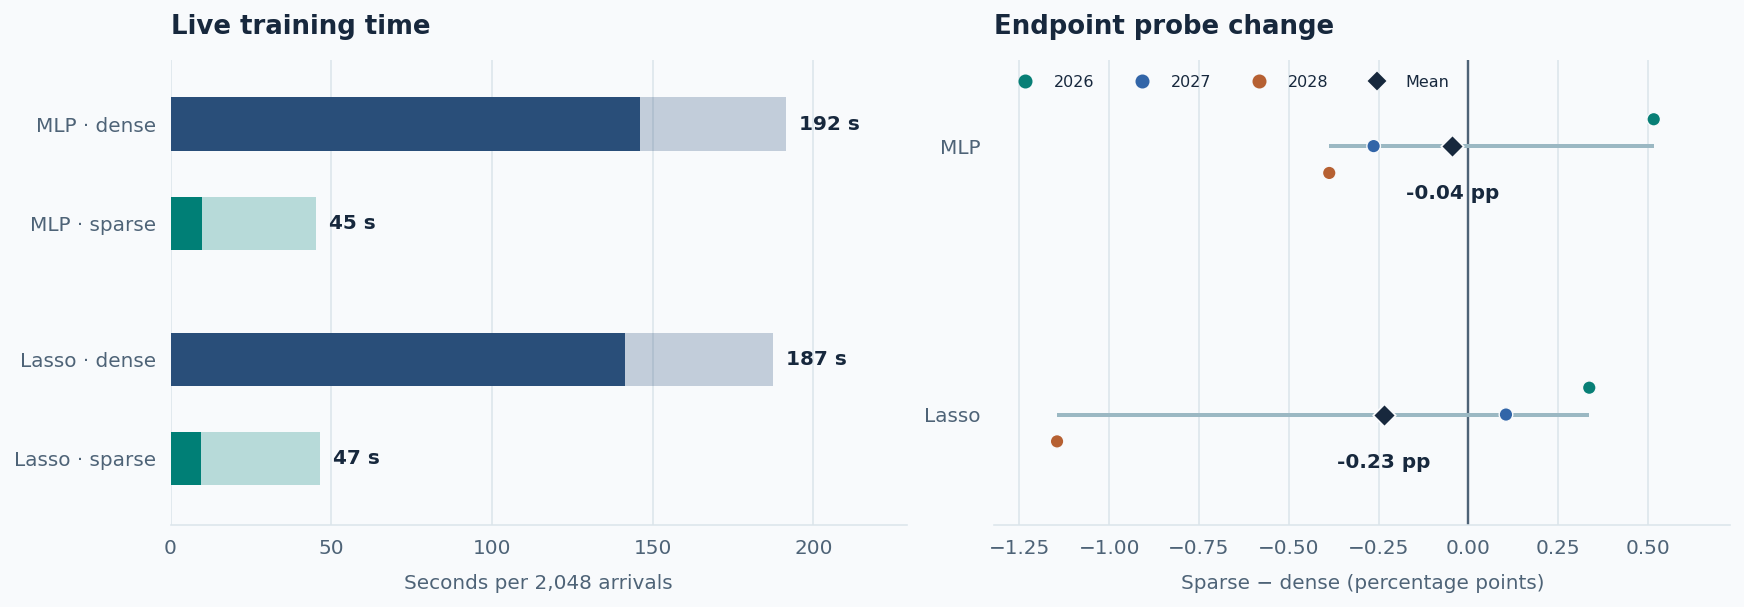

In [3]:
results = []
for model, cadence in arms:
    elapsed = mean_field(model, cadence, 'elapsed_seconds')
    feedback = np.mean([row['timing_seconds']['paired_feedback']
                        for row in arm_rows(model, cadence)])
    probe = mean_field(model, cadence, 'endpoint_probe_pct')
    results.append((model, cadence, f'{elapsed:.1f} s', f'{feedback:.1f} s', f'{probe:.2f}%'))
display(markdown_table(('Predictor', 'Feedback', 'Mean live time', 'Paired feedback time',
                        'Mean endpoint probe'), results))

ink, muted, grid, paper = '#17283d', '#4e6377', '#dce5eb', '#f8fafc'
dense_color, sparse_color = '#294e79', '#007f76'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': ink,
                     'axes.labelcolor': muted, 'xtick.color': muted, 'ytick.color': muted,
                     'axes.titleweight': 'bold', 'axes.facecolor': paper,
                     'figure.facecolor': paper, 'savefig.facecolor': paper})

def clean_axis(axis, title, xlabel):
    axis.set_title(title, loc='left', pad=13, fontsize=13, color=ink)
    axis.set_xlabel(xlabel, labelpad=8)
    axis.set_axisbelow(True)
    axis.grid(axis='x', color=grid, linewidth=0.8)
    axis.spines[['left', 'right', 'top']].set_visible(False)
    axis.spines['bottom'].set_color(grid)
    axis.tick_params(length=0, pad=7)

fig, (time_ax, probe_ax) = plt.subplots(1, 2, figsize=(12.0, 4.1), layout='constrained')
clean_axis(time_ax, 'Live training time', 'Seconds per 2,048 arrivals')
labels = ['MLP · dense', 'MLP · sparse', 'Lasso · dense', 'Lasso · sparse']
positions = (3.2, 2.25, 0.95, 0)
time_ax.set_yticks(positions, labels)
for pos, (model, cadence) in zip(positions, arms):
    total = mean_field(model, cadence, 'elapsed_seconds')
    feedback = np.mean([row['timing_seconds']['paired_feedback']
                        for row in arm_rows(model, cadence)])
    color = dense_color if cadence == 'dense' else sparse_color
    time_ax.barh(pos, feedback, height=0.51, color=color)
    time_ax.barh(pos, total-feedback, left=feedback, height=0.51, color=color, alpha=0.26)
    time_ax.text(total+4, pos, f'{total:.0f} s', va='center', color=ink, fontweight='bold')
time_ax.set(xlim=(0, 229), ylim=(-0.63, 3.81))
time_ax.xaxis.set_major_locator(MultipleLocator(50))

clean_axis(probe_ax, 'Endpoint probe change', 'Sparse − dense (percentage points)')
probe_ax.set_yticks((1, 0), ('MLP', 'Lasso'))
probe_ax.axvline(0, color=muted, linewidth=1.2)
seed_colors = ('#087f76', '#3265a8', '#b66032')
for pos, model in zip((1, 0), models):
    changes = np.array([rows[model, 'sparse', seed]['endpoint_probe_pct'] -
                        rows[model, 'dense', seed]['endpoint_probe_pct'] for seed in seeds])
    probe_ax.hlines(pos, changes.min(), changes.max(), color='#9bb8c3', linewidth=2)
    probe_ax.scatter(changes, pos + np.array([0.10, 0, -0.10]), c=seed_colors, s=46,
                     edgecolors=paper, linewidth=0.7, zorder=3)
    probe_ax.scatter(changes.mean(), pos, marker='D', color=ink, edgecolors=paper,
                     linewidth=0.9, s=64, zorder=4)
    probe_ax.annotate(f'{changes.mean():+.2f} pp', (changes.mean(), pos), (0, -19),
                      textcoords='offset points', ha='center', va='top', fontweight='bold')
probe_ax.set(xlim=(-1.32, 0.73), ylim=(-0.41, 1.32))
probe_ax.legend(handles=[Line2D([], [], marker='o', ls='', color=color, label=str(seed))
                         for seed, color in zip(seeds, seed_colors)] +
                        [Line2D([], [], marker='D', ls='', color=ink, label='Mean')],
                loc='upper left', ncol=4, frameon=False, fontsize=8)
plt.show()

Dark bars show time spent on paired feedback. The probe points show each seed and the diamond shows the mean. Sparse feedback used **93.7% fewer paired targets**. The remaining live monitoring and model updates limit the total speedup.

## Fixed-128 RankMe forecast quality

Each point below is the forecast issued at the audit origin and the observed +16 RankMe advantage over Skip. There are 384 shared audit origins per arm across the seeds and two non-skip action forecasts per origin. The diagonal marks perfect prediction. The horizontal zero line is the no-action-effect forecast. RMSE skill is the percentage reduction in pooled RMSE relative to that zero rule. Negative skill means higher error than the zero rule.

| Predictor | Feedback | Online RMSE | RankMe skill | Frozen fit skill | Online order agreement |
| --- | --- | --- | --- | --- | --- |
| MLP | dense | 0.01873 | +6.72% | +0.85% | 62.28% |
| MLP | sparse | 0.02089 | -6.61% | +1.61% | 56.64% |
| Multitask Lasso | dense | 0.01855 | +5.44% | +4.94% | 64.03% |
| Multitask Lasso | sparse | 0.01954 | +0.91% | -0.04% | 65.45% |

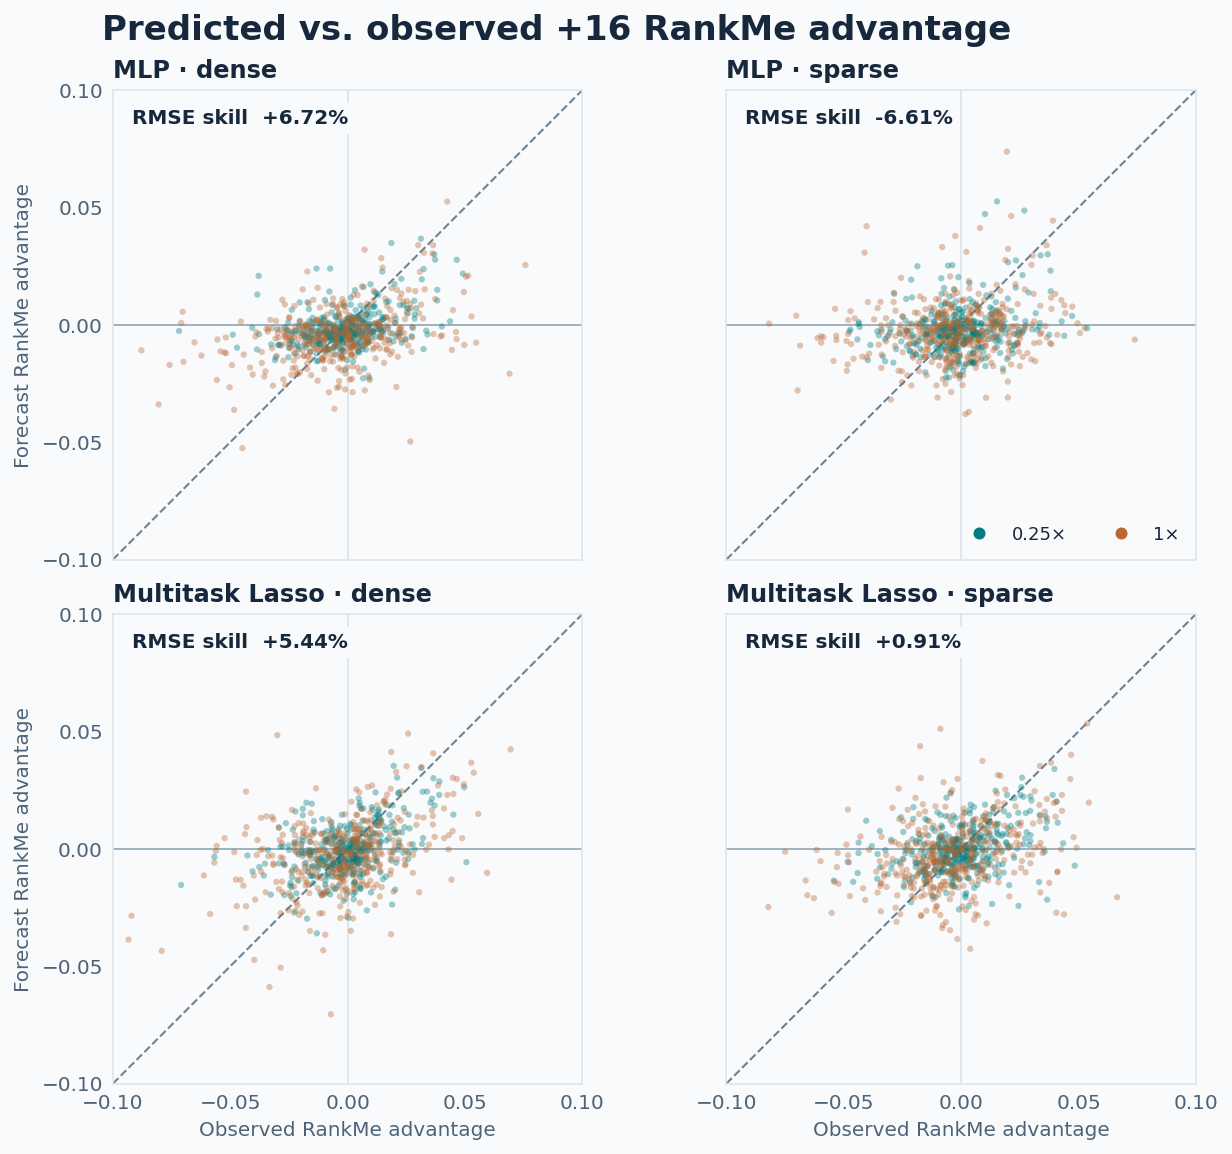

In [4]:
columns = ('Predictor', 'Feedback', 'Online RMSE', 'RankMe skill', 'Frozen fit skill',
           'Online order agreement')
scored = []
for model, cadence in arms:
    target, online, frozen = forecasts(model, cadence)
    rmse, skill, agreement = forecast_scores(target, online)
    _, frozen_skill, _ = forecast_scores(target, frozen)
    scored.append((model, cadence, f'{rmse:.5f}', f'{skill:+.2f}%',
                   f'{frozen_skill:+.2f}%', f'{agreement:.2f}%'))
display(markdown_table(columns, scored))

fig, axes = plt.subplots(2, 2, figsize=(8.8, 7.9), sharex=True, sharey=True,
                         layout='constrained')
fig.suptitle('Predicted vs. observed +16 RankMe advantage', x=0.08, ha='left',
             fontsize=17, fontweight='bold', color=ink)
limit = 0.10
action_colors = ('#007d80', '#b96833')
for ax, (model, cadence) in zip(axes.flat, arms):
    target, online, _ = forecasts(model, cadence)
    rmse, skill, _ = forecast_scores(target, online)
    ax.set_title(f'{model} · {cadence}', loc='left', fontsize=12)
    ax.plot([-limit, limit], [-limit, limit], color='#6e8394', linewidth=1.05,
            linestyle='--', zorder=1)
    ax.axhline(0, color='#9bb0bd', linewidth=0.95, zorder=1)
    ax.axvline(0, color=grid, linewidth=0.9, zorder=1)
    for action, color in enumerate(action_colors, start=1):
        ax.scatter(target[:, action], online[:, action], s=10, color=color, alpha=0.38,
                   edgecolors='none', zorder=2)
    ax.text(0.04, 0.96, f'RMSE skill  {skill:+.2f}%', transform=ax.transAxes, va='top',
            fontweight='bold', fontsize=10,
            bbox={'facecolor': paper, 'edgecolor': 'none', 'pad': 3})
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit))
    ax.set_aspect('equal', adjustable='box')
    ax.xaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    for spine in ax.spines.values():
        spine.set_color(grid)
    ax.tick_params(length=0, pad=5)
for ax in axes[:, 0]:
    ax.set_ylabel('Forecast RankMe advantage')
for ax in axes[1]:
    ax.set_xlabel('Observed RankMe advantage')
axes[0, 1].legend(handles=[
    Line2D([], [], marker='o', ls='', color=color, label=label, markersize=5)
    for color, label in zip(action_colors, ('0.25×', '1×'))
], loc='lower right', frameon=False, fontsize=9, ncol=2)
plt.show()

Pairwise agreement scores all three action pairs. Target gaps of at most 0.00001 are omitted and predicted ties receive half credit. The frozen-fit columns score the calibration predictors on the same states as the live runs. They give a forecast reference without introducing extra live controller arms.

## Per-seed results

The endpoint probes reflect each controller's own chosen action mix. The dense-to-sparse probe difference changes sign across seeds for both predictors, so the three-seed average can hide a larger single-seed swing.

In [5]:
columns = ('Predictor', 'Seed', 'Start probe', 'Dense endpoint', 'Sparse endpoint',
           'Sparse Δ', 'Dense / sparse time', 'Dense / sparse RankMe skill')
paired = []
for model in models:
    for seed in seeds:
        dense, sparse = (rows[model, cadence, seed] for cadence in cadences)
        start = dense['initial_probe_pct']
        d_probe, s_probe = (row['endpoint_probe_pct'] for row in (dense, sparse))
        speed = dense['elapsed_seconds'] / sparse['elapsed_seconds']
        d_skill, s_skill = (row['rank']['skill_pct'][0] for row in (dense, sparse))
        paired.append((model, str(seed), f'{start:.2f}%', f'{d_probe:.2f}%',
                       f'{s_probe:.2f}%', f'{s_probe-d_probe:+.2f} pp', f'{speed:.2f}×',
                       f'{d_skill:+.2f}% / {s_skill:+.2f}%'))
display(markdown_table(columns, paired))

| Predictor | Seed | Start probe | Dense endpoint | Sparse endpoint | Sparse Δ | Dense / sparse time | Dense / sparse RankMe skill |
| --- | --- | --- | --- | --- | --- | --- | --- |
| MLP | 2026 | 60.90% | 60.50% | 61.02% | +0.52 pp | 4.95× | -2.83% / -14.70% |
| MLP | 2027 | 60.19% | 60.66% | 60.40% | -0.26 pp | 3.85× | +15.82% / +2.49% |
| MLP | 2028 | 60.82% | 60.63% | 60.24% | -0.39 pp | 4.05× | +8.00% / -12.62% |
| Multitask Lasso | 2026 | 60.90% | 61.19% | 61.53% | +0.34 pp | 3.87× | +0.42% / -4.13% |
| Multitask Lasso | 2027 | 60.19% | 60.89% | 61.00% | +0.10 pp | 4.40× | +14.83% / +5.13% |
| Multitask Lasso | 2028 | 60.82% | 60.67% | 59.53% | -1.15 pp | 3.82× | +2.19% / +3.10% |

## Scope and provenance

This is a 2,048-arrival pilot on three seeds. The probes were measured at the shared start and at each arm's endpoint. The Fixed-128 RankMe forecast is a proxy, while the held-out probes measure representation quality for these five tasks. These runs leave the link between the control objective and downstream gain open.

The notebook includes its run receipts and saved outputs. Re-executing the analysis cells requires Python, NumPy and Matplotlib. The [runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/run_sparse_rank16.py), [MLP summary](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/sparse-rank16-live/paired-pilot-2048/summary.json) and [Lasso summary](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/sparse-rank16-live/lasso-paired-pilot-2048/summary.json) are in the experiment workspace. Use the GPU runner with `--predictor mlp` or `--predictor multitask-lasso` to resume the corresponding results directory.